# Statistical Analysis and Visualization of Maize Production in Zambia Using Python

## 1. Introduction

This notebook presents an exploratory data analysis of maize production in Zambia from 1961 to 2024.

The analysis uses historical agricultural data obtained from FAOSTAT. It focuses on maize production, harvested area, and yield.

### Objectives

1. Examine the structure and quality of the dataset.
2. Calculate descriptive statistics.
3. Analyse historical maize production trends.
4. Investigate relationships between harvested area, yield, and production.
5. Create visualizations to communicate findings.

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned maize production dataset
df = pd.read_csv("../../data/maize_production.csv")

# Display the first five observations
df.head()

,Year,Area_harvested_ha,Production_tonnes,Yield_kg_per_ha,Yield_tonnes_per_ha,Area_harvested_flag,Production_flag,Yield_flag
0,1961,750000.0,660000.0,880.0,0.8800,E,E,E
1,1962,750000.0,640000.0,853.3,0.8533,E,E,E
2,1963,770000.0,570000.0,740.3,0.7403,E,E,E
3,1964,790000.0,660000.0,835.4,0.8354,E,E,E
4,1965,800000.0,700000.0,875.0,0.8750,E,E,E


In [4]:
# Display dataset dimensions
print("Dataset dimensions: - maize_analysis.ipynb:2", df.shape)

# Display column names
print("\nColumn names: - maize_analysis.ipynb:5")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information: - maize_analysis.ipynb:9")
df.info()

Dataset dimensions: - maize_analysis.ipynb:2 (64, 8)

Column names: - maize_analysis.ipynb:5
['Year', 'Area_harvested_ha', 'Production_tonnes', 'Yield_kg_per_ha', 'Yield_tonnes_per_ha', 'Area_harvested_flag', 'Production_flag', 'Yield_flag']

Dataset information: - maize_analysis.ipynb:9
<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 64 non-null     int64  
 1   Area_harvested_ha    64 non-null     float64
 2   Production_tonnes    64 non-null     float64
 3   Yield_kg_per_ha      64 non-null     float64
 4   Yield_tonnes_per_ha  64 non-null     float64
 5   Area_harvested_flag  64 non-null     str    
 6   Production_flag      64 non-null     str    
 7   Yield_flag           64 non-null     str    
dtypes: float64(4), int64(1), str(3)
memory usage: 4.3 KB


In [5]:
# Calculate descriptive statistics
statistics = df[
    [
        "Area_harvested_ha",
        "Production_tonnes",
        "Yield_kg_per_ha"
    ]
].describe()

# Display results
statistics

,Area_harvested_ha,Production_tonnes,Yield_kg_per_ha
count,6.400000e+01,6.400000e+01,64.000000
mean,8.094339e+05,1.460921e+06,1752.275000
std,2.590740e+05,8.758340e+05,637.469405
min,3.627870e+05,4.834920e+05,633.300000
25%,5.952130e+05,8.170420e+05,1344.500000
50%,7.666385e+05,1.132844e+06,1717.550000
75%,1.001832e+06,1.855486e+06,2300.025000
max,1.433944e+06,3.620244e+06,3031.000000


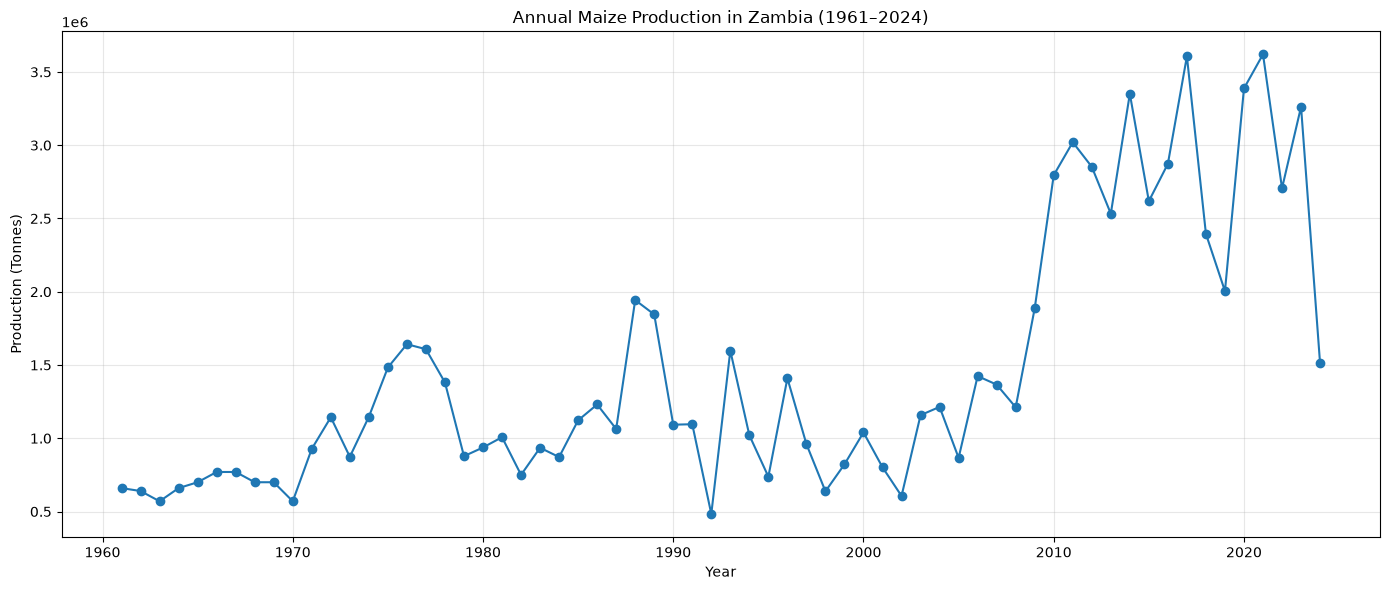

In [6]:
# Plot maize production over time
plt.figure(figsize=(14, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    marker="o",
    linewidth=1.5
)

plt.title("Annual Maize Production in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Production (Tonnes)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Annual Maize Production Trends

The visualization reveals considerable fluctuations in Zambia's
maize production between 1961 and 2024.

Key observations include:

1. Production generally increased over the long term.
2. Significant fluctuations occurred between 1990 and 2008.
3. Production reached relatively high levels between 2009 and 2023.
4. A substantial decline occurred in 2024 compared with 2023.

These observations suggest that maize production has experienced
both periods of growth and periods of decline.

Further analysis is required to investigate the relationship
between production, harvested area and agricultural yield.

In [7]:
# Identify the year with the highest production
highest = df.loc[df["Production_tonnes"].idxmax()]

# Identify the year with the lowest production
lowest = df.loc[df["Production_tonnes"].idxmin()]

print("HIGHEST MAIZE PRODUCTION")
print("Year:", int(highest["Year"]))
print("Production:", round(highest["Production_tonnes"], 2), "tonnes")

print("\nLOWEST MAIZE PRODUCTION")
print("Year:", int(lowest["Year"]))
print("Production:", round(lowest["Production_tonnes"], 2), "tonnes")

HIGHEST MAIZE PRODUCTION
Year: 2021
Production: 3620243.9 tonnes

LOWEST MAIZE PRODUCTION
Year: 1992
Production: 483492.0 tonnes


In [8]:
# Extract production values for 2023 and 2024
production_2023 = df.loc[
    df["Year"] == 2023, "Production_tonnes"
].values[0]

production_2024 = df.loc[
    df["Year"] == 2024, "Production_tonnes"
].values[0]

# Calculate absolute and percentage change
absolute_change = production_2024 - production_2023

percentage_change = (
    (production_2024 - production_2023)
    / production_2023
) * 100

print("Production in 2023: - maize_analysis.ipynb:18", round(production_2023, 2), "tonnes")
print("Production in 2024: - maize_analysis.ipynb:19", round(production_2024, 2), "tonnes")

print("\nAbsolute change: - maize_analysis.ipynb:21", round(absolute_change, 2), "tonnes")
print("Percentage change: - maize_analysis.ipynb:22", round(percentage_change, 2), "%")

Production in 2023: - maize_analysis.ipynb:18 3261685.68 tonnes
Production in 2024: - maize_analysis.ipynb:19 1511143.43 tonnes

Absolute change: - maize_analysis.ipynb:21 -1750542.25 tonnes
Percentage change: - maize_analysis.ipynb:22 -53.67 %


### Analysis of the 2023–2024 Production Decline

A comparison of maize production in 2023 and 2024 revealed
a substantial decline.

- Production in 2023: 3,261,685.68 tonnes.
- Production in 2024: 1,511,143.43 tonnes.
- Absolute decline: 1,750,542.25 tonnes.
- Percentage decline: 53.67%.

This represents an approximately 54% reduction in maize
production between the two years.

Both observations carry the FAOSTAT official-figure flag (A).

Further investigation is necessary to determine the extent
to which changes in harvested area and agricultural yield
contributed to this decline.

In [9]:
# Extract 2023 and 2024 observations
data_2023 = df[df["Year"] == 2023].iloc[0]
data_2024 = df[df["Year"] == 2024].iloc[0]

# Compare harvested area
area_change = (
    (data_2024["Area_harvested_ha"] -
     data_2023["Area_harvested_ha"])
    / data_2023["Area_harvested_ha"]
) * 100

# Compare yield
yield_change = (
    (data_2024["Yield_kg_per_ha"] -
     data_2023["Yield_kg_per_ha"])
    / data_2023["Yield_kg_per_ha"]
) * 100

print("HARVESTED AREA")
print("2023:", data_2023["Area_harvested_ha"], "ha")
print("2024:", data_2024["Area_harvested_ha"], "ha")
print("Percentage change:", round(area_change, 2), "%")

print("\nAGRICULTURAL YIELD")
print("2023:", data_2023["Yield_kg_per_ha"], "kg/ha")
print("2024:", data_2024["Yield_kg_per_ha"], "kg/ha")
print("Percentage change:", round(yield_change, 2), "%")

HARVESTED AREA
2023: 1418369.0 ha
2024: 684402.0 ha
Percentage change: -51.75 %

AGRICULTURAL YIELD
2023: 2299.6 kg/ha
2024: 2208.0 kg/ha
Percentage change: -3.98 %


### Investigation of the 2024 Production Decline

To investigate the substantial decline in maize production
between 2023 and 2024, harvested area and agricultural yield
were compared.

The findings were:

1. Harvested area decreased by 51.75%.
2. Agricultural yield decreased by 3.98%.
3. Total maize production decreased by 53.67%.

The results indicate that the reduction in harvested area
was much larger than the reduction in yield.

Therefore, the decline in harvested area appears to have
been the dominant factor associated with the reduction
in maize production in 2024.

However, further investigation using additional agricultural
and environmental data would be necessary to establish the
underlying causes.

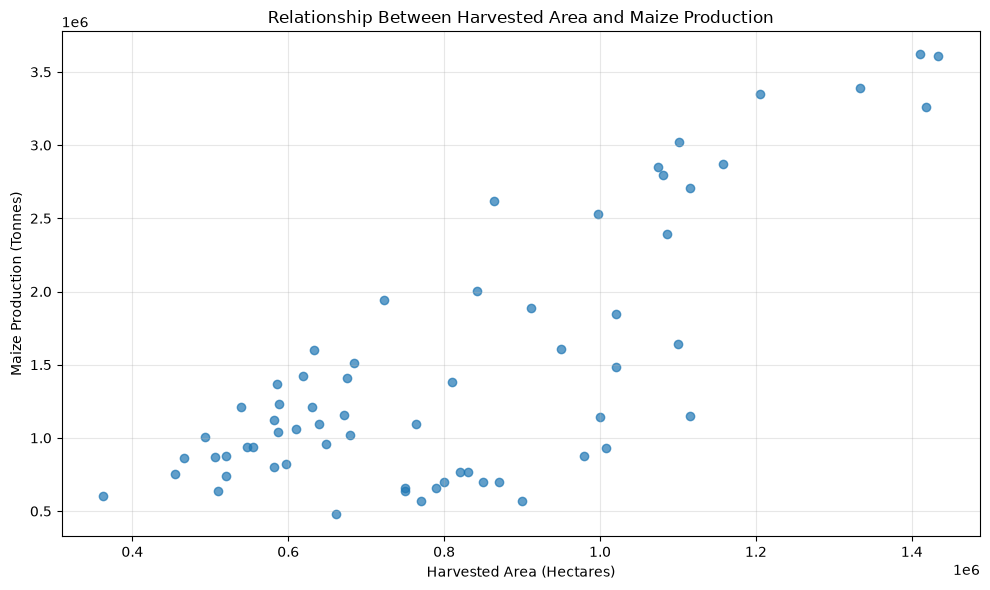

In [12]:
# Create a scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Area_harvested_ha"],
    df["Production_tonnes"],
    alpha=0.7
)

plt.title("Relationship Between Harvested Area and Maize Production")
plt.xlabel("Harvested Area (Hectares)")
plt.ylabel("Maize Production (Tonnes)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Relationship Between Harvested Area and Maize Production

The scatter plot illustrates a positive relationship between harvested area and maize production in Zambia from 1961 to 2024.

The main observations are:

1. **Positive relationship:** Maize production generally increases as the harvested area increases.
2. **Variation in production:** Observations with similar harvested areas sometimes record considerably different production levels.
3. **Different productivity levels:** Some years achieve higher production than others despite having comparable harvested areas. This suggests that agricultural yield also contributes to variations in total production.
4. **High production levels:** Years with larger harvested areas generally record higher maize production.

The scatter plot suggests that harvested area is an important factor associated with maize production in Zambia. However, the variation among observations indicates that harvested area alone does not explain all changes in production.

These findings describe an association rather than a causal relationship.

A Pearson correlation analysis will be conducted next to quantify the strength and direction of the linear relationship between harvested area and maize production.

In [13]:
# Calculate Pearson correlation
area_production_corr = df["Area_harvested_ha"].corr(
    df["Production_tonnes"]
)

print(
    "Correlation between harvested area and maize production:",
    round(area_production_corr, 3)
)

Correlation between harvested area and maize production: 0.771


### Interpretation of Pearson Correlation Analysis

The Pearson correlation coefficient was calculated to measure the strength and direction of the linear relationship between harvested area and maize production in Zambia.

The analysis produced a correlation coefficient of **0.771**.

This indicates a strong positive linear relationship between the two variables.

The findings suggest that:

1. Larger harvested areas are generally associated with higher maize production.
2. Changes in harvested area are strongly associated with variations in total maize output.
3. Harvested area is an important factor associated with maize production in Zambia.
4. Other factors, particularly agricultural yield, may also contribute to changes in production.

The positive correlation supports the observations made in the scatter plot.

However, correlation does not imply causation. The result only establishes an association between harvested area and maize production over the period 1961–2024.

Further analysis will examine the relationship between agricultural yield and maize production.

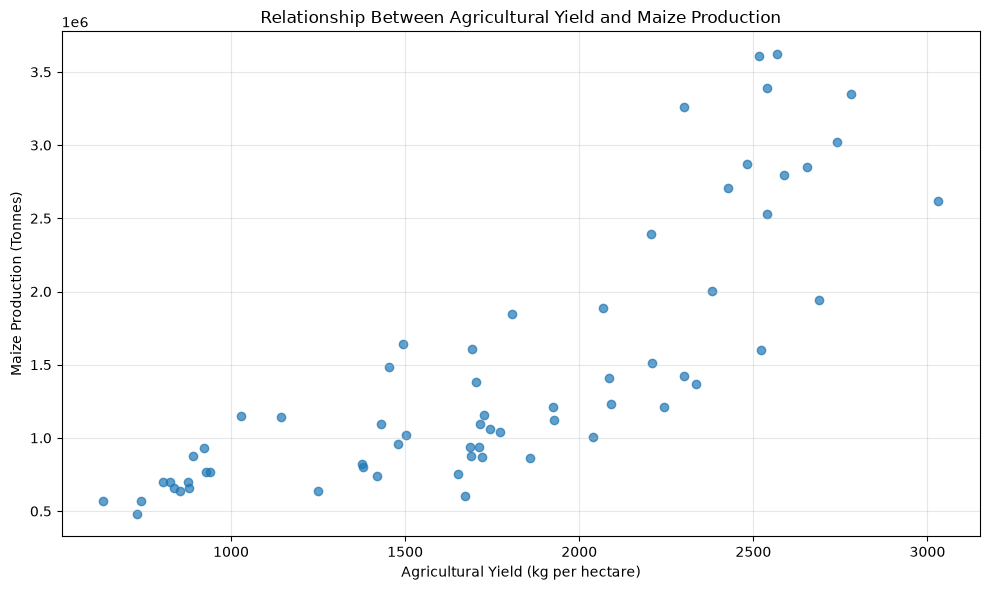

In [14]:
# Create a scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Yield_kg_per_ha"],
    df["Production_tonnes"],
    alpha=0.7
)

plt.title("Relationship Between Agricultural Yield and Maize Production")
plt.xlabel("Agricultural Yield (kg per hectare)")
plt.ylabel("Maize Production (Tonnes)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Relationship Between Agricultural Yield and Maize Production

The scatter plot illustrates a positive relationship between agricultural yield and total maize production in Zambia from 1961 to 2024.

The main observations are:

1. **Positive relationship:** Higher agricultural yields generally correspond to higher total maize production.
2. **Low-yield observations:** Years with yields between approximately 600 and 1,000 kg/ha generally recorded relatively low maize production.
3. **High-yield observations:** Higher yields, particularly above 2,300 kg/ha, are generally associated with higher production levels.
4. **Variation in production:** Considerable differences in total production occur even among observations with similar yields.
5. **Unusual observations:** Some years have relatively high yields but do not record equally high total production.

The findings suggest that agricultural yield is an important factor associated with maize production in Zambia.

However, yield alone does not determine total production because the amount of land harvested also contributes to total output.

This observation supports the earlier finding that both harvested area and agricultural yield are important when examining changes in maize production.

The relationship observed in the scatter plot represents an association rather than proof of causation.

A Pearson correlation analysis will be conducted next to quantify the strength and direction of the linear relationship between agricultural yield and maize production.

In [15]:
yield_production_corr = df["Yield_kg_per_ha"].corr(
    df["Production_tonnes"]
)

print(
    "Correlation between agricultural yield and maize production:",
    round(yield_production_corr, 3)
)

Correlation between agricultural yield and maize production: 0.803


### Interpretation of Pearson Correlation Analysis

The Pearson correlation coefficient was calculated to measure the strength and direction of the linear relationship between agricultural yield and maize production in Zambia.

The analysis produced a correlation coefficient of **0.803**.

This indicates a strong positive linear relationship between the two variables.

The findings suggest that:

1. Higher agricultural yields are generally associated with higher maize production.
2. Agricultural yield is an important factor associated with variations in total maize output.
3. Differences in harvested area may also contribute to variations in production, even when yields are similar.
4. The positive correlation supports the observations made in the scatter plot.

Comparing the two correlation results:

- Harvested area and production: **0.771**.
- Agricultural yield and production: **0.803**.

Both variables demonstrate strong positive relationships with maize production. In this dataset, yield has a slightly higher Pearson correlation coefficient than harvested area.

However, these results establish associations rather than causal relationships. They also do not independently measure the contribution of each variable to total production.

Further analysis will examine the relationships among all three agricultural variables.

In [16]:
correlation_matrix = df[
    ["Area_harvested_ha", "Yield_kg_per_ha", "Production_tonnes"]
].corr()

correlation_matrix

,Area_harvested_ha,Yield_kg_per_ha,Production_tonnes
Area_harvested_ha,1.000000,0.261864,0.771331
Yield_kg_per_ha,0.261864,1.000000,0.802862
Production_tonnes,0.771331,0.802862,1.000000


### Interpretation of the Correlation Matrix

The correlation matrix presents the Pearson correlation coefficients between harvested area, agricultural yield and total maize production in Zambia from 1961 to 2024.

The following relationships were observed:

1. **Harvested area and maize production (0.771):** This indicates a strong positive relationship. Years with larger harvested areas generally tend to record higher maize production.

2. **Agricultural yield and maize production (0.803):** This indicates a strong positive relationship. Higher agricultural yields are generally associated with higher total maize production.

3. **Harvested area and agricultural yield (0.262):** This indicates a weak positive relationship. Changes in harvested area are only weakly associated with changes in agricultural yield.

### Overall Findings

Both harvested area and agricultural yield demonstrate strong positive relationships with total maize production.

Agricultural yield has a slightly higher correlation coefficient (0.803) than harvested area (0.771).

The relatively weak correlation between harvested area and yield (0.262) suggests that the two variables do not necessarily increase or decrease together.

These findings highlight the importance of examining both harvested area and agricultural yield when analysing maize production in Zambia.

However, correlation coefficients measure association and should not be interpreted as evidence of causation.

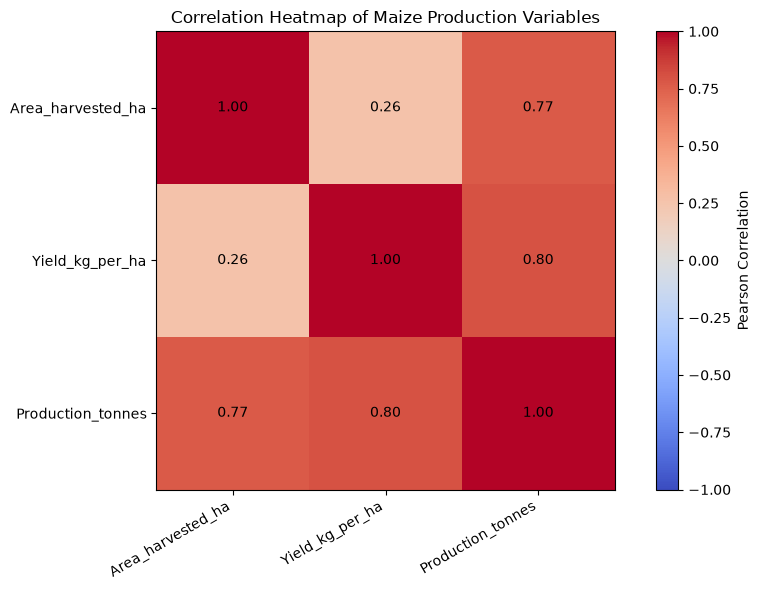

In [17]:
plt.figure(figsize=(9, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Correlation Heatmap of Maize Production Variables")
plt.tight_layout()
plt.show()

### Interpretation of the Correlation Heatmap

The correlation heatmap illustrates the Pearson correlation coefficients between harvested area, agricultural yield and total maize production in Zambia from 1961 to 2024.

The following relationships were identified:

1. **Harvested area and maize production (r = 0.771):** This indicates a strong positive linear relationship. Years with larger harvested areas generally tend to record higher maize production.

2. **Agricultural yield and maize production (r = 0.803):** This also indicates a strong positive linear relationship. Higher agricultural yields are generally associated with higher total maize production.

3. **Harvested area and agricultural yield (r = 0.262):** This indicates a weak positive linear relationship. The two variables are only weakly associated over the period studied.

### Overall Findings

The results indicate that both harvested area and agricultural yield are strongly associated with total maize production.

The difference between the two production correlations (0.803 and 0.771) is relatively small. Therefore, the results do not provide sufficient evidence to conclude that one variable is more important than the other.

The weak correlation between harvested area and yield suggests that changes in these two variables do not necessarily occur together.

Agricultural production is determined by both the area harvested and the yield obtained per hectare. Consequently, examining both variables provides a more complete understanding of changes in maize production.

### Limitations

The correlation matrix has several limitations:

1. Correlation measures association and does not establish causation.
2. Pearson correlation measures linear relationships and may not fully capture non-linear patterns.
3. The dataset contains annual observations, meaning that time trends and relationships between consecutive years may influence the results.
4. Unusual observations may affect the calculated correlation coefficients.
5. The analysis does not establish the individual contribution of harvested area and yield to changes in total production.

### Conclusion

The correlation analysis demonstrates strong positive relationships between maize production and both harvested area and agricultural yield in Zambia from 1961 to 2024.

The findings highlight the importance of considering both land utilization and agricultural productivity when examining maize production.

Further statistical analysis is necessary to investigate these relationships more deeply and account for the time-series nature of the dataset.

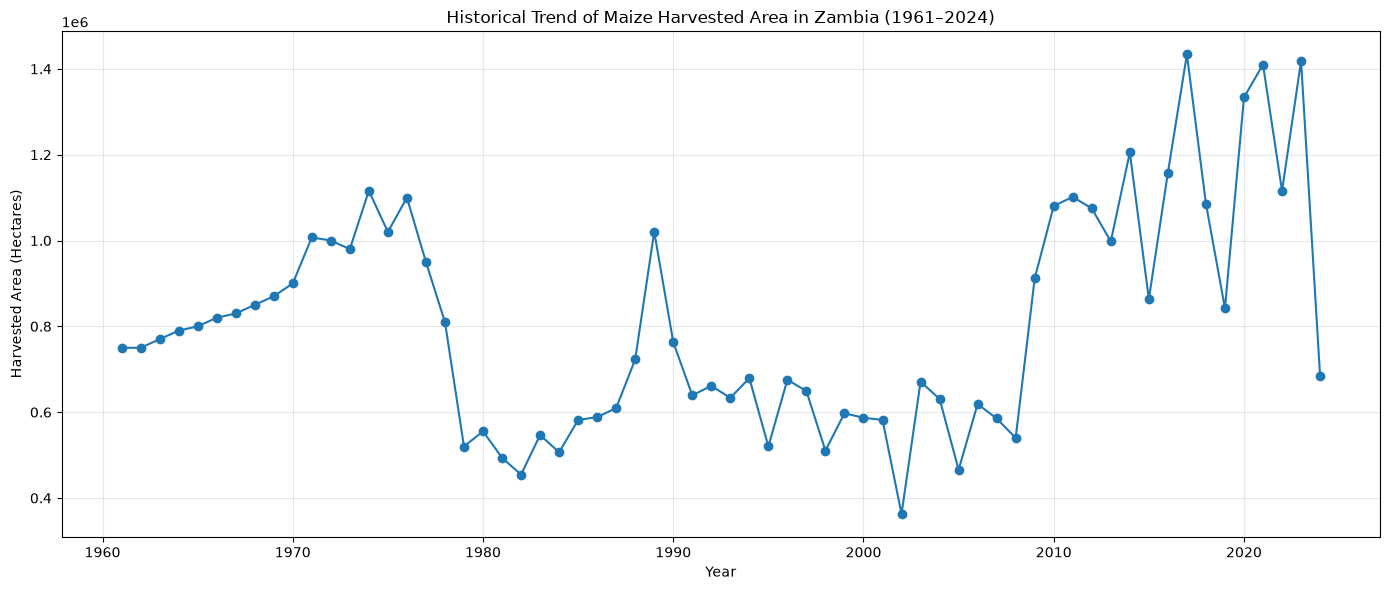

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Year"],
    df["Area_harvested_ha"],
    marker="o",
    linewidth=1.5
)

plt.title("Historical Trend of Maize Harvested Area in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Harvested Area (Hectares)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Historical Trend of Maize Harvested Area

The line graph illustrates changes in the area harvested for maize production in Zambia between 1961 and 2024.

The main observations can be divided into four broad historical phases:

1. **Gradual expansion (1961–mid-1970s):** Harvested area generally increased from approximately 750,000 hectares to over 1 million hectares.

2. **Sharp decline (late 1970s–early 1980s):** A considerable reduction in harvested area occurred following the expansion period.

3. **Moderate fluctuations (mid-1980s–2008):** Harvested area remained relatively low, with several fluctuations and occasional increases.

4. **Expansion and increased volatility (2009–2024):** Harvested area generally reached higher levels, although considerable year-to-year fluctuations occurred.

### Recent Trends (2020–2024)

The recent observations reveal considerable changes in harvested area:

- 2020: 1,333,519 hectares.
- 2021: 1,410,102 hectares.
- 2022: 1,115,489 hectares.
- 2023: 1,418,369 hectares.
- 2024: 684,402 hectares.

A particularly significant decline occurred in 2024, when harvested area decreased by approximately 51.75% compared with 2023.

This represents a substantial reduction in the land harvested for maize production.

### Relationship with Maize Production

The historical pattern is consistent with the earlier correlation analysis, which identified a strong positive relationship between harvested area and maize production (r = 0.771).

Generally, larger harvested areas are associated with higher total maize production.

However, changes in harvested area do not necessarily translate into proportional changes in production because agricultural yield also contributes to total output.

### Limitations

The visualization has several limitations:

1. It shows changes in harvested area but does not establish the causes of those changes.
2. It does not include other factors such as rainfall, agricultural inputs or economic conditions.
3. The graph cannot distinguish between planted land and land successfully harvested.
4. Historical fluctuations may be influenced by changes in agricultural conditions and data quality.
5. The identified historical phases are descriptive observations and have not been confirmed using formal time-series methods.

### Conclusion

The analysis shows that maize harvested area in Zambia experienced considerable fluctuations between 1961 and 2024.

Although the period from 2009 onwards generally recorded higher harvested areas, the substantial decline in 2024 demonstrates the variability of agricultural land utilization.

The findings reinforce the importance of harvested area in understanding changes in maize production, while highlighting the need to examine agricultural yield alongside land utilization.

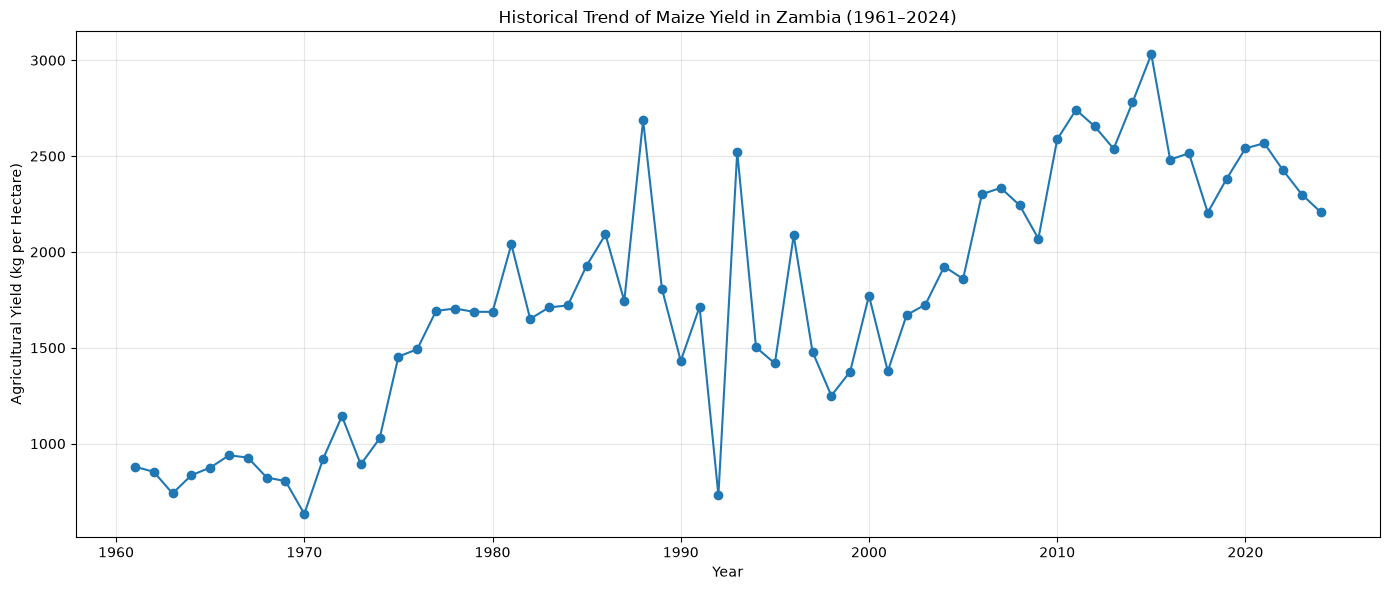

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Year"],
    df["Yield_kg_per_ha"],
    marker="o",
    linewidth=1.5
)

plt.title("Historical Trend of Maize Yield in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Agricultural Yield (kg per Hectare)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Historical Trend of Maize Yield in Zambia (1961–2024)

The line graph illustrates changes in maize agricultural yield in Zambia between 1961 and 2024, measured in kilograms per hectare (kg/ha).

### 1. Overall Trend

The graph reveals a long-term upward tendency in maize yield over the 64-year period.

Yield increased from below 1,000 kg/ha in the early 1960s to above 2,000 kg/ha in recent decades.

However, this improvement was not continuous. The series experienced considerable fluctuations, including several periods of sharp increases and declines.

### 2. Historical Patterns

The historical trend can be divided into several broad phases:

1. **1961–1970:** Yield remained relatively low, generally below 1,000 kg/ha, reaching a particularly low level around 1970.

2. **1971–1985:** A considerable improvement in yield occurred, followed by a period of relatively high and more stable productivity.

3. **1986–2001:** Yield experienced substantial fluctuations, including sharp declines and recoveries. The early 1990s were particularly unstable.

4. **2002–2015:** Yield generally improved, reaching its highest observed level around 2015.

5. **2016–2024:** Yield fluctuated but generally followed a downward tendency after its peak.

These phases represent descriptive observations from the graph rather than formally established structural changes.

### 3. Highest and Lowest Yield Levels

The graph indicates that:

- The highest yield occurred around 2015, reaching approximately 3,030 kg/ha.
- The lowest yield occurred around 1970, at approximately 640 kg/ha.
- Another particularly low observation occurred around 1992.

These observations demonstrate the considerable variation in maize productivity throughout the study period.

### 4. Recent Trends (2020–2024)

The recent observations reveal a gradual decline in agricultural yield after 2021.

- 2020: 2,540.20 kg/ha.
- 2021: 2,567.40 kg/ha.
- 2022: 2,426.10 kg/ha.
- 2023: 2,299.60 kg/ha.
- 2024: 2,208.00 kg/ha.

Yield declined in each of the three consecutive years between 2021 and 2024.

This indicates a reduction in maize productivity per hectare during the period.

However, the decline does not establish a permanent reversal of the long-term upward trend.

### 5. Relationship with Maize Production

The earlier Pearson correlation analysis identified a strong positive relationship between agricultural yield and total maize production (r = 0.803).

The historical yield trend is consistent with this finding, as periods of relatively high yield generally overlap with periods of higher maize production.

However, yield alone does not determine total production.

Total maize production depends on both harvested area and agricultural yield. Consequently, a year with high yield may still record relatively low production if the harvested area is small.

The correlation therefore describes an association rather than a direct causal relationship.

### 6. Relationship with Harvested Area

Agricultural yield measures the amount of maize produced per hectare, whereas harvested area measures the total land from which maize is harvested.

An increase in yield can therefore increase total production without requiring an increase in harvested area.

The earlier correlation analysis identified a relatively weak positive relationship between harvested area and yield (r = 0.262).

This suggests that changes in harvested area and agricultural yield do not necessarily occur together.

Consequently, both variables must be considered when examining changes in total maize production.

### 7. Limitations

The analysis has several limitations:

1. The graph does not establish the causes of changes in agricultural yield.
2. Factors such as rainfall, drought, fertiliser availability, seed varieties and farming practices are not included.
3. National-level observations conceal differences between agricultural regions and farming systems.
4. Unusual observations may reflect actual agricultural conditions or possible data estimation and recording differences.
5. The identified historical phases are visual observations and have not been confirmed using formal time-series methods.
6. The analysis does not account for possible autocorrelation or other time-series characteristics.

### Conclusion

The analysis demonstrates a long-term improvement in maize yield in Zambia between 1961 and 2024, although considerable fluctuations occurred throughout the period.

Yield reached its highest observed level around 2015 before experiencing fluctuations and a gradual decline in recent years.

The strong positive correlation between yield and maize production (r = 0.803) highlights the importance of agricultural productivity when examining total maize output.

Furthermore, the relatively weak relationship between harvested area and yield (r = 0.262) demonstrates that changes in land utilization do not necessarily correspond to changes in productivity.

Overall, the findings highlight the importance of examining both harvested area and agricultural yield to understand historical changes in maize production in Zambia.

In [20]:
df["Production_Change_Percent"] = (
    df["Production_tonnes"].pct_change() * 100
)

df[["Year", "Production_tonnes", "Production_Change_Percent"]].head(10)

,Year,Production_tonnes,Production_Change_Percent
0,1961,660000.0,NaN
1,1962,640000.0,-3.030303
2,1963,570000.0,-10.937500
3,1964,660000.0,15.789474
4,1965,700000.0,6.060606
5,1966,770000.0,10.000000
6,1967,770000.0,0.000000
7,1968,700000.0,-9.090909
8,1969,700000.0,0.000000
9,1970,570000.0,-18.571429


In [21]:
largest_increases = df.nlargest(
    5, "Production_Change_Percent"
)[["Year", "Production_Change_Percent"]]

largest_decreases = df.nsmallest(
    5, "Production_Change_Percent"
)[["Year", "Production_Change_Percent"]]

print("TOP 5 LARGEST ANNUAL INCREASES - maize_analysis.ipynb:9")
display(largest_increases)

print("\nTOP 5 LARGEST ANNUAL DECREASES - maize_analysis.ipynb:12")
display(largest_decreases)

TOP 5 LARGEST ANNUAL INCREASES - maize_analysis.ipynb:9


,Year,Production_Change_Percent
32,1993,230.463999
35,1996,91.029837
42,2003,91.011792
27,1988,82.727992
59,2020,69.002572



TOP 5 LARGEST ANNUAL DECREASES - maize_analysis.ipynb:12


,Year,Production_Change_Percent
31,1992,-55.882063
63,2024,-53.669863
29,1990,-40.775933
18,1979,-36.437433
33,1994,-36.114027


### Interpretation of the Largest Annual Changes in Maize Production

The analysis identified the five largest annual increases and decreases in maize production in Zambia between 1961 and 2024.

### 1. Largest Annual Increases

The five largest annual increases were:

1. **1993:** 230.46%.
2. **1996:** 91.03%.
3. **2003:** 91.01%.
4. **1988:** 82.73%.
5. **2020:** 69.00%.

The largest increase occurred in 1993, when maize production increased by approximately 230.46% compared with the previous year.

This represents a substantial recovery in production following the significant decline recorded in 1992.

### 2. Largest Annual Decreases

The five largest annual decreases were:

1. **1992:** -55.88%.
2. **2024:** -53.67%.
3. **1990:** -40.78%.
4. **1979:** -36.44%.
5. **1994:** -36.11%.

The largest decrease occurred in 1992, when maize production declined by approximately 55.88% compared with 1991.

The second-largest decline occurred in 2024, demonstrating another substantial reduction in maize production.

### 3. Important Observations

Several important patterns emerged:

- Maize production experienced considerable year-to-year fluctuations throughout the study period.
- The sharp decline in 1992 was followed by an exceptional increase in 1993.
- Significant production increases also occurred in 1996, 2003, 1988 and 2020.
- The 2024 decline represents one of the largest annual reductions recorded in the dataset.

### 4. Limitations

These percentage changes describe variations in annual production but do not establish the causes of those changes.

Factors such as rainfall, drought, harvested area, agricultural inputs and farming practices may influence maize production.

Further investigation using additional agricultural and environmental data would be necessary to identify the underlying explanations.

### Conclusion

The analysis demonstrates that maize production in Zambia has experienced substantial year-to-year fluctuations between 1961 and 2024.

The exceptionally large changes recorded in 1992 and 1993 highlight the volatility of agricultural production.

The findings also demonstrate the importance of examining annual percentage changes alongside long-term production trends when analysing agricultural performance.

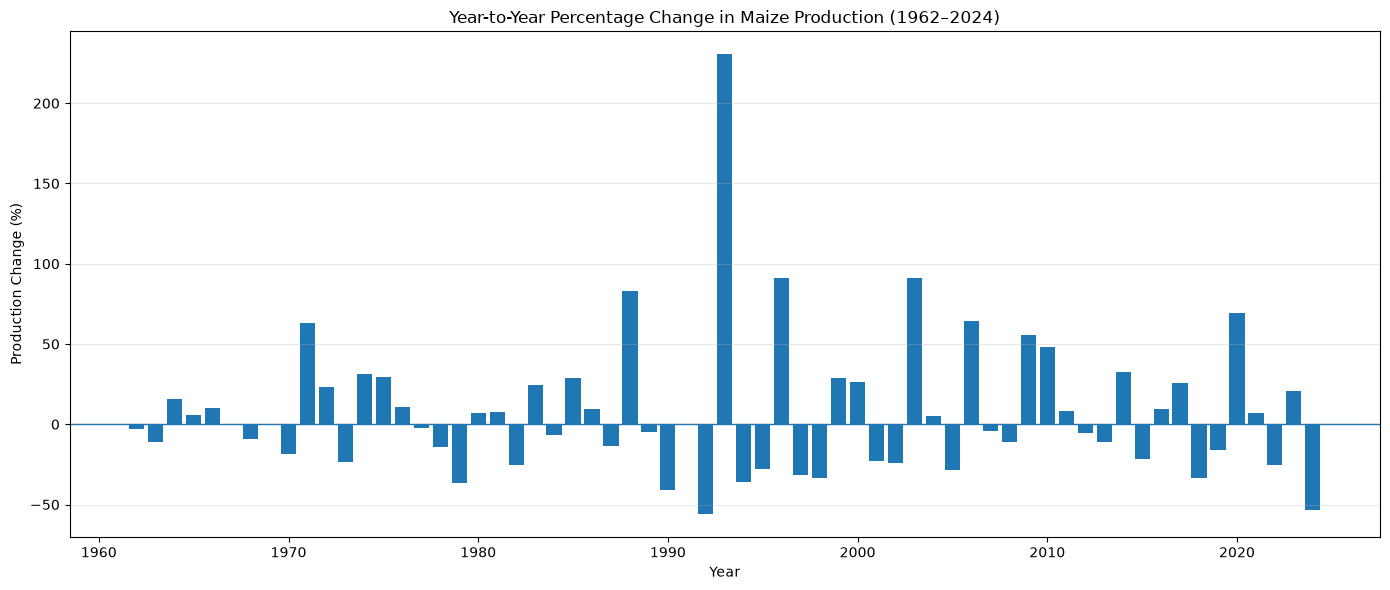

In [22]:
plt.figure(figsize=(14, 6))

plt.bar(
    df["Year"],
    df["Production_Change_Percent"],
    width=0.8
)

plt.axhline(y=0, linewidth=1)

plt.title("Year-to-Year Percentage Change in Maize Production (1962–2024)")
plt.xlabel("Year")
plt.ylabel("Production Change (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Year-to-Year Percentage Change in Maize Production in Zambia (1962–2024)

The bar chart illustrates annual percentage changes in maize production in Zambia between 1962 and 2024.

Positive values represent increases in production, while negative values represent decreases compared with the preceding year.

### 1. Overall Pattern

The visualization reveals considerable year-to-year fluctuations in maize production throughout the study period.

Production alternated frequently between increases and decreases, indicating that agricultural output did not follow a consistent upward or downward pattern every year.

Most annual changes were relatively moderate, although several years experienced exceptionally large increases and decreases.

The chart also demonstrates that positive percentage changes can be considerably larger than negative changes because percentage increases have no fixed upper limit, whereas percentage decreases cannot exceed 100%.

### 2. Periods of Production Volatility

Several periods of considerable production fluctuations can be identified:

1. **1962–1970:** Annual changes were generally moderate, although some declines and increases occurred.

2. **1970s–1980s:** Production experienced larger fluctuations, including substantial increases and declines.

3. **1990s–early 2000s:** This period recorded particularly significant fluctuations, including several consecutive years of large production changes.

4. **2010–2024:** Production continued to experience considerable fluctuations, with some years recording substantial increases followed by significant declines.

The 1990s and early 2000s appear particularly volatile based on the visual observations.

### 3. Largest Annual Changes

The analysis identified the following significant changes:

**Largest annual increases:**

- 1993: 230.46%.
- 1996: 91.03%.
- 2003: 91.01%.
- 1988: 82.73%.
- 2020: 69.00%.

The largest increase occurred in 1993, when production increased by approximately 230.46% compared with 1992.

This means production was approximately 3.30 times its previous year's level.

**Largest annual decreases:**

- 1992: -55.88%.
- 2024: -53.67%.
- 1990: -40.78%.
- 1979: -36.44%.
- 1994: -36.11%.

The largest decline occurred in 1992, when maize production decreased by approximately 55.88%.

### 4. The 1992–1993 Production Fluctuation

An important observation is the substantial decline in production in 1992, followed by an exceptionally large increase in 1993.

The 1992 decline of 55.88% was followed by a 230.46% increase in 1993.

This demonstrates how percentage changes can be influenced by the production level in the preceding year.

The unusually large increase in 1993 should therefore be interpreted in the context of the exceptionally low production recorded in 1992.

The earlier yield analysis also revealed substantial fluctuations around this period.

However, the underlying causes of these changes cannot be established from the available visualizations alone.

### 5. Recent Production Changes (2020–2024)

The recent observations demonstrate continued instability in maize production.

The main changes were:

- 2020: Production increased by approximately 69.00%.
- 2021: Production increased by approximately 6.87%.
- 2022: Production decreased by approximately 25.24%.
- 2023: Production increased by approximately 20.51%.
- 2024: Production decreased by approximately 53.67%.

The most significant recent observation is the substantial decline recorded in 2024.

This finding supports the earlier analysis, which identified 2024 as a year of considerable reduction in total maize production.

### 6. Relationship with Harvested Area and Agricultural Yield

The earlier analysis established strong positive relationships between maize production and its two main components:

- Harvested area and production: r = 0.771.
- Agricultural yield and production: r = 0.803.

The 2024 production decline can be examined further using these variables.

Between 2023 and 2024:

- Harvested area decreased by 51.75%.
- Agricultural yield decreased by 3.98%.
- Total maize production decreased by 53.67%.

The substantially larger reduction in harvested area suggests that it was the dominant factor associated with the decline in production.

This comparison reinforces the importance of considering both harvested area and agricultural yield when analysing changes in maize production.

### 7. Limitations

The analysis has several limitations:

1. Percentage changes describe relative variations rather than absolute production levels.
2. Large percentage increases may partly result from unusually low production in the preceding year.
3. The visualization does not establish the causes of production fluctuations.
4. Factors such as rainfall, drought, agricultural inputs and farming practices are not included.
5. The identified periods of high volatility are descriptive observations and have not been confirmed using formal statistical tests.
6. National-level figures conceal differences between agricultural regions and farming systems.

Further investigation using climatic, economic and agricultural input data would help explain the observed fluctuations.

### Conclusion

The analysis demonstrates that maize production in Zambia experienced considerable year-to-year fluctuations between 1961 and 2024.

The largest annual decline occurred in 1992, followed by an exceptional increase in 1993. Another substantial decline occurred in 2024.

The findings demonstrate that examining annual percentage changes provides additional insight into agricultural production patterns beyond what can be observed from long-term production trends alone.

Furthermore, the comparison of harvested area and agricultural yield highlights the importance of examining both variables when investigating changes in total maize production.

In [23]:
df["Production_5Year_MA"] = (
    df["Production_tonnes"]
    .rolling(window=5)
    .mean()
)

df[["Year", "Production_tonnes", "Production_5Year_MA"]].head(12)

,Year,Production_tonnes,Production_5Year_MA
0,1961,660000.0,NaN
1,1962,640000.0,NaN
2,1963,570000.0,NaN
3,1964,660000.0,NaN
4,1965,700000.0,646000.0
5,1966,770000.0,668000.0
6,1967,770000.0,694000.0
7,1968,700000.0,720000.0
8,1969,700000.0,728000.0
9,1970,570000.0,702000.0


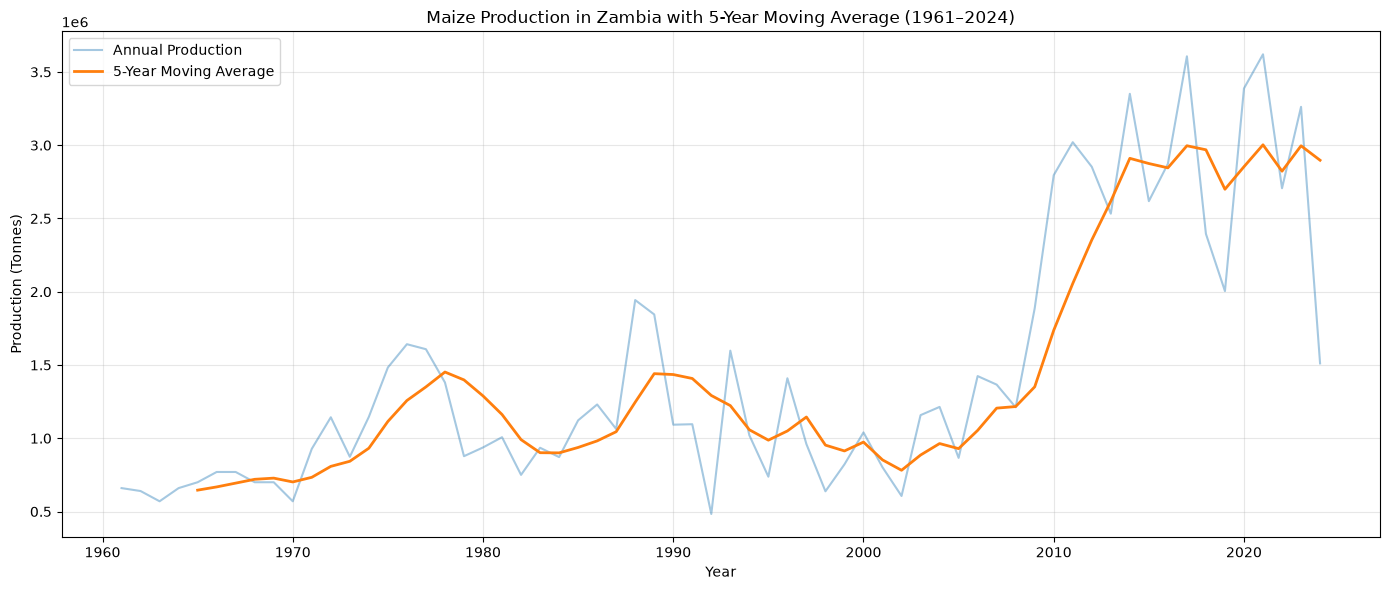

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    alpha=0.4,
    label="Annual Production"
)

plt.plot(
    df["Year"],
    df["Production_5Year_MA"],
    linewidth=2,
    label="5-Year Moving Average"
)

plt.title("Maize Production in Zambia with 5-Year Moving Average (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Production (Tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Maize Production with a 5-Year Moving Average (1961–2024)

The graph compares annual maize production with a trailing 5-year moving average. Each moving average value represents the mean production of the current year and the four preceding years. Therefore, the moving average begins in 1965 and represents a smoothed measure rather than actual recorded production.

Annual maize production shows considerable fluctuations throughout the period. The moving average smooths these short-term changes and reveals the broader historical pattern.

Several important trends can be observed:

1. Production generally increased during the 1970s, reaching a local peak towards the end of the decade.
2. A period of decline followed during the late 1970s and early 1980s.
3. Another period of growth occurred towards the end of the 1980s, followed by a prolonged period of relatively low production.
4. From approximately 2009, the moving average increased substantially, indicating a shift towards higher production levels.
5. From the mid-2010s onwards, the moving average remained relatively high, although annual production continued to fluctuate.

The moving average is particularly useful because it reduces the influence of individual annual spikes and declines, making longer-term production patterns easier to identify.

An important observation concerns the sharp decline in annual production in 2024. Production decreased from 3,261,685.68 tonnes in 2023 to 1,511,143.43 tonnes in 2024, representing a decline of approximately 53.67%.

However, the 5-year moving average for 2024 remains approximately 2.90 million tonnes. This is because it includes the relatively high production figures recorded between 2020 and 2023. Consequently, the moving average reduces the visual impact of the substantial decline in 2024.

### Limitations of the Moving Average

Although the 5-year moving average helps identify long-term trends, it has some limitations:

1. It responds more slowly to sudden changes because it uses observations from previous years.
2. It can hide important short-term fluctuations and extreme production changes.
3. The first four years do not have moving average values because a complete five-year window is required.
4. The results depend on the selected window size.
5. Moving average values are calculated estimates and should not be confused with actual recorded production.
6. The visualization identifies trends but does not establish the causes of changes in maize production.

Overall, the 5-year moving average provides a useful summary of the long-term behaviour of maize production in Zambia. It complements the annual production graph by highlighting broader trends while reducing short-term fluctuations.

##  Statistical Trend Analysis Using Linear Regression

Linear regression is used to examine the long-term relationship between year and maize production.

The analysis estimates the direction and magnitude of the production trend over the period 1961–2024.

The regression slope, coefficient of determination (R-squared), and p-value will be used to interpret the results.

In [25]:
from scipy.stats import linregress

trend_model = linregress(
    df["Year"],
    df["Production_tonnes"]
)

print("LINEAR REGRESSION TREND ANALYSIS")
print("--------------------------------")
print("Slope:", round(trend_model.slope, 2), "tonnes per year")
print("Intercept:", round(trend_model.intercept, 2))
print("R-squared:", round(trend_model.rvalue ** 2, 4))
print("P-value:", trend_model.pvalue)
print("Correlation:", round(trend_model.rvalue, 4))

LINEAR REGRESSION TREND ANALYSIS
--------------------------------
Slope: 33996.51 tonnes per year
Intercept: -66277117.65
R-squared: 0.5223
P-value: 1.5568828059280965e-11
Correlation: 0.7227


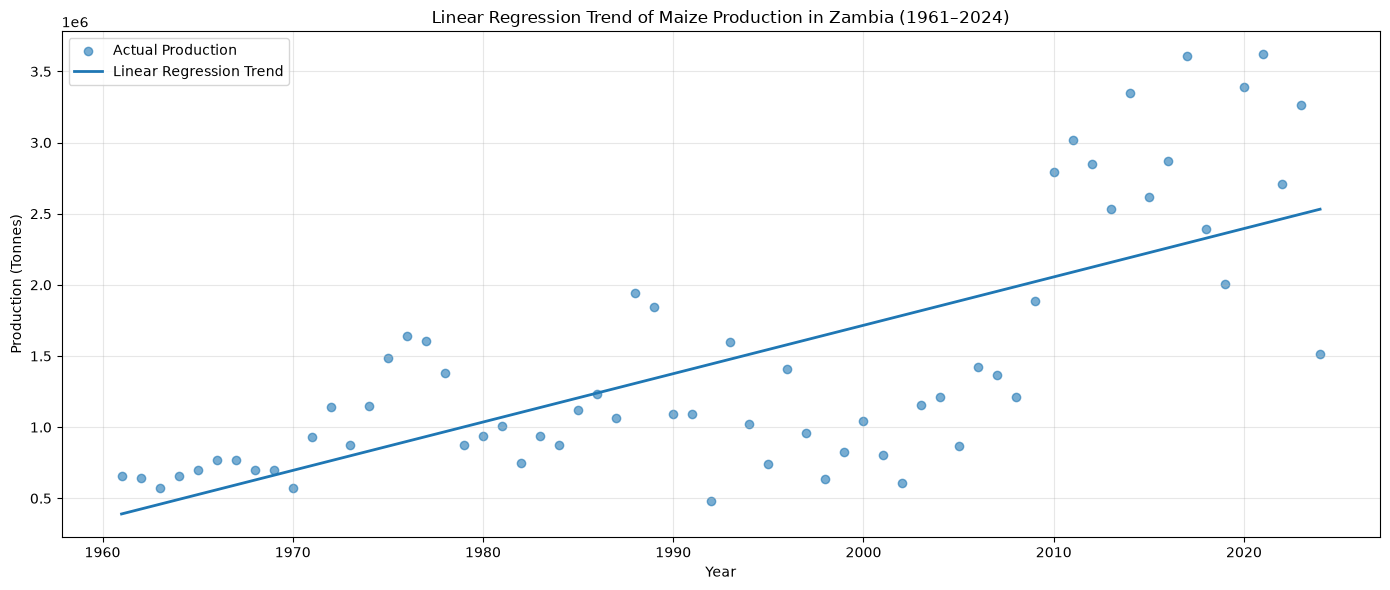

In [26]:
plt.figure(figsize=(14, 6))

plt.scatter(
    df["Year"],
    df["Production_tonnes"],
    alpha=0.6,
    label="Actual Production"
)

plt.plot(
    df["Year"],
    trend_model.intercept + trend_model.slope * df["Year"],
    linewidth=2,
    label="Linear Regression Trend"
)

plt.title("Linear Regression Trend of Maize Production in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Production (Tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Linear Regression Trend of Maize Production in Zambia (1961–2024)

The graph presents annual maize production alongside a fitted linear regression trend line. The regression line slopes upwards, indicating a positive long-term relationship between time and maize production in Zambia.

The estimated **slope is 33,996.51 tonnes per year**. This means that the fitted regression line increases by approximately 34,000 tonnes for each additional year. Across the 63-year interval from 1961 to 2024, this represents an estimated increase of approximately 2.14 million tonnes along the fitted line.

However, this is an average trend and does not mean that production actually increased by this amount every year. The intercept (-66,277,117.65) represents the model's estimated production at year zero and has no practical interpretation within the study period.

The **R-squared value of 0.5223** indicates that approximately 52.23% of the variation in annual maize production is accounted for by the fitted linear time trend. The remaining variation is not explained by this simple linear model.

The correlation coefficient (r = 0.7227) indicates a strong positive linear association between year and production. Furthermore, the **p-value of approximately 1.56 × 10⁻¹¹** is considerably smaller than the conventional significance level of 0.05. This provides strong statistical evidence of a non-zero linear trend under the assumptions of the regression model.

The actual production values are scattered around the fitted regression line, showing that the model captures the general direction of the trend but does not explain all the annual fluctuations.

Some notable observations include:

1. Production was generally above the fitted trend during parts of the 1970s.
2. Several observations between approximately 1990 and 2008 were below the fitted trend.
3. Production was generally higher during much of the 2010s.
4. The 2024 production value was substantially below the fitted trend, reflecting the sharp decline observed in that year.

### Limitations of the Linear Regression Model

Although linear regression provides useful information about the long-term trend, several limitations should be considered:

1. The model assumes a constant linear rate of change, whereas the historical data shows periods of different growth and decline.
2. The model uses year as its only explanatory variable and does not include factors such as harvested area, agricultural yield, rainfall or farming inputs.
3. Annual observations may exhibit autocorrelation, meaning that production in one year may be related to production in previous years. This can affect the reliability of conventional regression significance tests.
4. Changes in production variability over time may also affect the model's assumptions.
5. Extreme observations may influence the fitted regression line.
6. The model describes an association between time and production but does not establish the causes of production changes.

**Conclusion:** The linear regression analysis identifies a statistically significant positive long-term trend in maize production in Zambia between 1961 and 2024. However, the moderate R-squared value and considerable fluctuations around the regression line demonstrate that a simple linear model cannot fully describe the historical behaviour of maize production. Additional statistical methods and explanatory variables would be useful for further investigation.

In [27]:
df["Predicted_Production"] = (
    trend_model.intercept +
    trend_model.slope * df["Year"]
)

df["Residuals"] = (
    df["Production_tonnes"] -
    df["Predicted_Production"]
)

df[["Year", "Production_tonnes", "Predicted_Production", "Residuals"]].head(10)

,Year,Production_tonnes,Predicted_Production,Residuals
0,1961,660000.0,390031.352029,269968.647971
1,1962,640000.0,424027.858403,215972.141597
2,1963,570000.0,458024.364777,111975.635223
3,1964,660000.0,492020.871151,167979.128849
4,1965,700000.0,526017.377525,173982.622475
5,1966,770000.0,560013.883899,209986.116101
6,1967,770000.0,594010.390273,175989.609727
7,1968,700000.0,628006.896647,71993.103353
8,1969,700000.0,662003.403022,37996.596978
9,1970,570000.0,695999.909396,-125999.909396


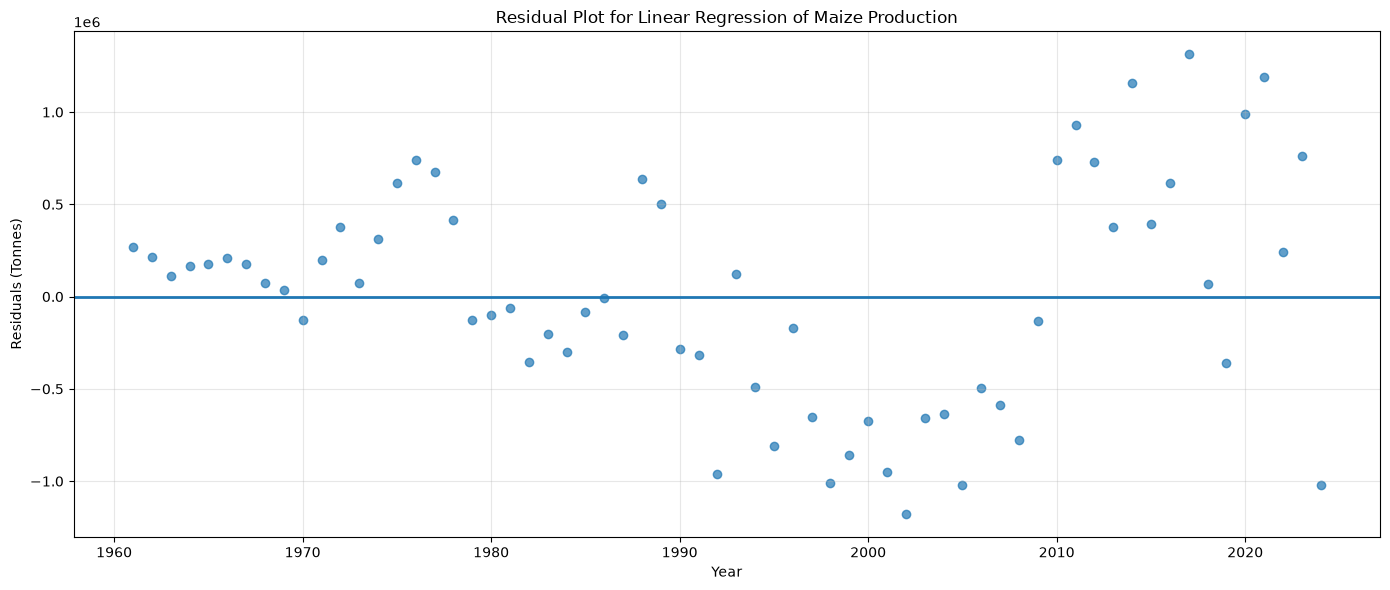

In [28]:
plt.figure(figsize=(14, 6))

plt.scatter(
    df["Year"],
    df["Residuals"],
    alpha=0.7
)

plt.axhline(y=0, linewidth=2)

plt.title("Residual Plot for Linear Regression of Maize Production")
plt.xlabel("Year")
plt.ylabel("Residuals (Tonnes)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Residual Plot for Linear Regression of Maize Production (1961–2024)

The residual plot shows the difference between actual and predicted maize production (Residual = Actual − Predicted) for each year. Positive residuals indicate that actual production exceeded the model's prediction, and negative residuals indicate that it fell below it. If the linear model were adequate, residuals would scatter randomly around zero with roughly constant spread.

The residuals do **not** appear randomly distributed. They occur in long runs of the same sign. Residuals are mostly positive in the 1960s and from about 1971 to 1978, mostly negative from about 1979 to 1987, positive around 1988–1989, **persistently negative from about 1990 to 2008**, and **predominantly positive from about 2010 to 2023**. In 2024 the residual is large and negative, indicating production far below the fitted trend. The largest positive residuals appear in the 2010s and early 2020s, with the most extreme near 2017, while some of the largest negative residuals occur around 1992, 2002, 2005 and 2024.

The **spread of the residuals also appears to increase over time**: points lie close to zero in the 1960s but range much more widely after about 2010. This suggests possible non-constant variance (heteroscedasticity).

These patterns indicate that a single straight line does not fully describe the data. Although the regression captures the overall upward direction (slope = 33,996.51 tonnes per year; R² = 0.5223; p ≈ 1.56 × 10⁻¹¹), the systematic residual pattern suggests a non-linear trend or structural change, such as a low-production period before about 2008 followed by a marked rise. Because the data are annual time-series observations, consecutive errors may also be related (autocorrelation). This cannot be confirmed from visual inspection alone, but if present it would mean that the reported p-value overstates the strength of the evidence.

**Conclusion.** The residual plot suggests that the simple linear model is a useful summary of the broad long-term direction but is not an adequate description of the data. Formal diagnostics, such as the Durbin-Watson test, the Breusch-Pagan test and a residual ACF plot, are needed to confirm autocorrelation and heteroscedasticity. Alternative approaches, such as segmented regression, additional explanatory variables, or time-series models, may provide a better fit and more reliable inference.

In [30]:
from statsmodels.stats.stattools import durbin_watson

dw_statistic = durbin_watson(df["Residuals"])

print("DURBINWATSON TEST - maize_analysis.ipynb:5")
print("")
print("DurbinWatson statistic: - maize_analysis.ipynb:7", round(dw_statistic, 4))

DURBINWATSON TEST - maize_analysis.ipynb:5

DurbinWatson statistic: - maize_analysis.ipynb:7 0.7444


### Durbin–Watson Test for Autocorrelation

The Durbin–Watson test was used to investigate whether consecutive residuals from the linear regression model were correlated.

The test produced a Durbin–Watson statistic of **0.7444**.

The statistic ranges from 0 to 4, with a value close to 2 suggesting little first-order autocorrelation. Values below 2 suggest positive autocorrelation, while values above 2 suggest negative autocorrelation.

The obtained value of 0.7444 indicates substantial positive autocorrelation in the regression residuals. This suggests that consecutive prediction errors tend to be related rather than independent.

This finding supports the visual observations from the residual plot, which showed extended periods of positive and negative residuals.

**Conclusion:** The residuals exhibit evidence of positive autocorrelation. Therefore, the independence assumption of the ordinary least squares regression model may be violated. This limits the reliability of conventional regression inference, including the reported p-value. Further investigation using time-series methods or an alternative regression model may be appropriate.

In [31]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# Prepare the independent variable
X = sm.add_constant(df["Year"])

# Perform the Breusch-Pagan test
bp_test = het_breuschpagan(df["Residuals"], X)

print("BREUSCH-PAGAN TEST")
print("------------------")
print("LM Statistic:", round(bp_test[0], 4))
print("LM p-value:", round(bp_test[1], 6))
print("F Statistic:", round(bp_test[2], 4))
print("F p-value:", round(bp_test[3], 6))

BREUSCH-PAGAN TEST
------------------
LM Statistic: 19.9319
LM p-value: 8e-06
F Statistic: 28.0425
F p-value: 2e-06


### Breusch–Pagan Test for Heteroscedasticity

The Breusch–Pagan test was conducted to determine whether the residuals from the linear regression model have constant variance.

The hypotheses were:

- **Null hypothesis (H₀):** The residuals have constant variance (homoscedasticity).
- **Alternative hypothesis (H₁):** The residuals have non-constant variance (heteroscedasticity).

The test produced the following results:

- LM Statistic: 19.9319
- LM p-value: 0.000008
- F Statistic: 28.0425
- F p-value: 0.000002

At a significance level of 0.05, both p-values are considerably smaller than the significance level.

Therefore, the null hypothesis is rejected.

The results provide statistically significant evidence of heteroscedasticity, indicating that the variance of the regression residuals is not constant.

**Conclusion:** The constant variance assumption of ordinary least squares regression is violated. Consequently, conventional regression standard errors and statistical inference may be unreliable. This finding supports the visual observations from the residual plot, which suggested that residual spread changes over time.

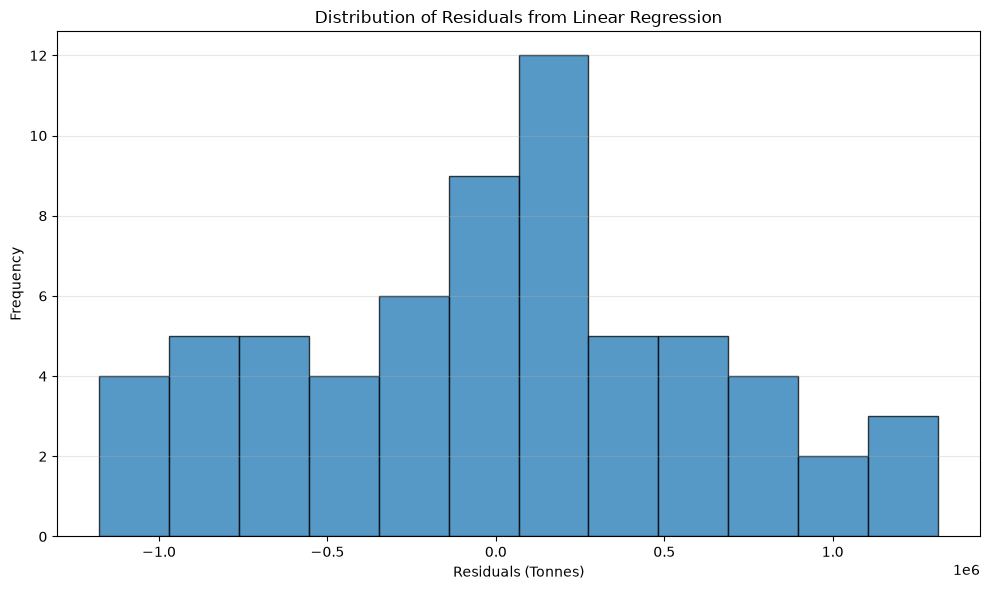

In [32]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Residuals"],
    bins=12,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of Residuals from Linear Regression")
plt.xlabel("Residuals (Tonnes)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Distribution of Residuals from Linear Regression

The histogram shows the distribution of the residuals from the regression of maize production on year. The distribution is **unimodal**, with a central peak close to zero and frequencies that decline towards both tails. It is **broad and flat-shouldered** rather than sharply bell-shaped, and the bar heights are somewhat irregular. This is partly consistent with approximate normality, but the heavy tails and uneven shape mean that normality is not clearly supported.

The distribution appears **roughly symmetric**, with residuals extending to a similar distance on both sides of zero. There may be slightly more weight in the lower tail, but this is a visual impression only. **No isolated extreme residuals** are visible. The outermost bins each contain several observations, so large departures from the fitted line are a regular feature of the data and not the result of a few outliers.

From the histogram alone, the normality assumption does not appear to be severely violated, but this should be confirmed with a formal test (such as Shapiro–Wilk or Jarque–Bera) and a Q-Q plot. Because the histogram pools all years and ignores their order, it cannot reveal **autocorrelation** and does not contradict the Durbin–Watson statistic (0.7444), which suggests positive autocorrelation. The pooling may also contribute to the broad shape of the distribution, because it combines small residuals from earlier years with larger residuals from later years, consistent with the heteroscedasticity indicated by the Breusch–Pagan test (p = 0.000008).

**Conclusion.** The residual histogram does not show a serious departure from normality, but it provides only limited evidence for it. The main weaknesses of the model are autocorrelation and heteroscedasticity. They mean that the reported standard errors, confidence intervals and p-value for the slope (p ≈ 1.56 × 10⁻¹¹) should be treated with caution and may overstate the strength of the evidence. The slope remains a useful descriptive summary of the long-term average trend. For more reliable inference, further analysis could use heteroscedasticity- and autocorrelation-consistent (Newey–West) standard errors, segmented regression, or time-series models.

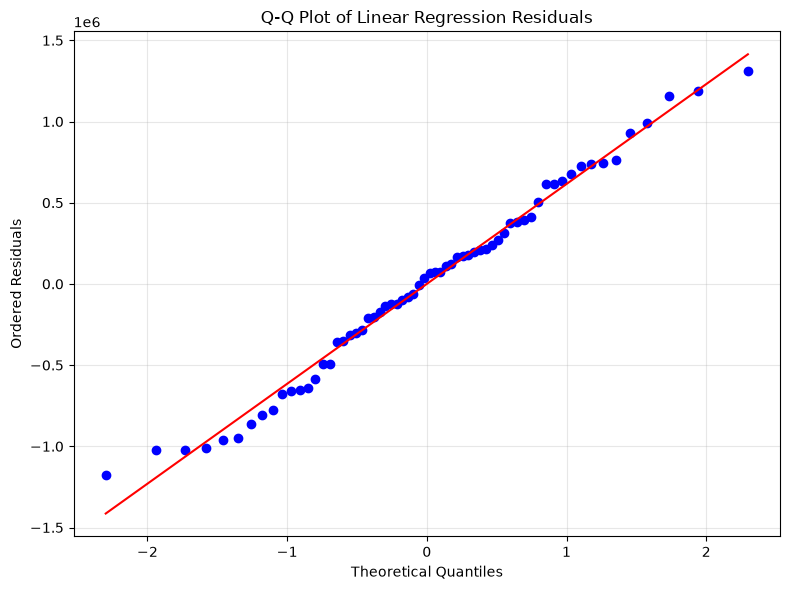

In [33]:
import scipy.stats as stats

plt.figure(figsize=(8, 6))

stats.probplot(
    df["Residuals"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Linear Regression Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Residuals")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Normal Q-Q Plot of Regression Residuals

The Q-Q plot compares the ordered regression residuals with the quantiles expected under a normal distribution. If the residuals were approximately normal, the points would lie close to the reference line.

The points follow the reference line **closely through the central part of the plot**, where most observations lie, with departures mainly near the ends. In the lower tail, the lowest residuals lie above the line, and in the upper tail the highest residuals lie on or slightly below it. This produces a **mild S-shaped pattern**, suggesting that the residuals have somewhat **lighter tails than a normal distribution**. There is no strong curvature, which suggests no pronounced skewness, and no point lies far from the line, so **no clear extreme outliers** are visible. These observations agree with the broad, flat-shouldered shape of the residual histogram.

Visually, the plot gives **no strong evidence against the normality assumption**, but this is a visual judgement and does not prove normality. A formal test, such as the Shapiro–Wilk test, should be used to complement it, and its result should be interpreted cautiously because the residuals show signs of autocorrelation.

The Q-Q plot ignores the time order of observations and the changing spread of residuals over time, so it cannot detect **autocorrelation** (Durbin–Watson = 0.7444) or **heteroscedasticity** (Breusch–Pagan p = 0.000008). These remain the main weaknesses of the model. They mean that the standard errors, confidence intervals and p-value for the slope (p ≈ 1.56 × 10⁻¹¹) should be treated with caution, even though normality does not appear to be a serious concern.

**Conclusion.** The residuals appear approximately normal with mildly light tails, so non-normality is unlikely to be the main threat to the model. The more serious issues are serial dependence and non-constant variance, and further analysis using robust (Newey–West) standard errors, segmented regression, or time-series models is recommended.

In [34]:
from scipy.stats import shapiro

shapiro_statistic, shapiro_pvalue = shapiro(df["Residuals"])

print("SHAPIRO-WILK NORMALITY TEST")
print("---------------------------")
print("W Statistic:", round(shapiro_statistic, 4))
print("P-value:", round(shapiro_pvalue, 6))

SHAPIRO-WILK NORMALITY TEST
---------------------------
W Statistic: 0.9829
P-value: 0.518417


### Shapiro–Wilk Test for Normality

The Shapiro–Wilk test was performed to investigate whether the residuals from the linear regression model follow an approximately normal distribution.

The hypotheses were:

- **Null hypothesis (H₀):** The regression residuals follow a normal distribution.
- **Alternative hypothesis (H₁):** The regression residuals do not follow a normal distribution.

The test produced the following results:

- Shapiro–Wilk W Statistic: 0.9829
- P-value: 0.518417

At a significance level of 0.05, the p-value is greater than the significance level.

Therefore, we fail to reject the null hypothesis.

The results indicate that there is insufficient statistical evidence to conclude that the regression residuals depart from a normal distribution.

This finding is consistent with the Q-Q plot, where most observations followed the reference line reasonably closely.

However, failure to reject the null hypothesis does not prove normality. Furthermore, the previously identified positive autocorrelation may affect the reliability of the test's p-value.

**Conclusion:** The Shapiro–Wilk test does not identify a statistically significant departure from normality. Therefore, non-normality does not appear to be the main weakness of the regression model. Autocorrelation and heteroscedasticity remain the more important diagnostic concerns.

In [35]:
import statsmodels.api as sm

# Prepare the regression variables
X = sm.add_constant(df["Year"])
y = df["Production_tonnes"]

# Fit the regression with Newey-West HAC standard errors
hac_model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 4}
)

print("NEWEY-WEST HAC REGRESSION RESULTS")
print("---------------------------------")
print(hac_model.summary())

NEWEY-WEST HAC REGRESSION RESULTS
---------------------------------
                            OLS Regression Results                            
Dep. Variable:      Production_tonnes   R-squared:                       0.522
Model:                            OLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     29.50
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           9.91e-07
Time:                        08:00:24   Log-Likelihood:                -942.37
No. Observations:                  64   AIC:                             1889.
Df Residuals:                      62   BIC:                             1893.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

### Newey–West HAC Regression Analysis

The Newey–West heteroscedasticity and autocorrelation-consistent (HAC) method was applied to adjust the standard errors of the linear regression model.

This adjustment accounts for potential heteroscedasticity and autocorrelation in the regression residuals.

The regression produced the following results:

- Estimated slope: Approximately 33,996.51 tonnes per year.
- HAC standard error: 6,258.852.
- z-statistic: 5.432.
- P-value: Less than 0.001.
- R-squared: 0.522.
- Adjusted R-squared: 0.515.
- 95% confidence interval: Approximately 21,700 to 46,300 tonnes per year.

The estimated slope remains positive, indicating an upward long-term trend in maize production.

The HAC-adjusted p-value is below the 0.05 significance level. Therefore, the null hypothesis that the regression slope is zero is rejected.

The 95% confidence interval also excludes zero, supporting the evidence of a positive linear trend.

The R-squared value remains unchanged because the HAC adjustment affects the estimated standard errors and statistical inference rather than the fitted regression coefficients.

**Conclusion:** After adjusting for heteroscedasticity and autocorrelation using Newey–West standard errors with four lags, the estimated upward production trend remains statistically significant. This provides more appropriate inference than conventional OLS standard errors. However, the adjustment does not eliminate the systematic patterns in the residuals or correct possible model misspecification. The choice of four lags should also be considered when interpreting the results.

In [36]:
# Compare conventional OLS and Newey-West HAC results

comparison = pd.DataFrame({
    "Method": ["Conventional OLS", "Newey-West HAC"],
    "Slope": [
        trend_model.slope,
        hac_model.params["Year"]
    ],
    "Standard Error": [
        trend_model.stderr,
        hac_model.bse["Year"]
    ],
    "P-value": [
        trend_model.pvalue,
        hac_model.pvalues["Year"]
    ]
})

comparison

,Method,Slope,Standard Error,P-value
0,Conventional OLS,33996.506374,4128.937087,1.556883e-11
1,Newey-West HAC,33996.506374,6258.851885,5.580468e-08


### Comparison of Conventional OLS and Newey–West HAC Results

The conventional ordinary least squares (OLS) regression results were compared with the Newey–West heteroscedasticity and autocorrelation-consistent (HAC) results.

The comparison produced the following observations:

| Measure | Conventional OLS | Newey–West HAC |
|---|---:|---:|
| Slope | 33,996.51 | 33,996.51 |
| Standard Error | 4,128.94 | 6,258.85 |
| P-value | 1.56 × 10⁻¹¹ | 5.58 × 10⁻⁸ |

The estimated regression slope remained unchanged at approximately 33,996.51 tonnes per year. This is expected because the Newey–West method adjusts the estimated standard errors rather than the regression coefficients.

However, the standard error increased from 4,128.94 to 6,258.85 tonnes, representing an increase of approximately 51.6%.

The p-value also increased from 1.56 × 10⁻¹¹ to 5.58 × 10⁻⁸. Despite this increase, the adjusted p-value remains below the 0.05 significance level.

**Conclusion:** The Newey–West adjustment demonstrates that conventional OLS underestimated the uncertainty associated with the regression slope. Nevertheless, the estimated upward trend remains statistically significant after accounting for heteroscedasticity and autocorrelation using four HAC lags. The adjustment improves statistical inference but does not correct the underlying limitations of the linear model.

In [37]:
import statsmodels.api as sm
import numpy as np

# Prepare the data
years = df["Year"].values
production = df["Production_tonnes"].values

# Centre the year variable
year_centered = years - years.min()

results = []

# Test possible breakpoints, leaving at least 10 observations per segment
for breakpoint in years[9:-9]:

    post_breakpoint = np.maximum(0, years - breakpoint)

    X_segmented = pd.DataFrame({
        "Year": year_centered,
        "Post_Breakpoint": post_breakpoint
    })

    X_segmented = sm.add_constant(X_segmented)

    model = sm.OLS(production, X_segmented).fit()

    results.append({
        "Breakpoint": breakpoint,
        "RSS": np.sum(model.resid ** 2),
        "Model": model
    })

# Select the breakpoint with the smallest residual sum of squares
best_result = min(results, key=lambda x: x["RSS"])

print("SEGMENTED REGRESSION BREAKPOINT SEARCH")
print("--------------------------------------")
print("Best breakpoint:", best_result["Breakpoint"])
print("Residual Sum of Squares:", round(best_result["RSS"], 2))

SEGMENTED REGRESSION BREAKPOINT SEARCH
--------------------------------------
Best breakpoint: 2002
Residual Sum of Squares: 15023444519595.26


In [38]:
# Retrieve the best segmented regression model
segmented_model = best_result["Model"]

# Extract the regression coefficients
pre_break_slope = segmented_model.params["Year"]

slope_change = segmented_model.params["Post_Breakpoint"]

post_break_slope = pre_break_slope + slope_change

print("SEGMENTED REGRESSION RESULTS - maize_analysis.ipynb:11")
print("")

print("Breakpoint year: - maize_analysis.ipynb:14", best_result["Breakpoint"])

print(
    "Average annual production trend before breakpoint:",
    round(pre_break_slope, 2), "tonnes"
)

print(
    "Average annual production trend after breakpoint:",
    round(post_break_slope, 2), "tonnes"
)

print(
    "Change in annual production trend:",
    round(slope_change, 2), "tonnes"
)

print("Rsquared: - maize_analysis.ipynb:31", round(segmented_model.rsquared, 4))

SEGMENTED REGRESSION RESULTS - maize_analysis.ipynb:11

Breakpoint year: - maize_analysis.ipynb:14 2002
Average annual production trend before breakpoint: 8956.95 tonnes
Average annual production trend after breakpoint: 97182.14 tonnes
Change in annual production trend: 88225.19 tonnes
Rsquared: - maize_analysis.ipynb:31 0.6891


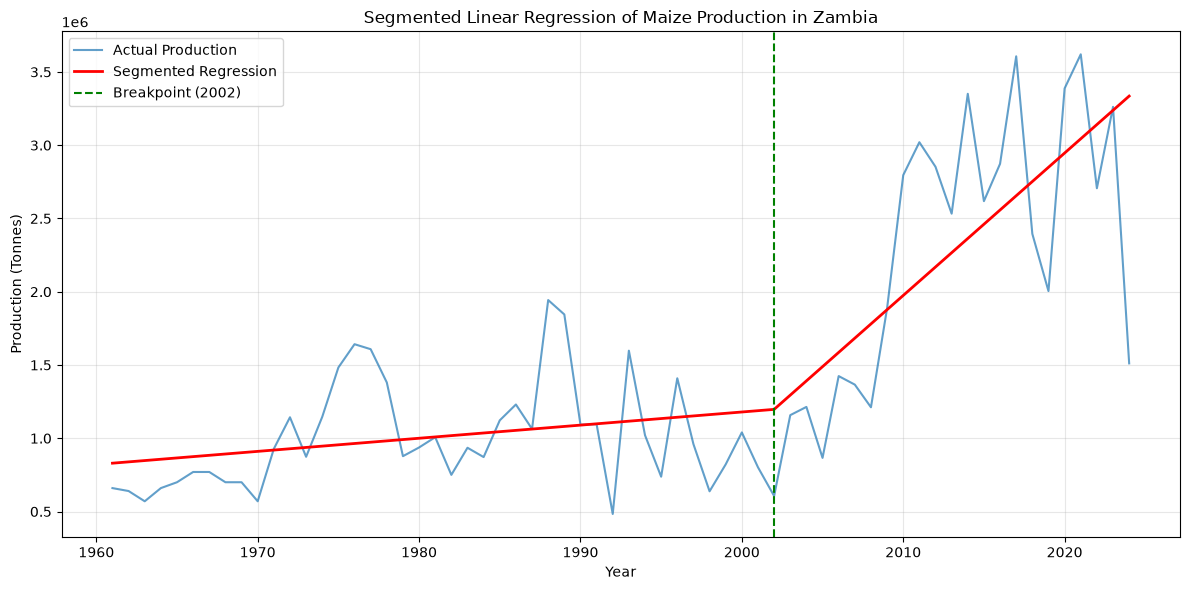

In [39]:
# Generate predictions from the segmented model
df["Segmented_Prediction"] = segmented_model.predict(
    sm.add_constant(
        pd.DataFrame({
            "Year": df["Year"] - df["Year"].min(),
            "Post_Breakpoint": np.maximum(
                0, df["Year"] - best_result["Breakpoint"]
            )
        })
    )
)

# Plot actual production and segmented regression
plt.figure(figsize=(12, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    label="Actual Production",
    alpha=0.7
)

plt.plot(
    df["Year"],
    df["Segmented_Prediction"],
    color="red",
    linewidth=2,
    label="Segmented Regression"
)

plt.axvline(
    best_result["Breakpoint"],
    color="green",
    linestyle="--",
    label=f"Breakpoint ({best_result['Breakpoint']})"
)

plt.title("Segmented Linear Regression of Maize Production in Zambia")
plt.xlabel("Year")
plt.ylabel("Production (Tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Segmented Linear Regression of Maize Production in Zambia (1961–2024)

The graph shows actual annual maize production together with a continuous two-segment linear regression, with the estimated breakpoint at **2002**. Before 2002 the fitted line rises gently, at an average of **8,956.95 tonnes per year**. After 2002 it rises much more steeply, at an average of **97,182.14 tonnes per year**, an increase in the annual trend of 88,225.19 tonnes. These are average rates of change within each segment and do not mean that production rose by these amounts in every year.

The segmented model describes the data better than the original linear model. The original model forced one slope onto two very different phases, whereas the segmented model separates a long period of modest growth from a later period of much faster growth. This is reflected in the increase in R-squared from **0.5223 to 0.6891**. However, the segmented model has more parameters and a breakpoint chosen from the data, so this improvement should be treated as descriptive. Adjusted R-squared or information criteria (AIC/BIC) would give a fairer comparison.

The fit is still imperfect. Actual production lies well above the fitted line in the mid-1970s, around 1988–1989 and in much of the 2010s, and below it in the early 1990s and around 2019. Production is also below the fitted line for much of 2003–2008, because the actual rise occurs more abruptly around 2009–2010 than the linear segment suggests. In 2024, actual production falls far below the fitted value. After about 2010, production fluctuates at a high level without an obvious continued steep rise.

The 2002 breakpoint indicates where a two-line model fits best, so the data are consistent with a change in the long-term trend around that time. The breakpoint was selected by minimising the residual sum of squares, which is exploratory and does not by itself establish a statistically significant structural break. It also does not identify a cause or event. The estimated date is uncertain, since actual production in 2002 is itself a low point and the largest increase occurs later.

**Limitations.** The model assumes a single break and two linear segments, and its standard errors and p-values are not valid when the breakpoint is estimated from the data. Autocorrelation and heteroscedasticity, identified in the simple model, may persist and should be checked in the segmented residuals. The model should not be used to forecast production without validation. The results describe association over time and not causation.

**Conclusion.** The segmented regression suggests that the long-term trend in maize production changed from slow to rapid growth around 2002 and captures the pattern better than a single straight line. Formal structural break tests (such as a supremum-F or Bai–Perron test), a breakpoint confidence interval and diagnostics on the segmented residuals are recommended before the break is treated as established.

In [41]:
# Original linear regression using statsmodels

X_linear = sm.add_constant(df["Year"] - df["Year"].min())

y = df["Production_tonnes"]

ols_model = sm.OLS(y, X_linear).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Production_tonnes   R-squared:                       0.522
Model:                            OLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     67.79
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.56e-11
Time:                        08:07:56   Log-Likelihood:                -942.37
No. Observations:                  64   AIC:                             1889.
Df Residuals:                      62   BIC:                             1893.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         3.9e+05   1.51e+05      2.587      0.0

In [43]:
comparison_models = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Segmented Regression"
    ],
    "R-squared": [
        ols_model.rsquared,
        segmented_model.rsquared
    ],
    "Adjusted R-squared": [
        ols_model.rsquared_adj,
        segmented_model.rsquared_adj
    ],
    "AIC": [
        ols_model.aic,
        segmented_model.aic
    ],
    "BIC": [
        ols_model.bic,
        segmented_model.bic
    ]
})

comparison_models.round(4)

,Model,R-squared,Adjusted R-squared,AIC,BIC
0,Simple Linear Regression,0.5223,0.5146,1888.7474,1893.0651
1,Segmented Regression,0.6891,0.6789,1863.2561,1869.7328


### Interpretation: Comparison of Regression Models

The comparison shows that the segmented regression performs better than the simple linear regression across all four evaluation measures.

The R-squared increased from 0.5223 to 0.6891, indicating that the segmented model explains a larger proportion of the variation in maize production. Similarly, adjusted R-squared increased from 0.5146 to 0.6789, suggesting that the improvement remains after accounting for the additional model parameter.

The segmented model also recorded lower AIC (1863.2561) and BIC (1869.7328) values compared with the simple linear model. Lower values indicate a preferable balance between model fit and complexity.

**Conclusion:** The segmented regression provides a better descriptive representation of historical maize production trends than a single linear regression. However, this comparison does not independently establish that 2002 is a statistically significant structural breakpoint, since the breakpoint was selected using the same dataset.

In [44]:
# Calculate residuals from the segmented regression

df["Segmented_Residuals"] = (
    df["Production_tonnes"] - df["Segmented_Prediction"]
)

print("Segmented Regression Residuals")
print("--------------------------------")

print(df[[
    "Year",
    "Production_tonnes",
    "Segmented_Prediction",
    "Segmented_Residuals"
]].head(10))

Segmented Regression Residuals
--------------------------------
   Year  Production_tonnes  Segmented_Prediction  Segmented_Residuals
0  1961           660000.0         830012.053772       -170012.053772
1  1962           640000.0         838969.008014       -198969.008014
2  1963           570000.0         847925.962257       -277925.962257
3  1964           660000.0         856882.916499       -196882.916499
4  1965           700000.0         865839.870741       -165839.870741
5  1966           770000.0         874796.824984       -104796.824984
6  1967           770000.0         883753.779226       -113753.779226
7  1968           700000.0         892710.733469       -192710.733469
8  1969           700000.0         901667.687711       -201667.687711
9  1970           570000.0         910624.641953       -340624.641953


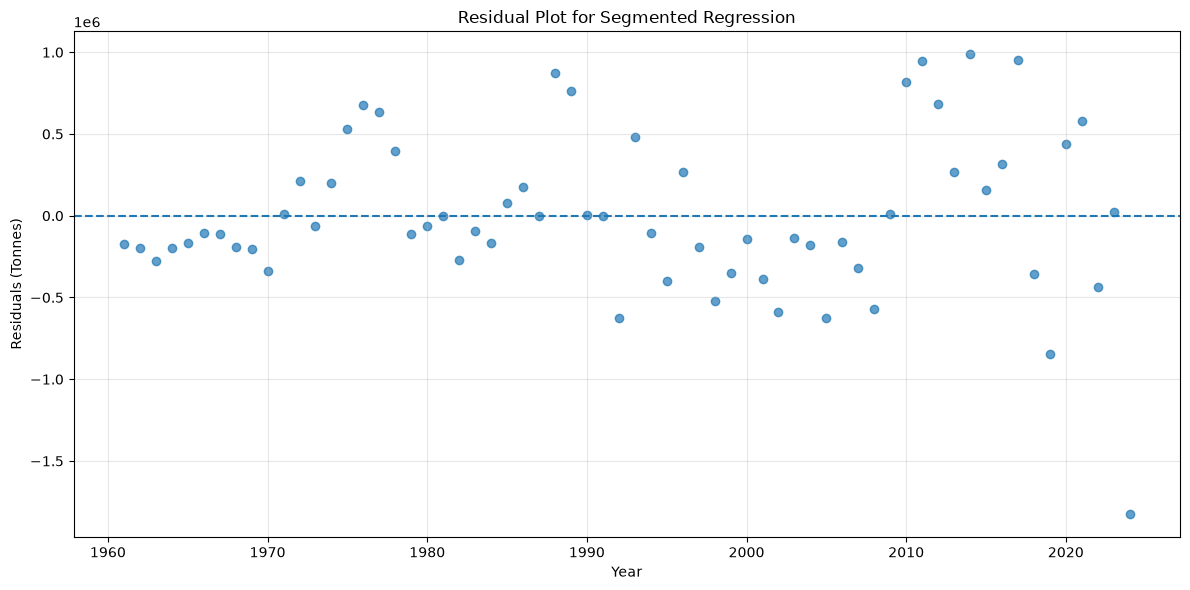

In [45]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df["Year"],
    df["Segmented_Residuals"],
    alpha=0.7
)

plt.axhline(0, linestyle="--")

plt.title("Residual Plot for Segmented Regression")
plt.xlabel("Year")
plt.ylabel("Residuals (Tonnes)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Residual Plot for Segmented Regression

The residual plot shows the difference between actual and predicted maize production (Residual = Actual − Predicted) for the segmented regression with a breakpoint at 2002. The residuals are not randomly scattered around zero. They occur in **long runs of the same sign**: mostly negative from about 1961 to 1970, positive from about 1975 to 1978 and around 1988–1989, **negative from about 1997 to 2008**, and **mostly positive from about 2010 to 2017**. This wave-like pattern suggests that systematic structure remains in the data.

The spread of the residuals also appears to **increase over time**. Residuals are tightly grouped in the 1960s and widest from about 2010 onwards. The most extreme residual occurs in **2024**, where actual production is far below the fitted value because the fitted post-2002 segment continues to rise. Other large departures occur in 2019 (negative) and around 1988–1989, 2011, 2014 and 2017 (positive). The model therefore performs least well in the recent, highly volatile period.

Compared with the simple linear regression, the residual behaviour has **improved but not been resolved**. Most residuals now lie within a narrower range, the long negative run between about 1990 and 2008 is smaller in magnitude, and the adjusted R-squared (0.6789) is well above the R-squared of the simple model (0.5146). However, long same-sign runs persist, which suggests that two straight segments do not fully capture the pattern, for example a more abrupt change around 2009–2010 or a plateau afterwards.

These are visual observations. The runs suggest possible **autocorrelation** and the widening spread suggests possible **heteroscedasticity**, but neither is confirmed by inspection alone. The Durbin–Watson and Breusch–Pagan tests should therefore be repeated on the segmented residuals, together with a residual ACF plot, normality checks and influence diagnostics for 2024.

**Conclusion.** The segmented model fits the data better than a single straight line, but its residuals still show systematic runs, a widening spread and a very large error in 2024. It is a better descriptive summary than the simple model but not an adequate one. Formal diagnostic tests, robust (Newey–West) standard errors, alternative break structures (such as multiple breaks or a level shift) and additional explanatory variables such as harvested area and yield are recommended before the model is relied on for inference.

In [46]:
from statsmodels.stats.stattools import durbin_watson

# Test for autocorrelation in segmented regression residuals
segmented_dw = durbin_watson(df["Segmented_Residuals"])

print("SEGMENTED REGRESSION: DURBINWATSON TEST - maize_analysis.ipynb:6")
print("")
print("DurbinWatson statistic: - maize_analysis.ipynb:8", round(segmented_dw, 4))

SEGMENTED REGRESSION: DURBINWATSON TEST - maize_analysis.ipynb:6

DurbinWatson statistic: - maize_analysis.ipynb:8 1.1453


### Interpretation: Durbin-Watson Test for Segmented Regression

The Durbin-Watson test produced a statistic of **1.1453**. Since this value is below 2, it suggests the presence of positive autocorrelation in the segmented regression residuals.

Compared with the simple linear regression, whose Durbin-Watson statistic was 0.7444, the segmented model shows an improvement because its statistic is closer to 2.

However, the result suggests that consecutive residuals may still be related. Therefore, the independence assumption may remain violated.

**Conclusion:** Although segmented regression improved the residual behaviour, positive autocorrelation remains a concern. Further diagnostic testing is necessary before drawing conclusions about the model's statistical reliability.

In [47]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Construct the segmented regression design matrix
X_segmented = sm.add_constant(pd.DataFrame({
    "Year": df["Year"] - df["Year"].min(),
    "Post_Breakpoint": np.maximum(
        0, df["Year"] - best_result["Breakpoint"]
    )
}))

# Perform Breusch-Pagan test
bp_segmented = het_breuschpagan(
    df["Segmented_Residuals"],
    X_segmented
)

print("SEGMENTED REGRESSION: BREUSCH-PAGAN TEST")
print("----------------------------------------")
print("LM Statistic:", round(bp_segmented[0], 4))
print("LM p-value:", round(bp_segmented[1], 6))
print("F Statistic:", round(bp_segmented[2], 4))
print("F p-value:", round(bp_segmented[3], 6))

SEGMENTED REGRESSION: BREUSCH-PAGAN TEST
----------------------------------------
LM Statistic: 13.9933
LM p-value: 0.000915
F Statistic: 8.5348
F p-value: 0.000539


### Interpretation: Breusch-Pagan Test for Segmented Regression

The Breusch-Pagan test was conducted to determine whether the segmented regression residuals have constant variance.

The test produced an LM statistic of **13.9933** with a p-value of **0.000915**. The F-statistic was **8.5348**, with a p-value of **0.000539**.

Since both p-values are below the 0.05 significance level, the null hypothesis of constant variance is rejected. This provides statistically significant evidence of heteroscedasticity in the segmented regression residuals.

Compared with the simple linear regression, the segmented model produced higher Breusch-Pagan p-values. However, the results remain statistically significant, indicating that non-constant residual variance is still a concern.

**Conclusion:** Although segmented regression improves the model fit and some residual diagnostics, heteroscedasticity remains present. Therefore, robust standard errors and further investigation of the model structure are necessary before relying on conventional statistical inference.

In [48]:
# Calculate Cook's distance for the segmented regression

influence = segmented_model.get_influence()
cooks_distance = influence.cooks_distance[0]

# Add Cook's distance to the dataset
df["Cooks_Distance"] = cooks_distance

# Identify the observation with the highest influence
most_influential = df.loc[df["Cooks_Distance"].idxmax()]

# Common reference threshold
threshold = 4 / len(df)

print("COOK'S DISTANCE: SEGMENTED REGRESSION")
print("------------------------------------")
print("Reference threshold:", round(threshold, 4))
print("Most influential year:", int(most_influential["Year"]))
print("Highest Cook's distance:", round(most_influential["Cooks_Distance"], 4))

print("\nObservations exceeding the reference threshold:")
print(
    df.loc[
        df["Cooks_Distance"] > threshold,
        ["Year", "Cooks_Distance"]
    ]
)

COOK'S DISTANCE: SEGMENTED REGRESSION
------------------------------------
Reference threshold: 0.0625
Most influential year: 2024
Highest Cook's distance: 0.8617

Observations exceeding the reference threshold:
    Year  Cooks_Distance
56  2017        0.082107
58  2019        0.087684
63  2024        0.861653


### Interpretation: Cook's Distance for Segmented Regression

Cook's distance was used to identify observations that have a substantial influence on the fitted segmented regression model.

The reference threshold was calculated as 4/n, giving **0.0625** for the 64 observations.

Three years exceeded this threshold:

- 2017: 0.0821
- 2019: 0.0877
- 2024: 0.8617

The year **2024 was the most influential observation**, with a Cook's distance of 0.8617. This value is considerably higher than the reference threshold, suggesting that the observation has a substantial influence on the fitted regression model.

This finding is consistent with the unusually large negative residual observed in 2024. The sharp decline in actual maize production during that year differs considerably from the upward trend predicted by the segmented model.

However, an influential observation is not necessarily an error or an invalid data point. Therefore, the 2024 observation should not automatically be removed from the analysis.

**Conclusion:** Cook's distance identifies 2024 as a highly influential observation, while 2017 and 2019 also exceed the reference threshold. These findings highlight the sensitivity of the segmented regression model to certain observations, particularly the most recent production decline.

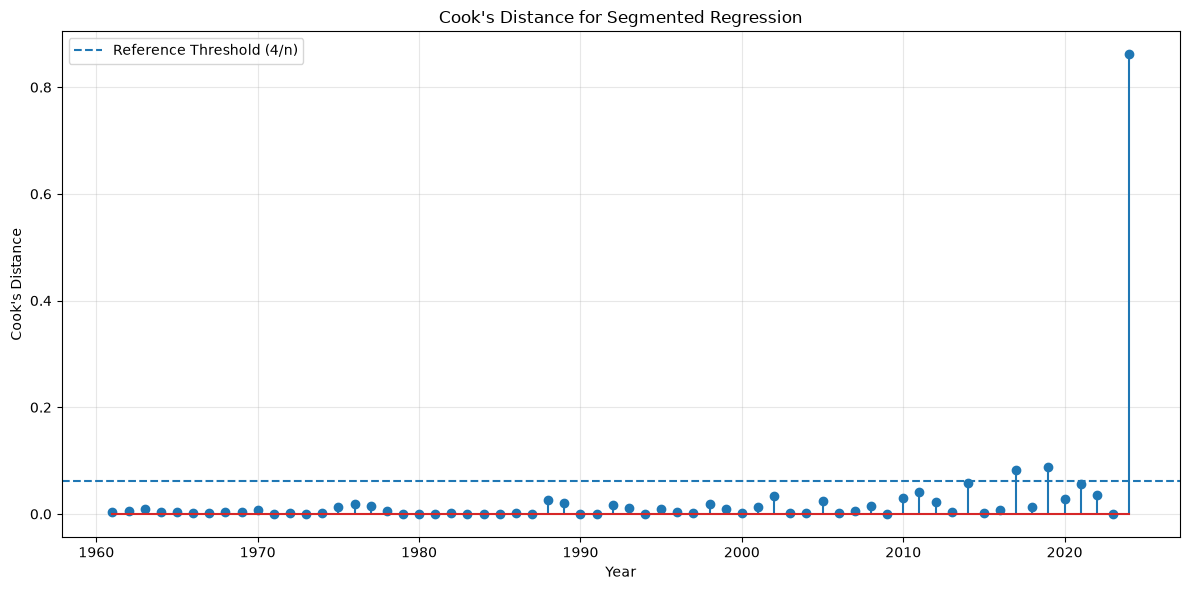

In [49]:
plt.figure(figsize=(12, 6))

plt.stem(
    df["Year"],
    df["Cooks_Distance"]
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Reference Threshold (4/n)"
)

plt.title("Cook's Distance for Segmented Regression")
plt.xlabel("Year")
plt.ylabel("Cook's Distance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Cook's Distance for Segmented Regression

Cook's distance measures how much the fitted regression would change if a single observation were removed, combining the size of the observation's residual with its leverage. Most observations in the plot have very small values, well below the 4/n reference threshold (0.0625), and observations before about 2010 are especially close to zero. This suggests that the fitted model, in particular the pre-2002 segment, does not depend on any single early year.

Three observations exceed the threshold: **2024 (0.8617)**, **2019 (0.0877)** and **2017 (0.0821)**. The year 2024 is far more influential than any other, at roughly 14 times the threshold and about ten times the next-largest value. This is consistent with the residual plot, where 2024 had the largest residual, and it is probably reinforced by its position as the final observation, which gives it high leverage; leverage values should be calculated to confirm this. The values for 2017 and 2019 are only modestly above the threshold and an order of magnitude smaller, so they merit attention but do not indicate instability on their own. Several other points in the 2010s lie just below the threshold.

These results suggest that the **post-2002 slope and the fitted values near the end of the series are sensitive to the 2024 observation**. The size and direction of this effect cannot be read from the graph. Although 2024 greatly exceeds 4/n, its Cook's distance is below 1, so it is best described as markedly more influential than the rest of the data, not as an automatic reason for removal.

Influential observations should **not be removed automatically**. An influential point is not necessarily an error, and removing it without a defensible reason would bias the analysis. The 2024 value should first be checked against the original FAOSTAT source for recording errors or provisional status. The model should then be refitted with and without 2024 (and 2017 and 2019), comparing the slopes, change in slope and R-squared, and re-running the breakpoint search. DFBETAS, leverage and studentized residuals, and robust regression would provide further evidence.

**Limitations.** The 4/n threshold is a rule of thumb that depends on sample size, does not separate leverage from residual size, and may be affected by masking. The analysis also assumes a fixed breakpoint and independent observations. The graph does not explain why production changed in any year.

**Conclusion.** Cook's distance identifies 2024 as a single observation with a strong influence on the segmented regression, with 2017 and 2019 having a smaller influence. The model's early segment appears stable, but its post-2002 trend and recent fitted values should be interpreted with caution until sensitivity analyses with and without 2024 have been completed.

In [50]:
from statsmodels.stats.outliers_influence import OLSInfluence

# Calculate influence diagnostics
segmented_influence = OLSInfluence(segmented_model)

df["Leverage"] = segmented_influence.hat_matrix_diag
df["Studentized_Residuals"] = (
    segmented_influence.resid_studentized_external
)

# Display the most influential observations
df.nlargest(
    5, "Cooks_Distance"
)[[
    "Year",
    "Segmented_Residuals",
    "Leverage",
    "Studentized_Residuals",
    "Cooks_Distance"
]]

,Year,Segmented_Residuals,Leverage,Studentized_Residuals,Cooks_Distance
63,2024,-1.824111e+06,0.141136,-4.566058,0.861653
58,2019,-8.449542e+05,0.077263,-1.804956,0.087684
56,2017,9.515697e+05,0.059289,2.026663,0.082107
53,2014,9.872381e+05,0.040443,2.085827,0.057940
60,2021,5.765360e+05,0.099566,1.229401,0.055246


### Interpretation: Leverage and Studentized Residuals

Additional influence diagnostics were conducted to investigate why 2024 had the highest Cook's distance.

The results showed that 2024 had a leverage value of **0.1411**, the highest among the observations examined. This indicates that its position in the predictor space gives it considerable potential to influence the fitted regression model.

Its externally studentized residual was **-4.5661**, indicating an unusually large negative prediction error. Actual maize production in 2024 was substantially lower than the value predicted by the segmented regression.

These two characteristics help explain its Cook's distance of **0.8617**. The combination of relatively high leverage and an unusually large residual makes 2024 considerably more influential than the other observations.

The years 2017 and 2019 also exceeded the Cook's distance reference threshold, but their influence was much smaller.

**Conclusion:** The influence diagnostics indicate that 2024 is a particularly influential observation because of its large prediction error and relatively high leverage. This finding highlights the importance of conducting sensitivity analysis before drawing conclusions about the post-2002 production trend.

In [51]:
# Create a temporary dataset excluding 2024
df_sensitivity = df[df["Year"] != 2024].copy()

print("Original observations:", len(df))
print("Observations after excluding 2024:", len(df_sensitivity))
print("Year range:", df_sensitivity["Year"].min(), "-", df_sensitivity["Year"].max())

Original observations: 64
Observations after excluding 2024: 63
Year range: 1961 - 2023


In [52]:
# Prepare variables for sensitivity analysis

years_sensitivity = df_sensitivity["Year"].values
production_sensitivity = df_sensitivity["Production_tonnes"].values

year_centered_sensitivity = (
    years_sensitivity - years_sensitivity.min()
)

post_breakpoint_sensitivity = np.maximum(
    0,
    years_sensitivity - 2002
)

# Construct the regression design matrix
X_sensitivity = pd.DataFrame({
    "Year": year_centered_sensitivity,
    "Post_Breakpoint": post_breakpoint_sensitivity
})

X_sensitivity = sm.add_constant(X_sensitivity)

# Fit segmented regression without 2024
segmented_model_no2024 = sm.OLS(
    production_sensitivity,
    X_sensitivity
).fit()

print("SEGMENTED REGRESSION WITHOUT 2024 - maize_analysis.ipynb:29")
print("")
print(segmented_model_no2024.summary())

SEGMENTED REGRESSION WITHOUT 2024 - maize_analysis.ipynb:29

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.769
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     100.0
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           7.81e-20
Time:                        08:28:07   Log-Likelihood:                -905.22
No. Observations:                  63   AIC:                             1816.
Df Residuals:                      60   BIC:                             1823.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [53]:
# Extract slopes from the original model
original_pre_slope = segmented_model.params["Year"]

original_slope_change = (
    segmented_model.params["Post_Breakpoint"]
)

original_post_slope = (
    original_pre_slope + original_slope_change
)

# Extract slopes from the model without 2024
adjusted_pre_slope = segmented_model_no2024.params["Year"]

adjusted_slope_change = (
    segmented_model_no2024.params["Post_Breakpoint"]
)

adjusted_post_slope = (
    adjusted_pre_slope + adjusted_slope_change
)

# Create comparison table
sensitivity_comparison = pd.DataFrame({
    "Measure": [
        "Pre-breakpoint slope",
        "Post-breakpoint slope",
        "Change in slope",
        "R-squared",
        "Adjusted R-squared",
        "AIC",
        "BIC"
    ],
    "Original Model": [
        original_pre_slope,
        original_post_slope,
        original_slope_change,
        segmented_model.rsquared,
        segmented_model.rsquared_adj,
        segmented_model.aic,
        segmented_model.bic
    ],
    "Without 2024": [
        adjusted_pre_slope,
        adjusted_post_slope,
        adjusted_slope_change,
        segmented_model_no2024.rsquared,
        segmented_model_no2024.rsquared_adj,
        segmented_model_no2024.aic,
        segmented_model_no2024.bic
    ]
})

sensitivity_comparison.round(4)

,Measure,Original Model,Without 2024
0,Pre-breakpoint slope,8956.9542,6719.7362
1,Post-breakpoint slope,97182.1407,113620.8296
2,Change in slope,88225.1865,106901.0934
3,R-squared,0.6891,0.7693
4,Adjusted R-squared,0.6789,0.7616
5,AIC,1863.2561,1816.4397
6,BIC,1869.7328,1822.8691


### Interpretation: Sensitivity Analysis Excluding 2024

A sensitivity analysis was conducted to investigate the influence of the 2024 observation on the segmented regression model. A temporary dataset containing 63 observations (1961–2023) was created, and the segmented regression was refitted using the original breakpoint of 2002.

The results showed considerable changes in the estimated regression coefficients.

The pre-breakpoint slope decreased from 8,956.95 to 6,719.74 tonnes per year, while the post-breakpoint slope increased from 97,182.14 to 113,620.83 tonnes per year. The estimated change in slope also increased from 88,225.19 to 106,901.09 tonnes per year.

The model's R-squared increased from 0.6891 to 0.7693, while adjusted R-squared increased from 0.6789 to 0.7616. This indicates that excluding 2024 produces a substantially better fit to the remaining observations.

However, the pre-breakpoint slope in the model without 2024 was not statistically significant at the 5% level (p = 0.168).

These findings demonstrate that the 2024 observation has a substantial influence on the estimated segmented regression coefficients and overall model fit.

**Conclusion:** The sensitivity analysis confirms that the segmented regression results are sensitive to the 2024 observation. Although the observation has a considerable influence, it should not automatically be removed from the original dataset. The original model remains important because it represents the complete historical record.

In [54]:
# Search for the optimal breakpoint without 2024

results_sensitivity = []

for breakpoint in years_sensitivity[9:-9]:

    post_breakpoint = np.maximum(
        0, years_sensitivity - breakpoint
    )

    X_segmented_sensitivity = pd.DataFrame({
        "Year": year_centered_sensitivity,
        "Post_Breakpoint": post_breakpoint
    })

    X_segmented_sensitivity = sm.add_constant(
        X_segmented_sensitivity
    )

    model = sm.OLS(
        production_sensitivity,
        X_segmented_sensitivity
    ).fit()

    results_sensitivity.append({
        "Breakpoint": breakpoint,
        "RSS": np.sum(model.resid ** 2),
        "Model": model
    })

# Select the breakpoint with the smallest RSS
best_result_sensitivity = min(
    results_sensitivity,
    key=lambda x: x["RSS"]
)

print("BREAKPOINT SEARCH WITHOUT 2024")
print("--------------------------------")
print("Original breakpoint:", best_result["Breakpoint"])
print("New optimal breakpoint:", best_result_sensitivity["Breakpoint"])
print("Residual Sum of Squares:",
      round(best_result_sensitivity["RSS"], 2))

BREAKPOINT SEARCH WITHOUT 2024
--------------------------------
Original breakpoint: 2002
New optimal breakpoint: 2002
Residual Sum of Squares: 11149278183972.86


### Interpretation: Breakpoint Stability Analysis

The breakpoint search was repeated after excluding the 2024 observation to determine whether this influential observation affected the estimated structural change.

The original dataset identified 2002 as the optimal breakpoint. After removing 2024, the breakpoint search again identified 2002.

This indicates that the estimated breakpoint is stable under the exclusion of the 2024 observation.

Although the regression coefficients and goodness-of-fit statistics changed during the sensitivity analysis, the selected breakpoint remained unchanged.

**Conclusion:** The sensitivity analysis suggests that the identification of 2002 as the potential breakpoint is not solely driven by the 2024 observation. However, this does not establish that a statistically significant structural break occurred in 2002. Further formal testing would be required to confirm this.

In [55]:
segmented_model_reselected = best_result_sensitivity["Model"]

pre_slope_reselected = segmented_model_reselected.params["Year"]

slope_change_reselected = (
    segmented_model_reselected.params["Post_Breakpoint"]
)

post_slope_reselected = (
    pre_slope_reselected + slope_change_reselected
)

print("BREAKPOINT MODEL WITHOUT 2024")
print("--------------------------------")
print("Breakpoint:", best_result_sensitivity["Breakpoint"])
print("Pre-breakpoint slope:", round(pre_slope_reselected, 2))
print("Post-breakpoint slope:", round(post_slope_reselected, 2))
print("R-squared:", round(segmented_model_reselected.rsquared, 4))
print("Adjusted R-squared:", round(segmented_model_reselected.rsquared_adj, 4))

BREAKPOINT MODEL WITHOUT 2024
--------------------------------
Breakpoint: 2002
Pre-breakpoint slope: 6719.74
Post-breakpoint slope: 113620.83
R-squared: 0.7693
Adjusted R-squared: 0.7616


### Interpretation: Refitted Segmented Regression Model

After repeating the breakpoint search without the 2024 observation, the optimal breakpoint remained 2002.

The refitted model estimated an average annual production trend of 6,719.74 tonnes before the breakpoint and 113,620.83 tonnes after the breakpoint.

The model achieved an R-squared of 0.7693 and an adjusted R-squared of 0.7616, indicating that it explains approximately 76.93% of the variation in maize production over the 1961–2023 period.

The pre-breakpoint slope was not statistically significant at the 5% level (p = 0.168), so there is insufficient evidence that production followed a significant linear upward trend during that period.

**Conclusion:** The breakpoint remained stable after excluding 2024, although the estimated regression slopes changed. This reinforces the importance of examining influential observations when interpreting statistical models.

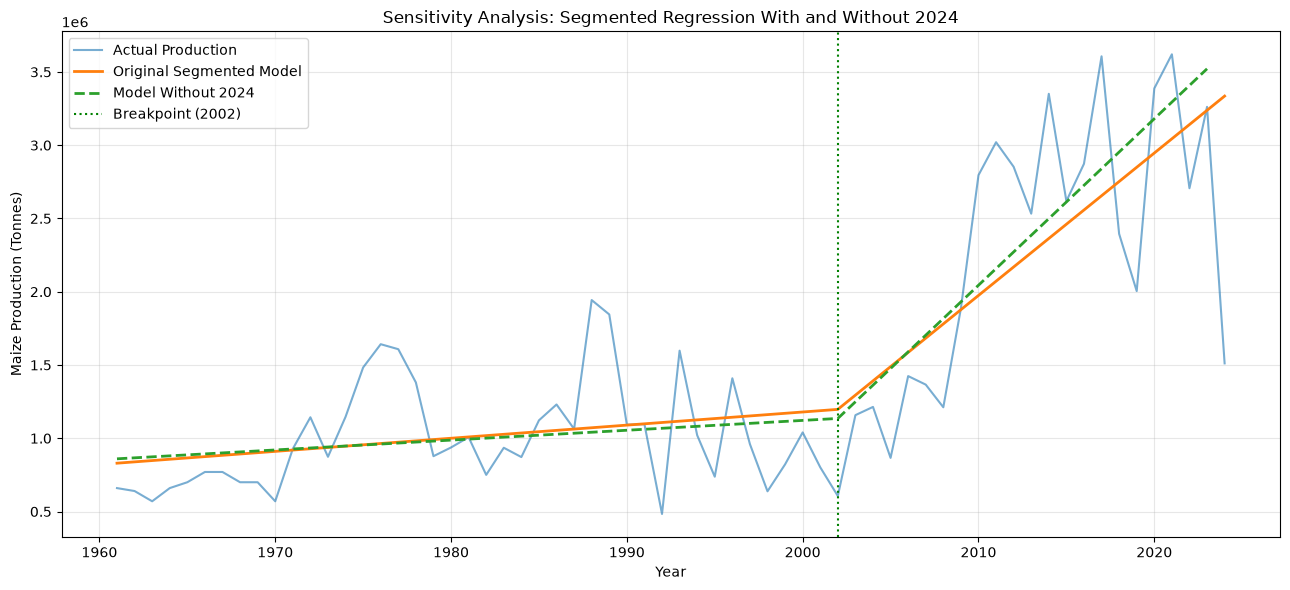

In [56]:
plt.figure(figsize=(13, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    label="Actual Production",
    alpha=0.6
)

plt.plot(
    df["Year"],
    segmented_model.predict(
        sm.add_constant(
            pd.DataFrame({
                "Year": df["Year"] - df["Year"].min(),
                "Post_Breakpoint": np.maximum(
                    0, df["Year"] - 2002
                )
            })
        )
    ),
    label="Original Segmented Model",
    linewidth=2
)

plt.plot(
    df_sensitivity["Year"],
    segmented_model_reselected.predict(X_sensitivity),
    label="Model Without 2024",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    2002,
    color="green",
    linestyle=":",
    label="Breakpoint (2002)"
)

plt.title("Sensitivity Analysis: Segmented Regression With and Without 2024")
plt.xlabel("Year")
plt.ylabel("Maize Production (Tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Sensitivity Analysis of Segmented Regression With and Without 2024

The graph compares **observed production** (blue line) with two **fitted** segmented regressions: the original model using all 64 observations (orange) and a refitted model excluding 2024 (green dashed). Both capture the same broad pattern: a long, gentle rise before 2002 and a much steeper rise afterwards. Neither reproduces the year-to-year volatility, particularly after about 2010, when observed production oscillates widely around both lines, and both lie above actual production for much of 2003–2008.

Excluding 2024 changes the fitted line. The pre-2002 slope falls from 8,956.95 to 6,719.74 tonnes per year, while the post-2002 slope rises from 97,182.14 to 113,620.83 tonnes per year (about 17%). Because the model is continuous at the breakpoint, a change in the later segment also shifts the earlier one. The R-squared rises from 0.6891 to 0.7693 and the adjusted R-squared from 0.6789 to 0.7616. This improvement is expected after removing the observation with the largest residual and does not mean the refitted model is universally superior, since it is estimated on 63 observations and the two models are not compared on identical data. A fairer comparison would evaluate both models on the same 63 years.

The grid search selects **2002 in both models**, so the breakpoint is stable to the removal of 2024. This does not confirm 2002 as a statistically established structural break. It was chosen by minimising the residual sum of squares, and neighbouring years or other perturbations were not tested.

The qualitative conclusion is unchanged: production trends upward slowly before 2002 and much more steeply afterwards. The quantitative slope estimates, however, depend noticeably on a single observation. This is consistent with the Cook's distance results and with the large negative residual for 2024, which pulls the post-2002 segment downward when included.

**Limitations.** Only one observation was removed; 2017, 2019 and other years were not examined, and autocorrelation and heteroscedasticity have not yet been tested on the segmented residuals. The breakpoint is estimated rather than formally tested, and two linear segments may not describe the plateau-like behaviour after about 2010. The analysis describes association over time and cannot explain why production changed. The 2024 observation should be verified against the original source before any decision to exclude it.

**Conclusion.** The sensitivity analysis shows that the shape of the trend, a slow rise followed by a steep one, is robust to excluding 2024, but the estimated slopes and fit statistics are sensitive to it. The 2024 observation should therefore be reported as influential, not deleted automatically, and both models should be presented. Further work should include leave-one-out analysis, an RSS profile across candidate breakpoints, a structural break test, and residual diagnostics.

In [57]:
# Actual production for the common period: 1961–2023
actual = production_sensitivity

# Predictions from the original model (trained with 2024)
original_predictions = segmented_model.predict(X_sensitivity)

# Predictions from the refitted model (without 2024)
adjusted_predictions = segmented_model_reselected.predict(
    X_sensitivity
)

# Calculate evaluation metrics
def evaluate_model(actual, predicted):
    residuals = actual - predicted

    return {
        "R-squared": 1 - (
            np.sum(residuals ** 2) /
            np.sum((actual - np.mean(actual)) ** 2)
        ),
        "RMSE": np.sqrt(np.mean(residuals ** 2)),
        "MAE": np.mean(np.abs(residuals))
    }

# Compare both models on identical observations
fair_comparison = pd.DataFrame({
    "Original Model": evaluate_model(
        actual, original_predictions
    ),
    "Model Without 2024": evaluate_model(
        actual, adjusted_predictions
    )
})

fair_comparison.round(4)

,Original Model,Model Without 2024
R-squared,0.7580,0.7693
RMSE,430873.3130,420681.1971
MAE,335601.2833,326007.1676


### Interpretation: Fair Model Comparison Using Identical Observations

To ensure a fair comparison, both segmented regression models were evaluated using the same 63 observations covering 1961–2023.

The original model, which was estimated using all 64 observations, achieved an R-squared of 0.7580, RMSE of 430,873.31 tonnes and MAE of 335,601.28 tonnes when evaluated on the common period.

The model fitted without 2024 achieved an R-squared of 0.7693, RMSE of 420,681.20 tonnes and MAE of 326,007.17 tonnes.

The model without 2024 performed slightly better across all three evaluation metrics. Its RMSE decreased by approximately 10,192 tonnes, while its MAE decreased by approximately 9,594 tonnes.

These results suggest that excluding the influential 2024 observation improves the model's representation of the historical observations from 1961 to 2023.

However, the improvement is relatively modest, and the 2024 observation should not automatically be considered erroneous or removed from the original dataset.

**Conclusion:** The fair comparison confirms that the estimated segmented regression is sensitive to the inclusion of 2024. Nevertheless, the original model remains important because it incorporates the complete historical dataset.

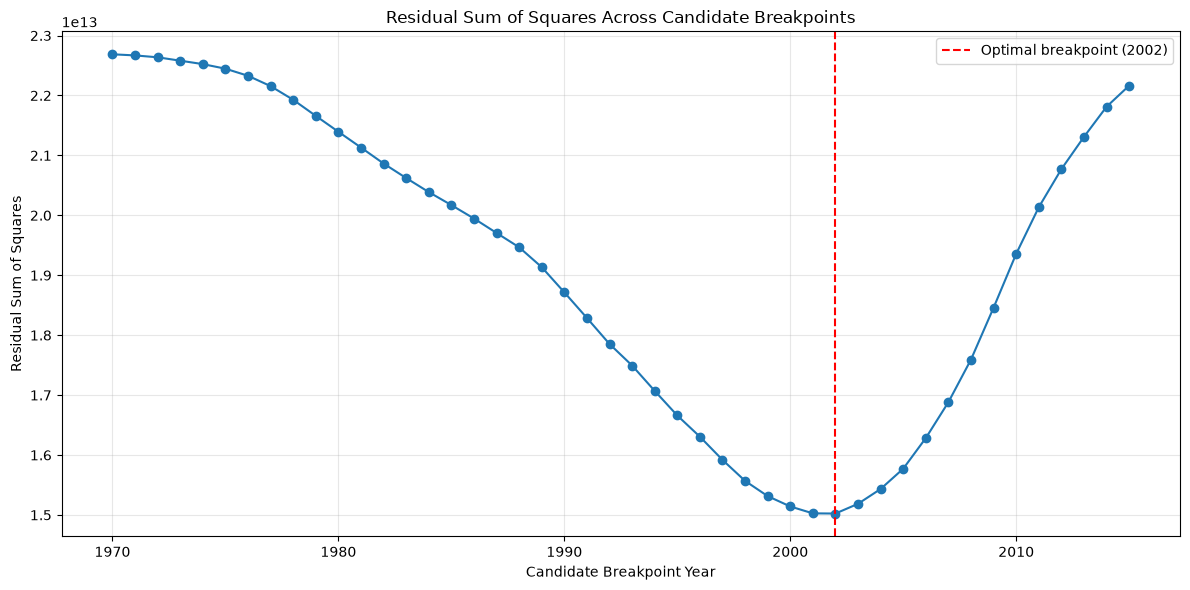

In [58]:
# Extract breakpoint years and their RSS values
breakpoint_years = [
    result["Breakpoint"] for result in results
]

rss_values = [
    result["RSS"] for result in results
]

plt.figure(figsize=(12, 6))

plt.plot(
    breakpoint_years,
    rss_values,
    marker="o",
    linewidth=1.5
)

plt.axvline(
    best_result["Breakpoint"],
    color="red",
    linestyle="--",
    label=f"Optimal breakpoint ({best_result['Breakpoint']})"
)

plt.title("Residual Sum of Squares Across Candidate Breakpoints")
plt.xlabel("Candidate Breakpoint Year")
plt.ylabel("Residual Sum of Squares")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Residual Sum of Squares Across Candidate Breakpoints

The plot shows the residual sum of squares (RSS) of the continuous two-segment regression for each candidate breakpoint year, with at least 10 observations required in each segment. RSS measures the variation in production that remains unexplained after fitting the model, so lower values indicate a closer fit. The profile has a single, smooth, U-shaped minimum at **2002** (RSS = 15,023,444,519,595.26), with higher values for candidates earlier than about the 1990s and later than about 2008.

The minimum is **not sharp**. The RSS curve flattens near the bottom of the valley, and neighbouring years, especially 2001, have very similar values to 2002. The profile therefore supports the early 2000s as the region of best fit, but 2002 should be treated as a **point estimate with uncertainty** (a plausible range of roughly 2000–2004 is suggested informally by the plot, not by a confidence interval). The breakpoint remained 2002 when 2024 was excluded, which suggests some stability, although only one observation was tested. The RSS values of the two analyses are not directly comparable, since they use different numbers of observations.

Selecting a breakpoint by minimising RSS has important limitations. A minimum always exists, even if there is no true break. The breakpoint is selected using the same data on which the model is evaluated, so the improvement in fit (R² of 0.6891 against 0.5223 for the single line) is optimistic. The standard F-test and p-values are not valid when the breakpoint is estimated from the data, and the profile assumes independent, constant-variance errors, which earlier diagnostics suggested may not hold. The model also assumes a single break and linear segments, and it cannot show whether the rise after 2002 is gradual or abrupt. **The optimal breakpoint is therefore not a formally confirmed structural break**, and it provides no information about causes.

**Conclusion.** The RSS profile indicates that a two-segment model with a join in the early 2000s fits the data better than other breakpoint locations, with 2002 as the best estimate but with a broad, flat minimum and clear uncertainty about the exact year. Before a structural change is claimed, the following are recommended: (1) a structural break test that allows for an unknown breakpoint (sup-F, Bai–Perron, or a bootstrap null distribution); (2) a confidence interval for the breakpoint; (3) comparison with models without a break and with alternative structures (a level shift, multiple breaks) using AIC/BIC; (4) out-of-sample validation such as rolling-origin evaluation; (5) overlaying the RSS profile with and without 2024; and (6) residual diagnostics for autocorrelation and heteroscedasticity.

In [59]:
# Examine candidate breakpoints within five years of 2002

rss_neighbourhood = pd.DataFrame(results)

rss_neighbourhood = rss_neighbourhood[
    (rss_neighbourhood["Breakpoint"] >= 1997) &
    (rss_neighbourhood["Breakpoint"] <= 2007)
].copy()

# Calculate the difference from the minimum RSS
minimum_rss = best_result["RSS"]

rss_neighbourhood["RSS_Difference"] = (
    rss_neighbourhood["RSS"] - minimum_rss
)

rss_neighbourhood["Percentage_Increase"] = (
    rss_neighbourhood["RSS_Difference"] / minimum_rss
) * 100

rss_neighbourhood[
    ["Breakpoint", "RSS", "RSS_Difference", "Percentage_Increase"]
].round(4)

,Breakpoint,RSS,RSS_Difference,Percentage_Increase
27,1997,1.591895e+13,8.955015e+11,5.9607
28,1998,1.556834e+13,5.448954e+11,3.6270
29,1999,1.531421e+13,2.907648e+11,1.9354
30,2000,1.514135e+13,1.179105e+11,0.7848
31,2001,1.502633e+13,2.887377e+09,0.0192
32,2002,1.502344e+13,0.000000e+00,0.0000
33,2003,1.518588e+13,1.624322e+11,1.0812
34,2004,1.543328e+13,4.098363e+11,2.7280
35,2005,1.577140e+13,7.479522e+11,4.9786
36,2006,1.628347e+13,1.260022e+12,8.3870


### Interpretation: RSS Around the Optimal Breakpoint

The RSS neighbourhood analysis provides further insight into the breakpoint selection.

The minimum RSS occurs at **2002**, confirming it as the optimal breakpoint among the candidate years examined.

However, nearby years also produce relatively similar RSS values. For example, the RSS at 2001 is only 0.0192% higher than the minimum RSS at 2002. The values for 2000 and 2003 are also relatively close.

This suggests that the RSS profile has a relatively flat region around the early 2000s. Therefore, although 2002 is the best-fitting breakpoint, the exact year is not strongly distinguished from some neighbouring years.

**Conclusion:** The analysis supports an approximate change in the maize production trend around the early 2000s. However, the breakpoint search is exploratory and does not constitute a formal statistical test of a structural break. Further testing would be necessary before claiming that a statistically significant structural change occurred in 2002.

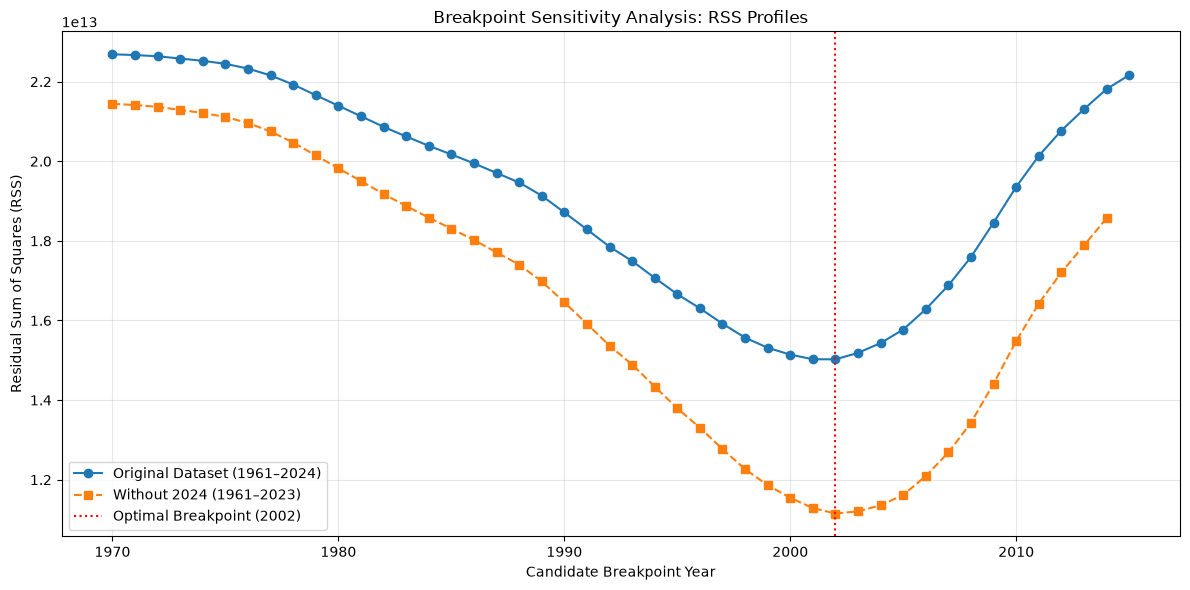

In [60]:
# Compare RSS profiles with and without the 2024 observation

original_rss = pd.DataFrame(results)
sensitivity_rss = pd.DataFrame(results_sensitivity)

plt.figure(figsize=(12, 6))

plt.plot(
    original_rss["Breakpoint"],
    original_rss["RSS"],
    marker="o",
    label="Original Dataset (1961–2024)"
)

plt.plot(
    sensitivity_rss["Breakpoint"],
    sensitivity_rss["RSS"],
    marker="s",
    linestyle="--",
    label="Without 2024 (1961–2023)"
)

plt.axvline(
    2002,
    color="red",
    linestyle=":",
    label="Optimal Breakpoint (2002)"
)

plt.title("Breakpoint Sensitivity Analysis: RSS Profiles")
plt.xlabel("Candidate Breakpoint Year")
plt.ylabel("Residual Sum of Squares (RSS)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Breakpoint Sensitivity Analysis (RSS Profiles)

The plot compares the residual sum of squares (RSS) of the continuous two-segment regression across candidate breakpoint years for the **original dataset (1961–2024)** and the **dataset excluding 2024 (1961–2023)**. Both profiles share the same shape: a smooth, asymmetric U with a single minimum and no competing local minima. RSS declines gradually through the 1970s and more steeply through the 1980s and 1990s, reaches its lowest value in the early 2000s, and then rises. The profile excluding 2024 lies below the original profile at every candidate year, and its valley appears somewhat deeper.

**The minimum RSS occurs at 2002 in both datasets** (original: 15,023,444,519,595.26; without 2024: 11,149,278,183,972.86). Removing 2024 therefore lowers the profile but does not change the estimated breakpoint. This shows that 2024 affects the *level* of the fit (RSS, R² and the slope estimates) more than the *timing* of the best-fitting breakpoint, consistent with its high Cook's distance (0.8617) and its position at the end of the series. It is, however, evidence from the removal of a single observation, and the grid search uses one-year steps.

Both minima are **rounded rather than sharp**. Neighbouring years, particularly 2001 and 2003, have RSS values close to that of 2002, so the location of the breakpoint should be treated as a point estimate with uncertainty of a few years, not as a precisely identified date. This informal range is not a confidence interval.

The two RSS magnitudes **should not be compared directly** as evidence that one dataset gives a better model. RSS is a sum over observations, the sensitivity dataset has one fewer observation, and the removed observation has the largest residual, so a lower RSS is expected by construction. The R² values are likewise based on different data. Fair comparisons require the same observations, scale-free measures such as normalised RSS profiles, or out-of-sample prediction error.

**Limitations.** Selecting a breakpoint by minimising RSS always returns a minimum, even if no break exists. The breakpoint is chosen using the same data used to assess the fit, so the results are in-sample and optimistic. Standard F-tests and p-values are not valid when the breakpoint is estimated, and the model assumes a single break, linear segments and independent, constant-variance errors, which earlier diagnostics suggested may not hold.

**Conclusion.** Within a continuous two-segment linear model, the best-fitting breakpoint is 2002 in both datasets, and this location is not driven by the 2024 observation. However, the broad valley indicates uncertainty about the exact year, and the breakpoint is an **exploratory estimate, not a formally established structural break**. Further analysis should include a structural break test that allows for an unknown breakpoint (such as sup-F, Bai–Perron or a bootstrap null distribution), a confidence interval for the breakpoint, a leave-one-out analysis across all years, comparison with no-break and alternative models using AIC/BIC, and out-of-sample validation.

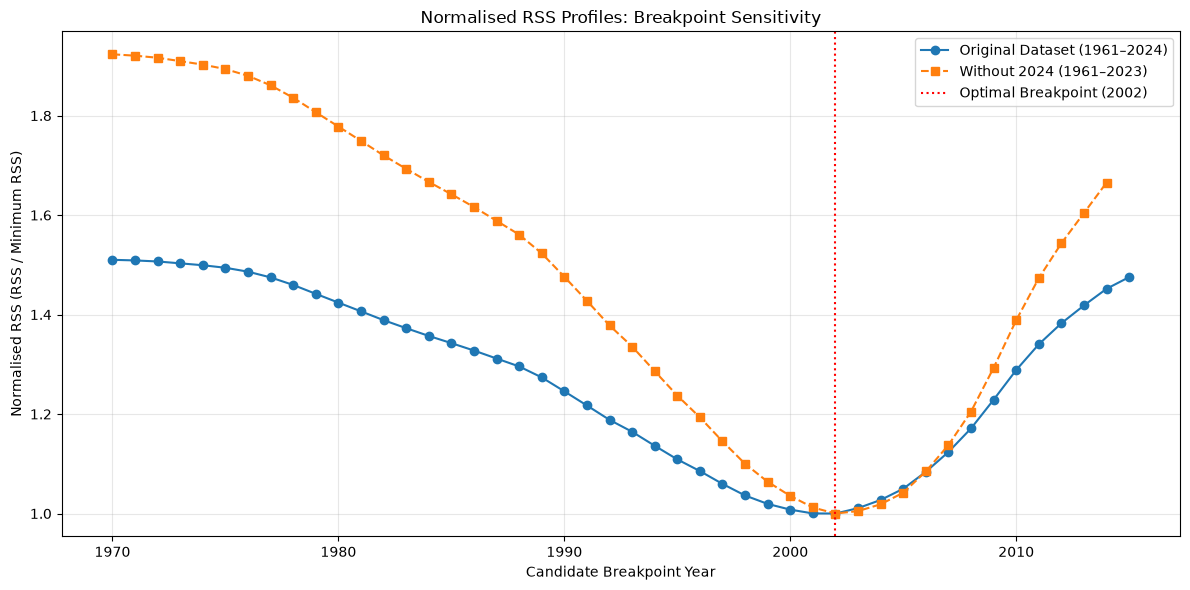

In [61]:
# Normalise both RSS profiles using their respective minimum RSS values

original_rss = pd.DataFrame(results)
sensitivity_rss = pd.DataFrame(results_sensitivity)

original_min_rss = original_rss["RSS"].min()
sensitivity_min_rss = sensitivity_rss["RSS"].min()

original_rss["Normalised_RSS"] = (
    original_rss["RSS"] / original_min_rss
)

sensitivity_rss["Normalised_RSS"] = (
    sensitivity_rss["RSS"] / sensitivity_min_rss
)

# Compare the normalised profiles over their common breakpoint range
plt.figure(figsize=(12, 6))

plt.plot(
    original_rss["Breakpoint"],
    original_rss["Normalised_RSS"],
    marker="o",
    label="Original Dataset (1961–2024)"
)

plt.plot(
    sensitivity_rss["Breakpoint"],
    sensitivity_rss["Normalised_RSS"],
    marker="s",
    linestyle="--",
    label="Without 2024 (1961–2023)"
)

plt.axvline(
    2002,
    color="red",
    linestyle=":",
    label="Optimal Breakpoint (2002)"
)

plt.title("Normalised RSS Profiles: Breakpoint Sensitivity")
plt.xlabel("Candidate Breakpoint Year")
plt.ylabel("Normalised RSS (RSS / Minimum RSS)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Normalised RSS Profiles (Breakpoint Sensitivity)

For each dataset, the residual sum of squares (RSS) was divided by that dataset's own minimum RSS (Normalised RSS = RSS / Minimum RSS). This removes the absolute scale of the RSS, which depends on the number of observations and on whether the large residual for 2024 is included, so that the **shapes** of the two profiles can be compared directly. A normalised value of 1.0 marks the best candidate within each dataset's search and does not indicate a perfect model. Normalisation also does not fully remove the effects of different sample sizes, candidate ranges (to 2015 for the original dataset and 2014 without 2024) or residual variance, and the two datasets share 63 of their observations.

Both profiles are smooth, single-valley curves with their **minimum at 2002**, so excluding 2024 does not change the estimated breakpoint. The profile without 2024 lies above the original profile on the left limb (before about 2000) and the far right limb (after about 2008) and has a **more sharply defined minimum**. The original profile has a broader, flatter bottom. Between about 2003 and 2006 the two profiles nearly coincide. In both cases 2001 and 2003 remain close to 2002, so the valley is rounded and the exact year is uncertain by a few years.

This suggests that 2024 mainly affects the **relative shape of the RSS profile**, rather than the location of the best-fitting breakpoint. Its large residual and high Cook's distance indicate substantial influence on the segmented regression. Removing it changes the relative differences between candidate breakpoint fits, making the early-2000s region appear more clearly separated from alternative years. However, because each candidate breakpoint involves a separately fitted model, the precise contribution of 2024 to RSS may vary across the candidate years. Therefore, the normalised profiles demonstrate a change in relative fit but do not independently establish the mechanism behind that change.

**Limitations.** A normalised RSS profile is a descriptive ratio. It has no sampling distribution, cannot establish statistical significance, and cannot provide a formal confidence interval; counting the years within a few percent of the minimum is an informal heuristic. The profile depends on the minimum RSS used as the denominator, on a one-year grid with a trimming rule, and on the assumptions of a single break, linear segments, independent errors and constant variance, which earlier diagnostics suggested may not hold. The comparison involves overlapping data and in-sample fit.

**Conclusion.** In both datasets the best-fitting breakpoint is 2002, and its location is not driven by the 2024 observation, although that observation weakens the contrast between candidate breakpoints. The profiles indicate uncertainty of a few years about the exact breakpoint. The breakpoint remains an **exploratory estimate, not a formally established structural break**. Further analysis should include a structural break test that allows for an unknown breakpoint (such as sup-F, Bai–Perron or a bootstrap), a confidence interval for the breakpoint, a leave-one-out analysis across all years, comparison with no-break and alternative models using AIC/BIC, and residual diagnostics.

In [62]:
# Leave-One-Out Breakpoint Sensitivity Analysis

loo_results = []

years = df["Year"].values
production = df["Production_tonnes"].values

# Remove each observation individually
for omitted_year in years:

    # Create dataset excluding the selected year
    mask = years != omitted_year

    years_loo = years[mask]
    production_loo = production[mask]

    # Centre the year variable
    year_centered_loo = years_loo - years_loo.min()

    candidate_results = []

    # Test possible breakpoints
    for breakpoint in years_loo[9:-9]:

        post_breakpoint = np.maximum(
            0, years_loo - breakpoint
        )

        X_loo = pd.DataFrame({
            "Year": year_centered_loo,
            "Post_Breakpoint": post_breakpoint
        })

        X_loo = sm.add_constant(X_loo)

        model = sm.OLS(production_loo, X_loo).fit()

        rss = np.sum(model.resid ** 2)

        candidate_results.append({
            "Breakpoint": breakpoint,
            "RSS": rss
        })

    # Select the breakpoint with minimum RSS
    best_loo = min(
        candidate_results,
        key=lambda x: x["RSS"]
    )

    loo_results.append({
        "Omitted_Year": omitted_year,
        "Optimal_Breakpoint": best_loo["Breakpoint"],
        "RSS": best_loo["RSS"]
    })

# Convert results into a DataFrame
loo_df = pd.DataFrame(loo_results)

print("LeaveOneOut Analysis Completed - maize_analysis.ipynb:60")
print("Observations tested: - maize_analysis.ipynb:61", len(loo_df))
print("\nFirst 10 results: - maize_analysis.ipynb:62")

loo_df.head(10)

LeaveOneOut Analysis Completed - maize_analysis.ipynb:60
Observations tested: - maize_analysis.ipynb:61 64

First 10 results: - maize_analysis.ipynb:62


,Omitted_Year,Optimal_Breakpoint,RSS
0,1961,2001,1.498886e+13
1,1962,2001,1.497705e+13
2,1963,2001,1.493496e+13
3,1964,2001,1.497959e+13
4,1965,2001,1.499308e+13
5,1966,2002,1.501176e+13
6,1967,2002,1.500974e+13
7,1968,2001,1.498424e+13
8,1969,2002,1.498072e+13
9,1970,2001,1.490147e+13


In [63]:
# Count how frequently each breakpoint was selected

breakpoint_frequency = (
    loo_df["Optimal_Breakpoint"]
    .value_counts()
    .sort_index()
)

print("BREAKPOINT FREQUENCY - maize_analysis.ipynb:9")
print("")
print(breakpoint_frequency)

print("\nPercentage of times each breakpoint was selected: - maize_analysis.ipynb:13")
print(
    (breakpoint_frequency / len(loo_df) * 100).round(2)
)

print("\nBreakpoint range: - maize_analysis.ipynb:18")
print(
    loo_df["Optimal_Breakpoint"].min(),
    "to",
    loo_df["Optimal_Breakpoint"].max()
)

print("\nNumber of times 2002 was selected: - maize_analysis.ipynb:25")
print(
    (loo_df["Optimal_Breakpoint"] == 2002).sum()
)

BREAKPOINT FREQUENCY - maize_analysis.ipynb:9

Optimal_Breakpoint
2001    24
2002    40
Name: count, dtype: int64

Percentage of times each breakpoint was selected: - maize_analysis.ipynb:13
Optimal_Breakpoint
2001    37.5
2002    62.5
Name: count, dtype: float64

Breakpoint range: - maize_analysis.ipynb:18
2001 to 2002

Number of times 2002 was selected: - maize_analysis.ipynb:25
40


### Interpretation: Leave-One-Out Breakpoint Sensitivity Analysis

A leave-one-out sensitivity analysis was conducted by removing each observation individually and repeating the breakpoint search. This produced 64 separate segmented regression analyses.

The results showed that:

- The breakpoint was estimated at **2002 in 40 analyses (62.5%)**.
- The breakpoint was estimated at **2001 in 24 analyses (37.5%)**.
- The overall estimated breakpoint range was **2001–2002**.

These findings indicate that the estimated breakpoint is relatively stable when individual observations are removed. Although the optimal year occasionally shifts from 2002 to 2001, it never moves outside this two-year range.

**Conclusion:** The leave-one-out analysis provides evidence that the estimated breakpoint around 2002 is not driven by a single observation. However, this is a sensitivity assessment rather than a formal statistical test. The percentages represent the frequency of selected breakpoints across the leave-one-out analyses, not probabilities that a structural break occurred in a particular year.

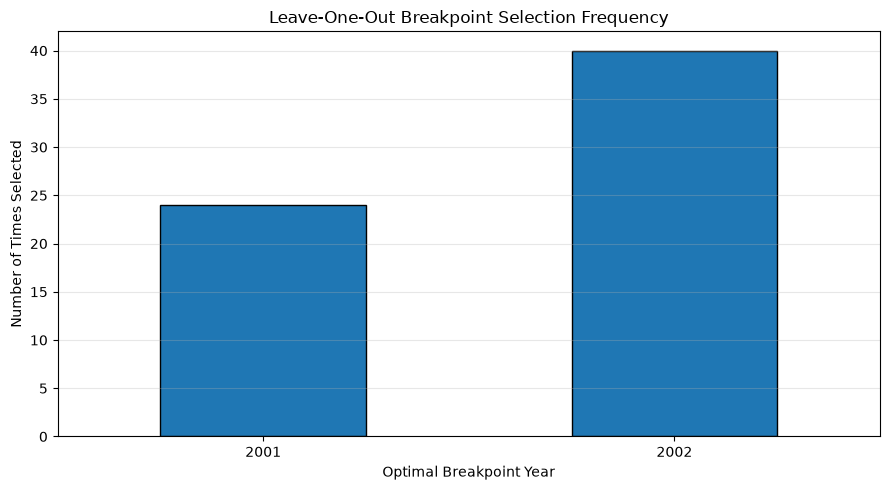

In [64]:
plt.figure(figsize=(9, 5))

breakpoint_frequency.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Leave-One-Out Breakpoint Selection Frequency")
plt.xlabel("Optimal Breakpoint Year")
plt.ylabel("Number of Times Selected")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation: Leave-One-Out Breakpoint Selection Frequency

The bar chart summarises a leave-one-out sensitivity analysis. Each of the 64 annual observations was removed in turn, the continuous two-segment breakpoint search was repeated on the remaining 63 observations, and the optimal breakpoint was recorded. Each bar shows how many of the 64 refits selected a given year. Only two years were ever selected: **2002 in 40 refits (62.5%)** and **2001 in 24 refits (37.5%)**. The full-dataset optimum (2002) is therefore also the most frequently selected breakpoint, and no single deletion moved the estimate outside a one-year band.

This indicates that the **location** of the best-fitting breakpoint is **stable to the removal of any individual observation**, including 2017, 2019 and 2024 (Cook's distance 0.8617). The split between 2001 and 2002 is consistent with the earlier RSS and normalised RSS profiles, which showed a broad, flat minimum in which 2001 and 2002 have nearly identical RSS values, so that removing one observation can tip the minimum between adjacent years. Stability of the breakpoint does not imply stability of the slope estimates and fit statistics, which the earlier analysis showed can change noticeably when 2024 is removed.

The results should be interpreted cautiously. The leave-one-out datasets overlap with the original in 63 of 64 observations, so the refits are not independent and the narrow 2001–2002 range probes only local sensitivity; it should not be read as a confidence interval or as evidence that the breakpoint is known to within a year. Jackknife-type spreads can also be unreliable for a non-smooth estimator such as a grid-search minimiser. Single deletions cannot detect the joint influence of groups of observations or respect the time-series structure of the data, and the chart does not show the RSS margins by which each year was selected.

The percentages are **not probabilities**. The 62.5% for 2002 is the proportion of refits that returned 2002. It does not mean there is a 62.5% chance that a structural break occurred in 2002, because the search always returns a breakpoint whether or not one exists. Stability of the estimate is also distinct from statistical significance.

**Conclusion.** The leave-one-out analysis shows that the estimated breakpoint of 2002 (or, in some refits, 2001) is robust to the removal of any single observation, which strengthens the case for reporting the early 2000s as the best-fitting location of a change in trend. It does not establish a statistically significant structural break, provide a confidence interval, or support any causal explanation. Further work should include a formal structural break test that allows for an unknown breakpoint (such as sup-F, Bai–Perron or a bootstrap), a block-bootstrap distribution of the breakpoint, a record of which omitted years produced 2001 and by what RSS margin, comparison with no-break and alternative models using AIC/BIC, and residual diagnostics.

In [65]:
# Identify observations whose removal resulted in a 2001 breakpoint

years_selecting_2001 = loo_df[
    loo_df["Optimal_Breakpoint"] == 2001
][["Omitted_Year", "Optimal_Breakpoint", "RSS"]]

print("YEARS WHOSE REMOVAL SELECTED 2001")
print("--------------------------------")
display(years_selecting_2001)

print("\nTotal:", len(years_selecting_2001))

YEARS WHOSE REMOVAL SELECTED 2001
--------------------------------


,Omitted_Year,Optimal_Breakpoint,RSS
0,1961,2001,1.498886e+13
1,1962,2001,1.497705e+13
2,1963,2001,1.493496e+13
3,1964,2001,1.497959e+13
4,1965,2001,1.499308e+13
7,1968,2001,1.498424e+13
9,1970,2001,1.490147e+13
15,1976,2001,1.455072e+13
16,1977,2001,1.460830e+13
17,1978,2001,1.485968e+13



Total: 24


In [66]:
# Compare RSS for 2001 and 2002 across leave-one-out analyses

rss_comparison = []

for omitted_year in years:

    mask = years != omitted_year

    years_loo = years[mask]
    production_loo = production[mask]

    year_centered_loo = years_loo - years_loo.min()

    candidate_rss = {}

    for breakpoint in [2001, 2002]:

        # Skip a breakpoint if its year was omitted
        if breakpoint not in years_loo:
            continue

        post_breakpoint = np.maximum(
            0, years_loo - breakpoint
        )

        X_loo = pd.DataFrame({
            "Year": year_centered_loo,
            "Post_Breakpoint": post_breakpoint
        })

        X_loo = sm.add_constant(X_loo)

        model = sm.OLS(production_loo, X_loo).fit()

        candidate_rss[breakpoint] = np.sum(model.resid ** 2)

    if len(candidate_rss) == 2:

        rss_comparison.append({
            "Omitted_Year": omitted_year,
            "RSS_2001": candidate_rss[2001],
            "RSS_2002": candidate_rss[2002],
            "RSS_Difference": (
                candidate_rss[2001] - candidate_rss[2002]
            )
        })

rss_comparison_df = pd.DataFrame(rss_comparison)

rss_comparison_df["Preferred_Breakpoint"] = np.where(
    rss_comparison_df["RSS_Difference"] > 0,
    2002,
    2001
)

display(rss_comparison_df.round(2))

,Omitted_Year,RSS_2001,RSS_2002,RSS_Difference,Preferred_Breakpoint
0,1961,1.498886e+13,1.499185e+13,-2.995346e+09,2001
1,1962,1.497705e+13,1.498043e+13,-3.384875e+09,2001
2,1963,1.493496e+13,1.494000e+13,-5.041074e+09,2001
3,1964,1.497959e+13,1.498179e+13,-2.204295e+09,2001
4,1965,1.499308e+13,1.499404e+13,-9.584809e+08,2001
...,...,...,...,...,...
57,2020,1.480216e+13,1.481028e+13,-8.118790e+09,2001
58,2021,1.463835e+13,1.465430e+13,-1.594645e+10,2001
59,2022,1.483231e+13,1.481062e+13,2.169223e+10,2002
60,2023,1.502390e+13,1.502281e+13,1.096365e+09,2002


In [67]:
# Calculate percentage difference between candidate breakpoint RSS values

rss_comparison_df["Percentage_Difference"] = (
    rss_comparison_df["RSS_Difference"]
    / rss_comparison_df["RSS_2002"].abs()
) * 100

print("CLOSEST COMPETITION BETWEEN BREAKPOINTS - maize_analysis.ipynb:8")
print("")

display(
    rss_comparison_df.assign(
        Absolute_Percentage_Difference=
        rss_comparison_df["Percentage_Difference"].abs()
    )
    .nsmallest(10, "Absolute_Percentage_Difference")
    [[
        "Omitted_Year",
        "RSS_Difference",
        "Percentage_Difference",
        "Preferred_Breakpoint"
    ]]
    .round(4)
)

CLOSEST COMPETITION BETWEEN BREAKPOINTS - maize_analysis.ipynb:8



,Omitted_Year,RSS_Difference,Percentage_Difference,Preferred_Breakpoint
15,1976,-3.165665e+07,-0.0002,2001
7,1968,-3.530776e+07,-0.0002,2001
8,1969,3.461428e+08,0.0023,2002
9,1970,-5.445468e+08,-0.0037,2001
5,1966,7.132107e+08,0.0048,2002
17,1978,-7.116292e+08,-0.0048,2001
24,1985,7.740149e+08,0.0052,2002
6,1967,8.431543e+08,0.0056,2002
4,1965,-9.584809e+08,-0.0064,2001
60,2023,1.096365e+09,0.0073,2002


### Interpretation: RSS Differences Between Candidate Breakpoints

The RSS differences between the 2001 and 2002 breakpoint candidates were examined across the leave-one-out analyses. The difference was calculated as the RSS for 2001 minus the RSS for 2002. Negative values indicate that 2001 provides a better fit, while positive values favour 2002.

The ten closest comparisons showed extremely small percentage differences, ranging from approximately **0.0002% to 0.0073%**. For example, removing the 1976 observation resulted in a difference of approximately -0.0002%, while removing 2023 produced approximately +0.0073%.

These small differences indicate that the two candidate breakpoint years frequently provide almost equivalent fits. Consequently, removing an individual observation can change which year has the slightly lower RSS without producing a meaningful improvement in the overall model fit.

**Conclusion:** The leave-one-out results support the stability of the estimated breakpoint around 2001–2002. However, the frequent close competition between these adjacent years reinforces the uncertainty surrounding the exact breakpoint year. The evidence supports an early-2000s change in the fitted production trend rather than establishing 2002 as an exact or statistically confirmed structural break.

In [68]:
# Supremum F-test for an unknown structural breakpoint

# Restricted model: simple linear regression
rss_restricted = np.sum(ols_model.resid ** 2)

n = len(df)
k_unrestricted = 3  # Intercept, Year and Post_Breakpoint

sup_f_results = []

for result in results:

    rss_unrestricted = result["RSS"]

    # Calculate the F-statistic
    f_statistic = (
        (rss_restricted - rss_unrestricted)
        / (rss_unrestricted / (n - k_unrestricted))
    )

    sup_f_results.append({
        "Breakpoint": result["Breakpoint"],
        "F_Statistic": f_statistic
    })

sup_f_df = pd.DataFrame(sup_f_results)

# Identify the maximum F-statistic
sup_f_result = sup_f_df.loc[
    sup_f_df["F_Statistic"].idxmax()
]

print("SUPREMUM F-TEST")
print("----------------------------")
print("Optimal breakpoint:", int(sup_f_result["Breakpoint"]))
print("Sup-F statistic:", round(sup_f_result["F_Statistic"], 4))
print("Candidate breakpoints tested:", len(sup_f_df))

SUPREMUM F-TEST
----------------------------
Optimal breakpoint: 2002
Sup-F statistic: 32.7306
Candidate breakpoints tested: 46


### Interpretation: Supremum F-Test

A Supremum F-test (Sup-F) was conducted to investigate whether Zambia's maize production experienced a structural change in its linear trend.

The test compared a restricted model containing a single linear trend against segmented regression models containing a possible breakpoint. A total of 46 candidate breakpoint years were examined.

The results identified:

- **Optimal breakpoint:** 2002
- **Sup-F statistic:** 32.7306
- **Candidate breakpoints tested:** 46

The result indicates that the segmented regression model provides a substantially better in-sample fit than the single linear trend model at the selected breakpoint.

However, because the breakpoint was selected by searching across multiple candidate years, the ordinary F-distribution cannot be used directly to establish statistical significance. A bootstrap procedure is therefore required to obtain an appropriate reference distribution for the Sup-F statistic.

**Conclusion:** The Sup-F analysis independently identifies 2002 as the best-fitting breakpoint. However, further statistical testing is required before concluding that the apparent structural change is statistically significant.

In [70]:
# Dependent Wild Bootstrap Configuration

np.random.seed(42)

B = 1000
bandwidth = 4
significance_level = 0.05

# Number of observations
n = len(df)

# Bartlett covariance matrix for dependent bootstrap multipliers
indices = np.arange(n)

distance_matrix = np.abs(
    indices[:, None] - indices[None, :]
)

multiplier_covariance = np.maximum(
    1 - distance_matrix / (bandwidth + 1),
    0
)

# Cholesky decomposition
L = np.linalg.cholesky(
    multiplier_covariance + 1e-10 * np.eye(n)
)

print("BOOTSTRAP CONFIGURATION - maize_analysis.ipynb:29")
print("")
print("Bootstrap replications: - maize_analysis.ipynb:31", B)
print("Bandwidth: - maize_analysis.ipynb:32", bandwidth)
print("Significance level: - maize_analysis.ipynb:33", significance_level)
print("Observations: - maize_analysis.ipynb:34", n)
print("Covariance matrix shape: - maize_analysis.ipynb:35", multiplier_covariance.shape)
print("Cholesky decomposition successful. - maize_analysis.ipynb:36")

BOOTSTRAP CONFIGURATION - maize_analysis.ipynb:29

Bootstrap replications: - maize_analysis.ipynb:31 1000
Bandwidth: - maize_analysis.ipynb:32 4
Significance level: - maize_analysis.ipynb:33 0.05
Observations: - maize_analysis.ipynb:34 64
Covariance matrix shape: - maize_analysis.ipynb:35 (64, 64)
Cholesky decomposition successful. - maize_analysis.ipynb:36


In [71]:
# Dependent Wild Bootstrap: Sup-F Test

# Fit the restricted model under the null hypothesis
restricted_fitted = ols_model.fittedvalues
restricted_residuals = ols_model.resid

# Centre the residuals
restricted_residuals = (
    restricted_residuals - restricted_residuals.mean()
)

# Prepare candidate breakpoint design matrices
candidate_designs = []

for result in results:
    breakpoint = result["Breakpoint"]

    post_breakpoint = np.maximum(
        0, df["Year"].values - breakpoint
    )

    X_candidate = pd.DataFrame({
        "Year": df["Year"].values - df["Year"].min(),
        "Post_Breakpoint": post_breakpoint
    })

    X_candidate = sm.add_constant(X_candidate)

    candidate_designs.append(X_candidate)

# Store bootstrap Sup-F statistics
bootstrap_sup_f = []

for b in range(B):

    # Generate dependent random multipliers
    multipliers = L @ np.random.normal(size=n)

    # Generate bootstrap data under the no-break model
    y_boot = (
        restricted_fitted
        + restricted_residuals * multipliers
    )

    # Fit restricted model
    restricted_boot = sm.OLS(
        y_boot,
        X_linear
    ).fit()

    rss_restricted_boot = np.sum(
        restricted_boot.resid ** 2
    )

    # Search across all candidate breakpoints
    maximum_f = -np.inf

    for X_candidate in candidate_designs:

        unrestricted_boot = sm.OLS(
            y_boot,
            X_candidate
        ).fit()

        rss_unrestricted_boot = np.sum(
            unrestricted_boot.resid ** 2
        )

        f_stat = (
            (rss_restricted_boot - rss_unrestricted_boot)
            / (rss_unrestricted_boot / (n - k_unrestricted))
        )

        maximum_f = max(maximum_f, f_stat)

    bootstrap_sup_f.append(maximum_f)

print("Bootstrap simulations completed: - maize_analysis.ipynb:78", len(bootstrap_sup_f))
print("Observed SupF statistic: - maize_analysis.ipynb:79", round(sup_f_result["F_Statistic"], 4))
print("Mean bootstrap SupF: - maize_analysis.ipynb:80", round(np.mean(bootstrap_sup_f), 4))

Bootstrap simulations completed: - maize_analysis.ipynb:78 1000
Observed SupF statistic: - maize_analysis.ipynb:79 32.7306
Mean bootstrap SupF: - maize_analysis.ipynb:80 7.3361


In [72]:
# Bootstrap Sup-F Test: Statistical Decision

bootstrap_sup_f = np.array(bootstrap_sup_f)

bootstrap_critical_value = np.quantile(
    bootstrap_sup_f,
    1 - significance_level
)

bootstrap_pvalue = (
    1 + np.sum(
        bootstrap_sup_f >= sup_f_result["F_Statistic"]
    )
) / (B + 1)

print("BOOTSTRAP SUPF TEST RESULTS - maize_analysis.ipynb:16")
print("")
print("Observed SupF: - maize_analysis.ipynb:18", round(sup_f_result["F_Statistic"], 4))
print("Bootstrap mean: - maize_analysis.ipynb:19", round(np.mean(bootstrap_sup_f), 4))
print("95% Critical Value: - maize_analysis.ipynb:20", round(bootstrap_critical_value, 4))
print("Bootstrap pvalue: - maize_analysis.ipynb:21", round(bootstrap_pvalue, 6))

if bootstrap_pvalue < significance_level:
    print("\nDecision: Reject the null hypothesis. - maize_analysis.ipynb:24")
    print("There is evidence of a structural change in the production trend. - maize_analysis.ipynb:25")
else:
    print("\nDecision: Fail to reject the null hypothesis. - maize_analysis.ipynb:27")
    print("There is insufficient evidence of a structural change. - maize_analysis.ipynb:28")

BOOTSTRAP SUPF TEST RESULTS - maize_analysis.ipynb:16

Observed SupF: - maize_analysis.ipynb:18 32.7306
Bootstrap mean: - maize_analysis.ipynb:19 7.3361
95% Critical Value: - maize_analysis.ipynb:20 21.7809
Bootstrap pvalue: - maize_analysis.ipynb:21 0.010989

Decision: Reject the null hypothesis. - maize_analysis.ipynb:24
There is evidence of a structural change in the production trend. - maize_analysis.ipynb:25


### Interpretation: Dependent Wild Bootstrap Sup-F Test

A dependent wild bootstrap procedure was performed to evaluate whether the apparent structural change in Zambia's maize production trend was statistically significant.

A total of 1,000 bootstrap simulations were conducted under the null hypothesis of a single linear production trend. The procedure accounted approximately for dependence and changing variance in the residuals while repeating the breakpoint search in each simulation.

The results were:

- **Observed Sup-F statistic:** 32.7306
- **Mean bootstrap Sup-F statistic:** 7.3361
- **95% bootstrap critical value:** 21.7809
- **Bootstrap p-value:** 0.010989
- **Significance level:** 0.05

The observed Sup-F statistic exceeded the 95% bootstrap critical value. Furthermore, the bootstrap p-value was below 0.05.

Therefore, the null hypothesis of no structural change in the linear production trend was rejected.

These findings provide statistical evidence of a structural change in Zambia's maize production trend. The breakpoint search identified 2002 as the best-fitting candidate. However, previous sensitivity analyses showed that 2001 and 2002 produced very similar fits. Consequently, the precise timing of the change should be interpreted cautiously.

**Limitations:** The bootstrap results depend on the chosen multiplier covariance structure, bandwidth and bootstrap specification. Only 1,000 simulations were conducted, so the estimated p-value has some Monte Carlo uncertainty. A larger number of simulations could improve its numerical precision. The test also does not identify the underlying causes of the structural change.

**Conclusion:** The bootstrap analysis provides statistical evidence supporting a change in the historical maize production trend, strengthening the case for using segmented regression rather than relying exclusively on a single linear trend.

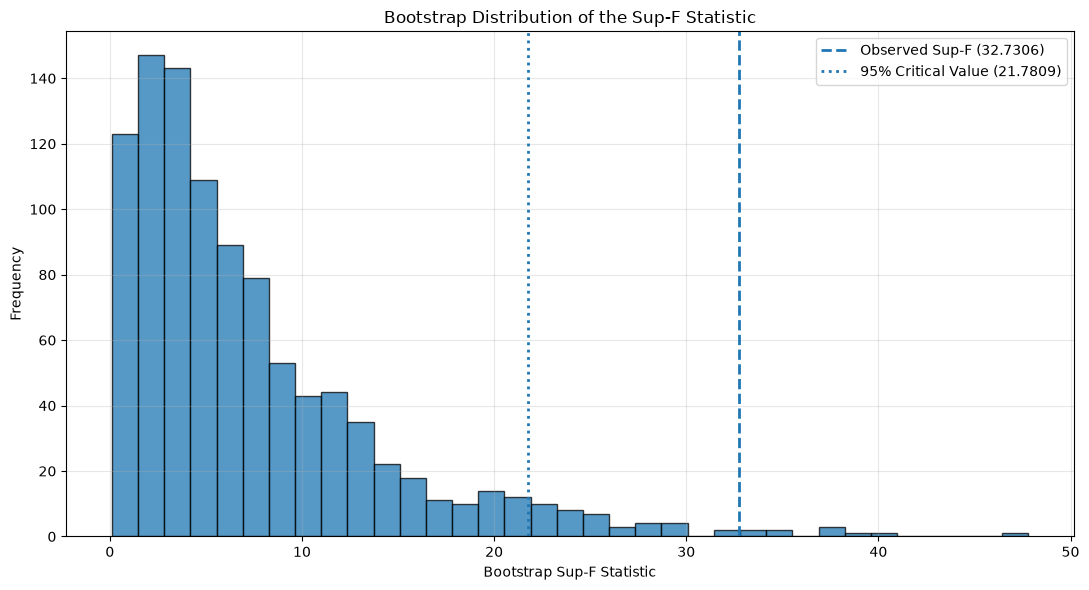

In [73]:
plt.figure(figsize=(11, 6))

plt.hist(
    bootstrap_sup_f,
    bins=35,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    sup_f_result["F_Statistic"],
    linestyle="--",
    linewidth=2,
    label="Observed Sup-F (32.7306)"
)

plt.axvline(
    bootstrap_critical_value,
    linestyle=":",
    linewidth=2,
    label="95% Critical Value (21.7809)"
)

plt.title("Bootstrap Distribution of the Sup-F Statistic")
plt.xlabel("Bootstrap Sup-F Statistic")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Bootstrap Distribution of the Sup-F Statistic

The histogram displays the Sup-F statistics obtained from **1,000 dependent wild bootstrap simulations under the null hypothesis of no structural break**. The Sup-F statistic represents the maximum F-statistic obtained when comparing the single linear trend model with segmented regression models across the candidate breakpoint years.

The bootstrap distribution is strongly right-skewed. Most simulated statistics are concentrated at relatively low values, while a smaller number extend into the upper tail. The mean bootstrap statistic is 7.3361.

The **95% bootstrap critical value is 21.7809**, while the observed Sup-F statistic is **32.7306**. The observed statistic therefore lies beyond the 95th percentile of the bootstrap null distribution.

The calculated bootstrap p-value is **0.010989**, which is below the significance level of 0.05. Therefore, the null hypothesis of no structural change is rejected.

This provides statistical evidence that a single linear trend does not adequately describe Zambia's maize production series from 1961 to 2024. The improvement in fit from segmented regression is greater than would typically be expected under the simulated no-break hypothesis, accounting for the search across candidate breakpoints.

The result is consistent with the earlier analyses:
- Segmented regression identified 2002 as the best-fitting breakpoint.
- The RSS profile showed that 2001 and 2002 produced very similar fits.
- The leave-one-out analysis selected either 2001 or 2002, demonstrating stability around the early 2000s.
- The sensitivity analysis showed that excluding the influential 2024 observation did not change the optimal breakpoint.

However, evidence of a structural change does not establish certainty about the exact breakpoint year.

**Limitations:** The analysis used 1,000 bootstrap simulations, so the estimated p-value has Monte Carlo uncertainty. Approximately 10 simulated statistics were at least as large as the observed statistic. More simulations could provide a more precise estimate.

The dependent wild bootstrap used a Bartlett covariance structure with a bandwidth of 4. Its validity depends on the suitability of the multiplier dependence structure and the assumptions underlying the null model. The test may also be sensitive to the candidate breakpoint range and the influential 2024 observation.

Furthermore, rejecting the no-break hypothesis does not prove that there was exactly one structural break in 2002. Other forms of non-linearity or multiple changes could also produce evidence against a single linear trend. The analysis does not establish the causes of changes in maize production.

**Conclusion:** The observed Sup-F statistic of 32.7306 exceeded the 95% bootstrap critical value of 21.7809, with a bootstrap p-value of 0.010989. These results provide statistically significant evidence of a departure from a single linear production trend at the 5% significance level. The early-2000s period, particularly 2001–2002, is supported as the location of the best-fitting change in trend, although the precise breakpoint year remains uncertain.

In [74]:
# Bootstrap Configuration Without 2024

np.random.seed(42)

B_sensitivity = 1000
bandwidth_sensitivity = 4
n_sensitivity = len(df_sensitivity)

indices_sensitivity = np.arange(n_sensitivity)

distance_matrix_sensitivity = np.abs(
    indices_sensitivity[:, None] -
    indices_sensitivity[None, :]
)

multiplier_covariance_sensitivity = np.maximum(
    1 - distance_matrix_sensitivity / (bandwidth_sensitivity + 1),
    0
)

L_sensitivity = np.linalg.cholesky(
    multiplier_covariance_sensitivity
    + 1e-10 * np.eye(n_sensitivity)
)

print("Bootstrap simulations:", B_sensitivity)
print("Observations:", n_sensitivity)
print("Bandwidth:", bandwidth_sensitivity)
print("Covariance matrix:", multiplier_covariance_sensitivity.shape)
print("Cholesky decomposition successful.")

Bootstrap simulations: 1000
Observations: 63
Bandwidth: 4
Covariance matrix: (63, 63)
Cholesky decomposition successful.


In [75]:
# Dependent Wild Bootstrap Sup-F Test Without 2024

# Restricted model under the no-break hypothesis
restricted_fitted_sensitivity = (
    segmented_model_reselected.model
)

# Refit the restricted linear model using the 63 observations
restricted_sensitivity = sm.OLS(
    production_sensitivity,
    X_sensitivity[["const", "Year"]]
).fit()

restricted_fitted_values = restricted_sensitivity.fittedvalues

restricted_residuals_sensitivity = (
    restricted_sensitivity.resid
    - restricted_sensitivity.resid.mean()
)

# Prepare candidate breakpoint design matrices
candidate_designs_sensitivity = []

for result in results_sensitivity:

    breakpoint = result["Breakpoint"]

    post_breakpoint = np.maximum(
        0, years_sensitivity - breakpoint
    )

    X_candidate = pd.DataFrame({
        "Year": year_centered_sensitivity,
        "Post_Breakpoint": post_breakpoint
    })

    X_candidate = sm.add_constant(X_candidate)

    candidate_designs_sensitivity.append(X_candidate)

# Bootstrap simulations
bootstrap_sup_f_sensitivity = []

for b in range(B_sensitivity):

    multipliers = (
        L_sensitivity @
        np.random.normal(size=n_sensitivity)
    )

    y_boot = (
        restricted_fitted_values
        + restricted_residuals_sensitivity * multipliers
    )

    restricted_boot = sm.OLS(
        y_boot,
        X_sensitivity[["const", "Year"]]
    ).fit()

    rss_restricted_boot = np.sum(
        restricted_boot.resid ** 2
    )

    maximum_f = -np.inf

    for X_candidate in candidate_designs_sensitivity:

        unrestricted_boot = sm.OLS(
            y_boot,
            X_candidate
        ).fit()

        rss_unrestricted_boot = np.sum(
            unrestricted_boot.resid ** 2
        )

        f_statistic = (
            (rss_restricted_boot - rss_unrestricted_boot)
            / (
                rss_unrestricted_boot
                / (n_sensitivity - k_unrestricted)
            )
        )

        maximum_f = max(maximum_f, f_statistic)

    bootstrap_sup_f_sensitivity.append(maximum_f)

print("Bootstrap simulations completed: - maize_analysis.ipynb:90",
      len(bootstrap_sup_f_sensitivity))

Bootstrap simulations completed: - maize_analysis.ipynb:90 1000


In [76]:
# Calculate observed Sup-F without 2024

rss_restricted_sensitivity = np.sum(
    restricted_sensitivity.resid ** 2
)

sup_f_sensitivity_results = []

for result in results_sensitivity:

    rss_unrestricted = result["RSS"]

    f_statistic = (
        (rss_restricted_sensitivity - rss_unrestricted)
        / (
            rss_unrestricted
            / (n_sensitivity - k_unrestricted)
        )
    )

    sup_f_sensitivity_results.append({
        "Breakpoint": result["Breakpoint"],
        "F_Statistic": f_statistic
    })

sup_f_sensitivity_df = pd.DataFrame(
    sup_f_sensitivity_results
)

observed_sup_f_sensitivity = (
    sup_f_sensitivity_df.loc[
        sup_f_sensitivity_df["F_Statistic"].idxmax()
    ]
)

# Calculate bootstrap critical value and p-value

bootstrap_sup_f_sensitivity = np.array(
    bootstrap_sup_f_sensitivity
)

critical_value_sensitivity = np.quantile(
    bootstrap_sup_f_sensitivity, 0.95
)

pvalue_sensitivity = (
    1 + np.sum(
        bootstrap_sup_f_sensitivity
        >= observed_sup_f_sensitivity["F_Statistic"]
    )
) / (B_sensitivity + 1)

print("SUPF TEST WITHOUT 2024 - maize_analysis.ipynb:53")
print("")
print("Optimal breakpoint: - maize_analysis.ipynb:55",
      int(observed_sup_f_sensitivity["Breakpoint"]))
print("Observed SupF: - maize_analysis.ipynb:57",
      round(observed_sup_f_sensitivity["F_Statistic"], 4))
print("Bootstrap mean: - maize_analysis.ipynb:59",
      round(np.mean(bootstrap_sup_f_sensitivity), 4))
print("95% Critical Value: - maize_analysis.ipynb:61",
      round(critical_value_sensitivity, 4))
print("Bootstrap pvalue: - maize_analysis.ipynb:63",
      round(pvalue_sensitivity, 6))

if pvalue_sensitivity < significance_level:
    print("\nDecision: Reject the null hypothesis. - maize_analysis.ipynb:67")
else:
    print("\nDecision: Fail to reject the null hypothesis. - maize_analysis.ipynb:69")

SUPF TEST WITHOUT 2024 - maize_analysis.ipynb:53

Optimal breakpoint: - maize_analysis.ipynb:55 2002
Observed SupF: - maize_analysis.ipynb:57 58.2588
Bootstrap mean: - maize_analysis.ipynb:59 9.0213
95% Critical Value: - maize_analysis.ipynb:61 27.5352
Bootstrap pvalue: - maize_analysis.ipynb:63 0.001998

Decision: Reject the null hypothesis. - maize_analysis.ipynb:67


### Interpretation: Structural Break Test Without the 2024 Observation

A second dependent wild bootstrap Sup-F test was conducted after excluding the 2024 observation to investigate whether the influential final observation substantially affected the evidence of a structural change.

The analysis used 63 observations covering 1961–2023 and retained the same bootstrap configuration of 1,000 simulations and a Bartlett bandwidth of 4.

The results were:

- **Optimal breakpoint:** 2002
- **Observed Sup-F statistic:** 58.2588
- **Mean bootstrap Sup-F:** 9.0213
- **95% bootstrap critical value:** 27.5352
- **Bootstrap p-value:** 0.001998

The observed Sup-F statistic exceeded the 95% bootstrap critical value, while the bootstrap p-value was below the 0.05 significance level. Therefore, the null hypothesis of no structural change was rejected.

Compared with the original analysis, which produced an observed Sup-F statistic of 32.7306 and a p-value of 0.010989, the analysis without 2024 produced a larger test statistic and a smaller p-value.

Importantly, both analyses independently identified **2002 as the optimal breakpoint**.

These findings demonstrate that the evidence of a structural change is not dependent on including the influential 2024 observation. The estimated breakpoint also remains stable after its exclusion.

However, the two bootstrap distributions were generated using different sample sizes, so their critical values and p-values should be interpreted within their respective analyses rather than compared as if they came from identical samples.

**Conclusion:** The sensitivity analysis strengthens confidence that the early-2000s change in the maize production trend is not simply an artefact of the unusually low production recorded in 2024. Both bootstrap tests reject the no-break hypothesis at the 5% significance level and identify 2002 as the best-fitting breakpoint. Nevertheless, the exact timing and underlying causes of the structural change remain subject to the limitations of the model and bootstrap assumptions.

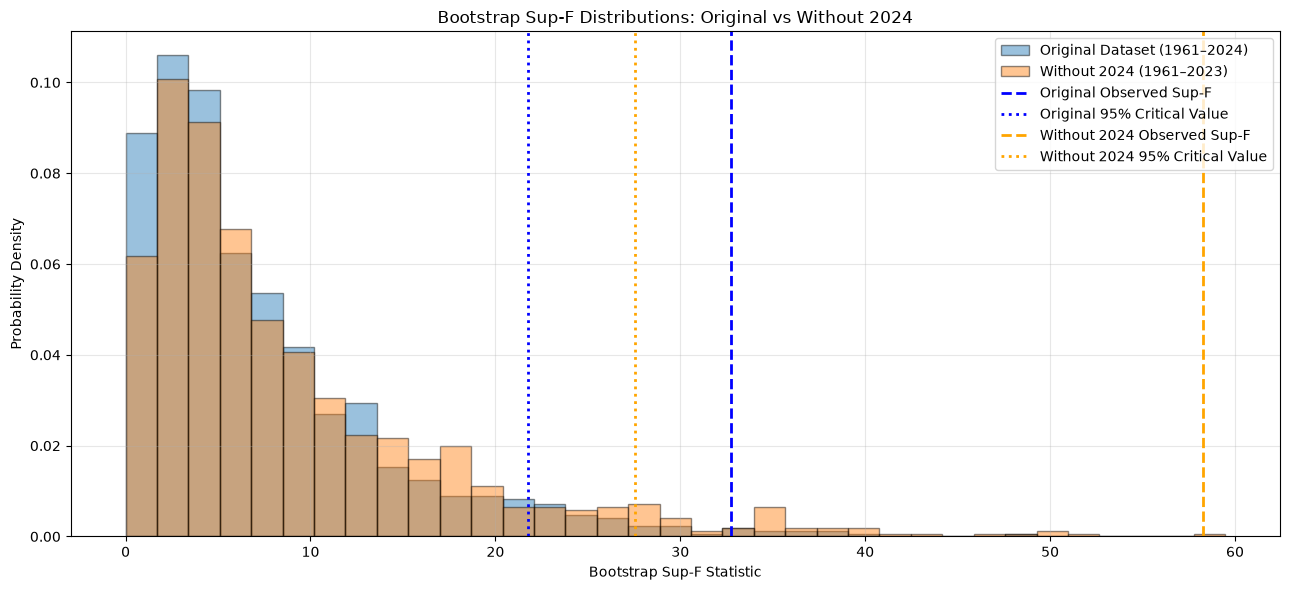

In [78]:
# Improved Bootstrap Sup-F Distribution Comparison

all_bootstrap_values = np.concatenate([
    bootstrap_sup_f,
    bootstrap_sup_f_sensitivity
])

common_bins = np.linspace(
    0,
    all_bootstrap_values.max(),
    36
)

plt.figure(figsize=(13, 6))

plt.hist(
    bootstrap_sup_f,
    bins=common_bins,
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Original Dataset (1961–2024)"
)

plt.hist(
    bootstrap_sup_f_sensitivity,
    bins=common_bins,
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Without 2024 (1961–2023)"
)

plt.axvline(
    sup_f_result["F_Statistic"],
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Original Observed Sup-F"
)

plt.axvline(
    bootstrap_critical_value,
    color="blue",
    linestyle=":",
    linewidth=2,
    label="Original 95% Critical Value"
)

plt.axvline(
    observed_sup_f_sensitivity["F_Statistic"],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Without 2024 Observed Sup-F"
)

plt.axvline(
    critical_value_sensitivity,
    color="orange",
    linestyle=":",
    linewidth=2,
    label="Without 2024 95% Critical Value"
)

plt.title("Bootstrap Sup-F Distributions: Original vs Without 2024")
plt.xlabel("Bootstrap Sup-F Statistic")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Structural Break Sensitivity Analysis: Dependent Wild Bootstrap Sup-F Distributions (1961–2024 vs. 1961–2023)

To investigate whether the detected structural change is sensitive to the influential 2024 observation, a dependent wild bootstrap Sup-F test was conducted using two datasets:

- **Original dataset:** 1961–2024, containing 64 observations.
- **Sensitivity dataset:** 1961–2023, containing 63 observations.

Both analyses used a Bartlett covariance structure with a bandwidth of 4 and 1,000 bootstrap replications.

#### Key Empirical Results

| Specification | Sample Size ($N$) | Optimal Breakpoint | Observed Sup-F | Bootstrap Mean | 95% Critical Value | Bootstrap p-value |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Original Dataset | 64 | 2002 | 32.7306 | 7.3361 | 21.7809 | 0.010989 |
| Sensitivity (Excluding 2024) | 63 | 2002 | 58.2588 | 9.0213 | 27.5352 | 0.001998 |

#### 1. Distributional Characteristics

Both bootstrap distributions exhibit right-skewness, with most simulated Sup-F statistics concentrated at relatively low values and fewer observations extending into the upper tail.

The sensitivity distribution has a higher bootstrap mean (9.0213) than the original distribution (7.3361). Its 95% critical value also increases from 21.7809 to 27.5352.

These differences indicate that excluding 2024 changes the empirical bootstrap null distribution. The distributions were plotted using identical bin edges and density scaling, allowing their relative shapes and spreads to be examined despite the different sample sizes.

#### 2. Statistical Evidence of Structural Change

For the original dataset, the observed Sup-F statistic of 32.7306 exceeds the 95% bootstrap critical value of 21.7809. Its bootstrap p-value is 0.010989, providing evidence against the null hypothesis of a single linear trend at the 5% significance level.

For the sensitivity dataset, the observed statistic increases to 58.2588, exceeding its critical value of 27.5352. The corresponding bootstrap p-value is 0.001998, also providing evidence against the null hypothesis at both the 5% and 1% significance levels.

Therefore, the evidence of structural instability remains present after excluding the 2024 observation.

#### 3. Effect of the 2024 Observation

The original segmented regression identified 2024 as an influential observation, with a Cook's distance of approximately 0.8617 and an externally studentized residual of approximately -4.5661.

Excluding this observation increases the observed Sup-F statistic from 32.7306 to 58.2588. The optimal breakpoint nevertheless remains 2002.

This indicates that the influential 2024 observation affects the fitted regression and the resulting test statistic, but its exclusion does not change the location of the best-fitting breakpoint.

However, the two p-values should not be interpreted as direct measures of model improvement. They are calculated relative to different sample-specific bootstrap null distributions.

#### 4. Consistency with Earlier Structural Break Analyses

The bootstrap results agree with several earlier findings:

- Segmented regression identified 2002 as the optimal breakpoint in both datasets.
- The RSS profile showed that 2001 and 2002 provide very similar fits.
- Leave-one-out analysis selected either 2001 or 2002, indicating stability around the early 2000s.
- Sensitivity analysis demonstrated that excluding 2024 does not change the selected breakpoint.
- The segmented regression diagnostics showed that autocorrelation and heteroscedasticity remain present.

Together, these findings support an early-2000s change in the fitted maize production trend.

#### 5. Methodological Limitations

Several limitations should be considered when interpreting the results.

1. **Bootstrap replications:** The analysis used 1,000 simulations. Although sufficient to provide an initial approximation, more replications, such as 5,000 or 10,000, would improve the precision of estimated tail probabilities and critical values. The plus-one correction gives a minimum attainable p-value of approximately 0.000999.

2. **Bandwidth selection:** The dependent wild bootstrap used a Bartlett covariance structure with a bandwidth of 4. Different bandwidth choices may produce different bootstrap distributions and critical values.

3. **Breakpoint uncertainty:** Although both datasets identify 2002, the RSS and leave-one-out analyses show that 2001 is also a competitive candidate. The selected year should therefore be interpreted as a best-fitting estimate rather than an exact, precisely established breakpoint.

4. **Model specification:** The analysis compares a single linear trend with continuous two-segment linear regression. Other forms of structural change, including multiple breaks or gradual changes in the production trend, have not been ruled out.

5. **Residual dependence:** The bootstrap procedure uses a specified dependent multiplier structure. Its validity depends on the suitability of that dependence structure and the assumptions underlying the null model.

6. **Causality:** The statistical evidence identifies a change in the production trend but does not establish its causes. Possible agricultural, economic, environmental or policy-related explanations would require separate investigation.

#### Conclusion

The dependent wild bootstrap Sup-F analysis provides statistically significant evidence against a single linear trend in Zambia's maize production series from 1961 to 2024.

The original dataset produces an observed Sup-F statistic of 32.7306 with a bootstrap p-value of 0.010989. After excluding the influential 2024 observation, the statistic increases to 58.2588, with a bootstrap p-value of 0.001998.

Importantly, both specifications identify 2002 as the optimal breakpoint. Combined with the RSS profile and leave-one-out analysis, the findings support an early-2000s change in the fitted production trend, although the precise breakpoint year remains uncertain.

The results demonstrate that the evidence of structural instability is not solely dependent on the inclusion of the 2024 observation.

The dependent wild bootstrap Sup-F test provides statistically significant evidence of structural instability in Zambia's maize production trend over the period 1961–2024. The original dataset identifies 2002 as the optimal breakpoint, with an observed Sup-F statistic of 32.7306 and a bootstrap p-value of 0.010989. Excluding the influential 2024 observation preserves the same estimated breakpoint, producing a Sup-F statistic of 58.2588 and a bootstrap p-value of 0.001998. These findings, supported by the RSS profile and leave-one-out analysis, indicate that the evidence of a change in trend is not solely driven by the 2024 observation. However, the close competition between 2001 and 2002 means that the exact breakpoint year should be interpreted cautiously. The analysis establishes statistical evidence of a departure from a single linear trend, but does not identify the causes of that change.

## Overall Statistical Findings

The analysis of Zambia's maize production from 1961 to 2024 revealed several important patterns.

1. **Long-term production trend:** Maize production generally increased over the study period, although substantial year-to-year fluctuations were observed.

2. **Production and agricultural factors:** Both harvested area and yield showed positive relationships with production. The 2023–2024 comparison indicated that the sharp production decline coincided with a substantial reduction in harvested area and a smaller reduction in yield.

3. **Linear regression:** The simple linear regression identified a statistically significant positive long-term trend. However, residual diagnostics revealed autocorrelation and heteroscedasticity, indicating limitations in the conventional regression assumptions.

4. **Segmented regression:** A continuous two-segment regression identified 2002 as the best-fitting breakpoint. The segmented model provided a better in-sample fit than the simple linear model.

5. **Structural-break robustness:** The RSS profile and leave-one-out analysis showed that 2001 and 2002 were closely competing breakpoint candidates. Excluding the influential 2024 observation did not change the selected breakpoint.

6. **Bootstrap inference:** The dependent wild bootstrap Sup-F test provided statistically significant evidence against a single linear production trend. This evidence remained present in the sensitivity analysis excluding 2024.

Overall, the findings suggest that Zambia's maize production history is better described by a changing and fluctuating trend than by a single constant linear growth pattern. However, the analysis identifies statistical relationships and changes in trends rather than establishing their underlying causes.

In [2]:
from pathlib import Path

outputs_dir = Path("../outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)

print("Output directory: - maize_analysis.ipynb:6", outputs_dir.resolve())
print("Directory exists: - maize_analysis.ipynb:7", outputs_dir.exists())

Output directory: - maize_analysis.ipynb:6 C:\Users\asus\ICD341\ICD341_Capstone\outputs
Directory exists: - maize_analysis.ipynb:7 True


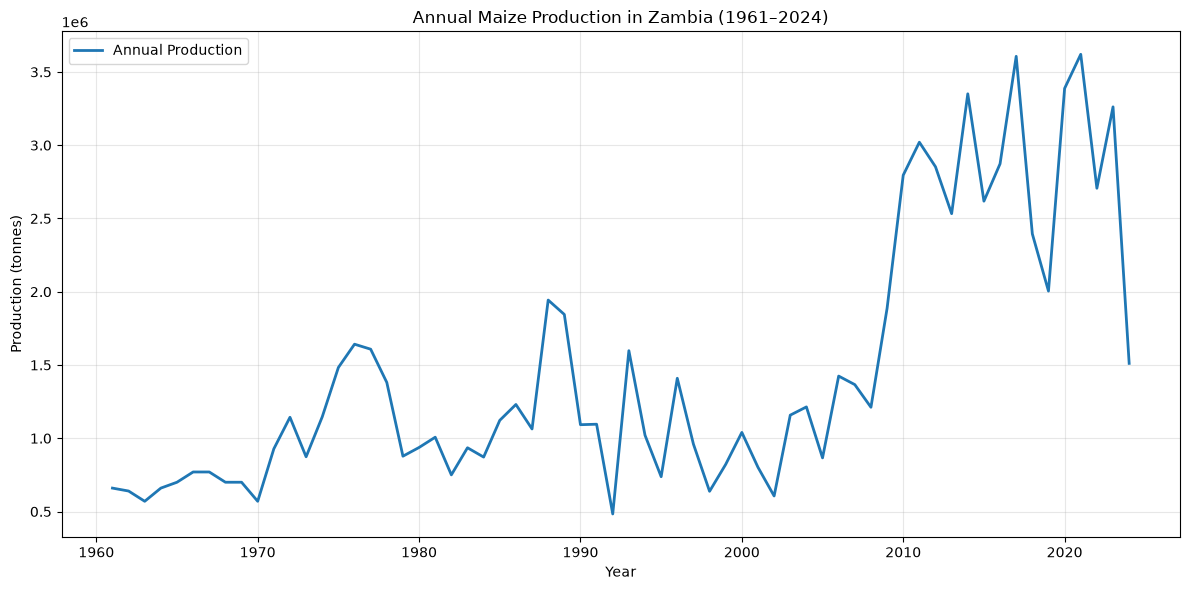

Annual production plot saved successfully. - maize_analysis.ipynb:27


In [80]:
# Save annual maize production plot

plt.figure(figsize=(12, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    linewidth=2,
    label="Annual Production"
)

plt.title("Annual Maize Production in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Production (tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    outputs_dir / "annual_maize_production.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Annual production plot saved successfully. - maize_analysis.ipynb:27")

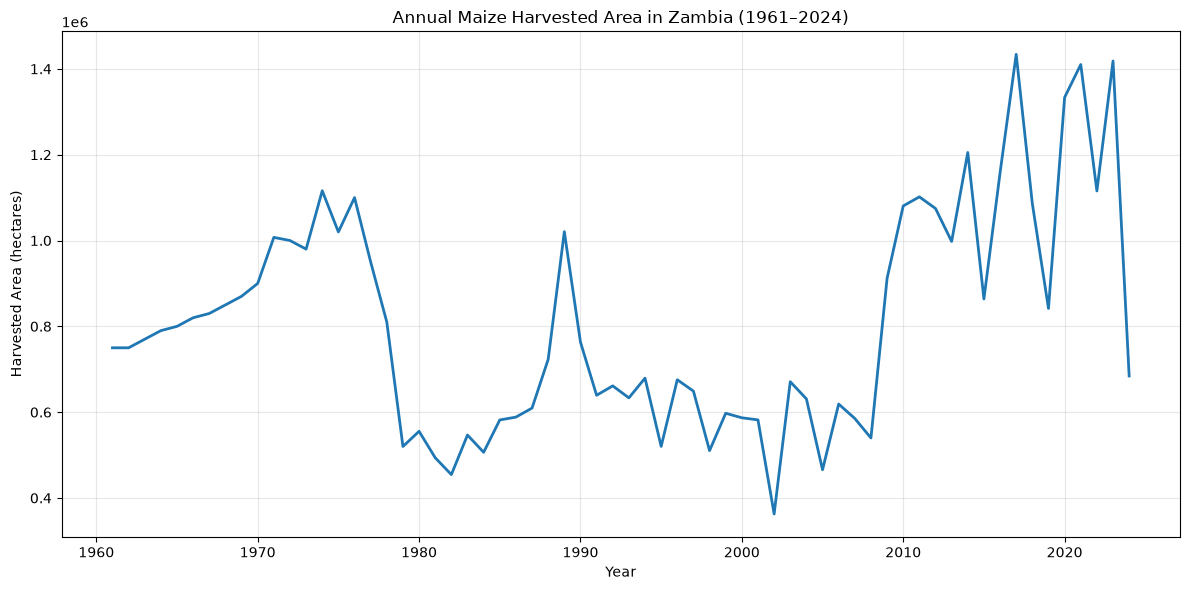

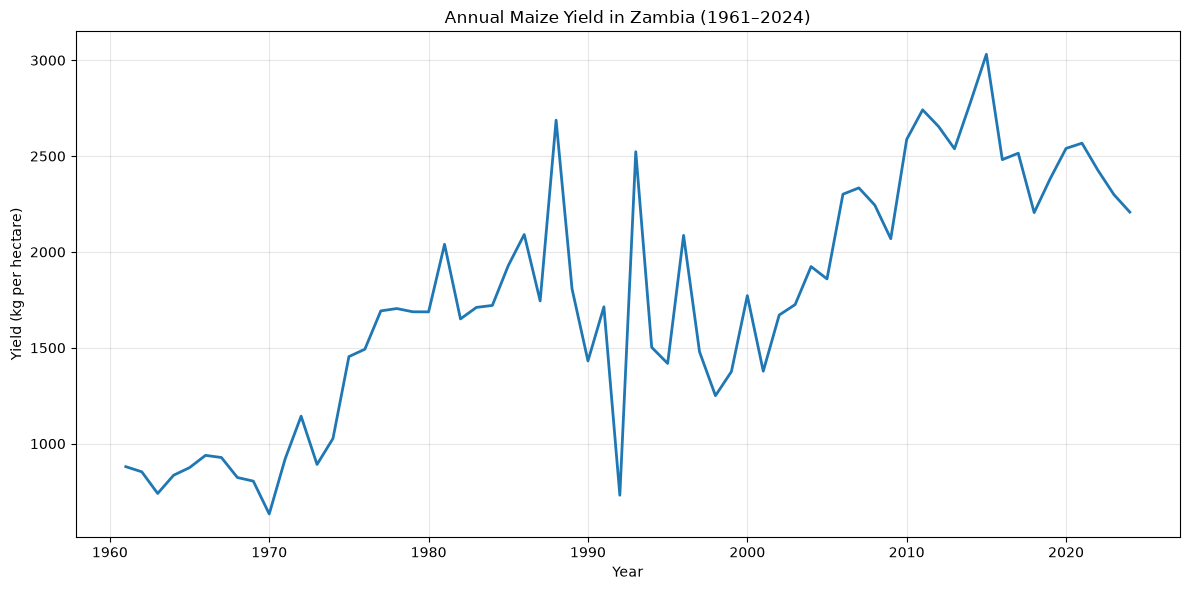

Harvested area and yield plots saved successfully. - maize_analysis.ipynb:50


In [81]:
# Save harvested area plot

plt.figure(figsize=(12, 6))

plt.plot(
    df["Year"],
    df["Area_harvested_ha"],
    linewidth=2
)

plt.title("Annual Maize Harvested Area in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Harvested Area (hectares)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    outputs_dir / "maize_harvested_area.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Save maize yield plot

plt.figure(figsize=(12, 6))

plt.plot(
    df["Year"],
    df["Yield_kg_per_ha"],
    linewidth=2
)

plt.title("Annual Maize Yield in Zambia (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Yield (kg per hectare)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    outputs_dir / "maize_yield.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Harvested area and yield plots saved successfully. - maize_analysis.ipynb:50")

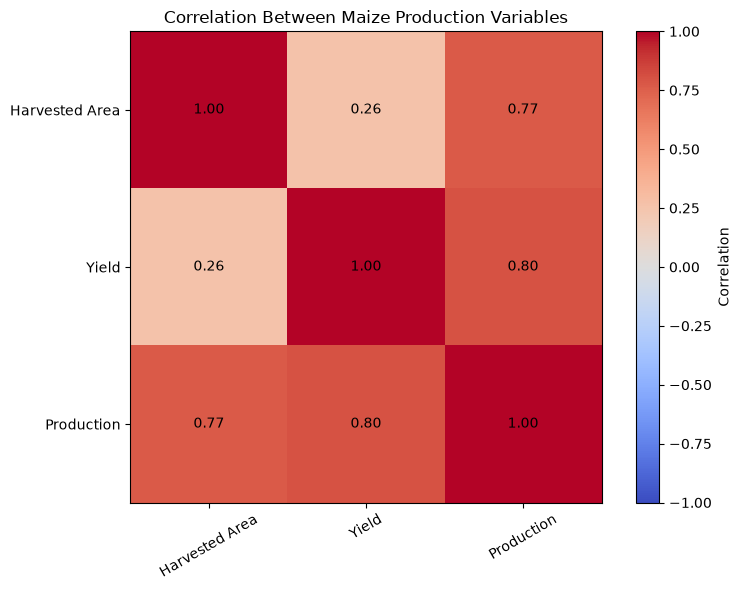

Correlation heatmap saved successfully. - maize_analysis.ipynb:50


In [82]:
# Save correlation heatmap

correlation_data = df[
    [
        "Area_harvested_ha",
        "Yield_kg_per_ha",
        "Production_tonnes"
    ]
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    ["Harvested Area", "Yield", "Production"],
    rotation=30
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    ["Harvested Area", "Yield", "Production"]
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Between Maize Production Variables")
plt.tight_layout()

plt.savefig(
    outputs_dir / "maize_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully. - maize_analysis.ipynb:50")

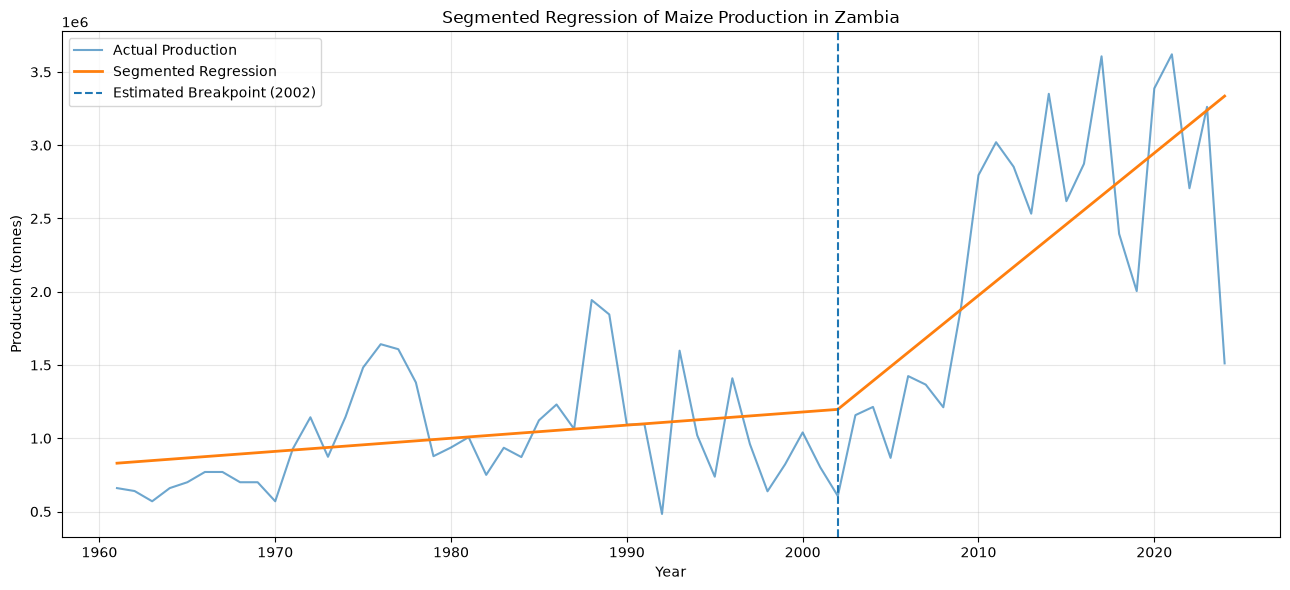

Segmented regression plot saved successfully. - maize_analysis.ipynb:40


In [83]:
# Save segmented regression plot

plt.figure(figsize=(13, 6))

plt.plot(
    df["Year"],
    df["Production_tonnes"],
    label="Actual Production",
    alpha=0.65
)

plt.plot(
    df["Year"],
    df["Segmented_Prediction"],
    label="Segmented Regression",
    linewidth=2
)

plt.axvline(
    best_result["Breakpoint"],
    linestyle="--",
    label=f"Estimated Breakpoint ({best_result['Breakpoint']})"
)

plt.title("Segmented Regression of Maize Production in Zambia")
plt.xlabel("Year")
plt.ylabel("Production (tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    outputs_dir / "segmented_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Segmented regression plot saved successfully. - maize_analysis.ipynb:40")

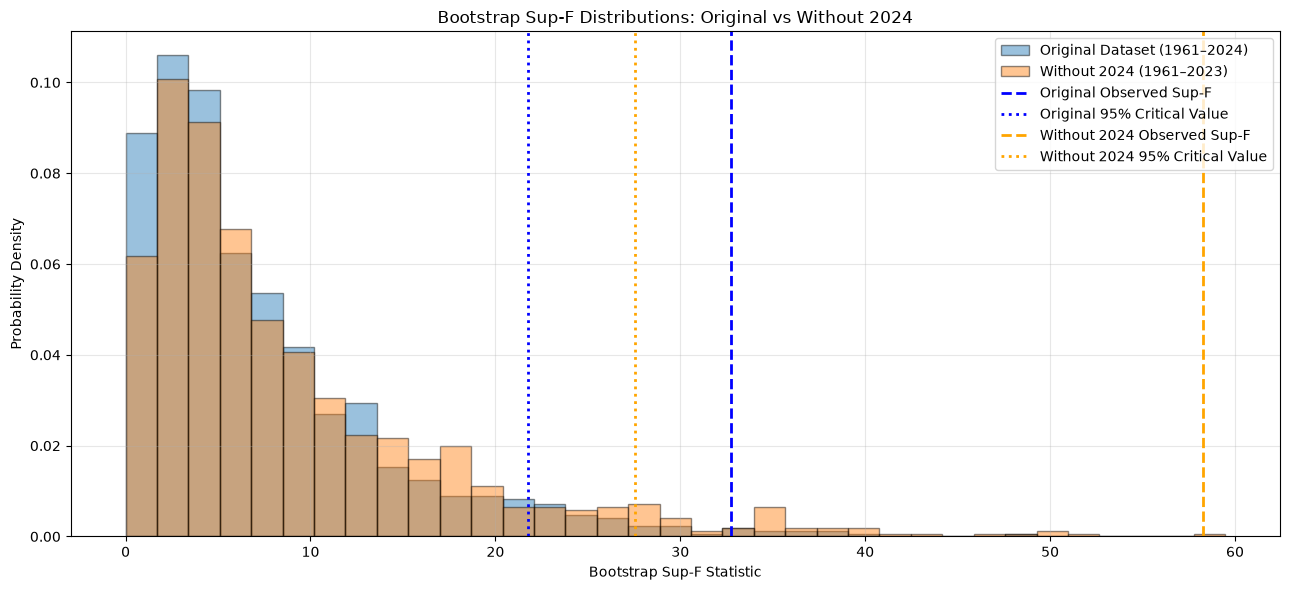

Bootstrap comparison plot saved successfully. - maize_analysis.ipynb:81


In [84]:
# Save bootstrap Sup-F distribution comparison

all_bootstrap_values = np.concatenate([
    bootstrap_sup_f,
    bootstrap_sup_f_sensitivity
])

common_bins = np.linspace(
    0,
    all_bootstrap_values.max(),
    36
)

plt.figure(figsize=(13, 6))

plt.hist(
    bootstrap_sup_f,
    bins=common_bins,
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Original Dataset (1961–2024)"
)

plt.hist(
    bootstrap_sup_f_sensitivity,
    bins=common_bins,
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Without 2024 (1961–2023)"
)

plt.axvline(
    sup_f_result["F_Statistic"],
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Original Observed Sup-F"
)

plt.axvline(
    bootstrap_critical_value,
    color="blue",
    linestyle=":",
    linewidth=2,
    label="Original 95% Critical Value"
)

plt.axvline(
    observed_sup_f_sensitivity["F_Statistic"],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Without 2024 Observed Sup-F"
)

plt.axvline(
    critical_value_sensitivity,
    color="orange",
    linestyle=":",
    linewidth=2,
    label="Without 2024 95% Critical Value"
)

plt.title("Bootstrap Sup-F Distributions: Original vs Without 2024")
plt.xlabel("Bootstrap Sup-F Statistic")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    outputs_dir / "bootstrap_sup_f_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Bootstrap comparison plot saved successfully. - maize_analysis.ipynb:81")

In [85]:
# Verify saved visualisations

saved_files = sorted(outputs_dir.glob("*.png"))

print("SAVED CAPSTONE VISUALISATIONS - maize_analysis.ipynb:5")
print("" * 40)

for file in saved_files:
    size_kb = file.stat().st_size / 1024
    print(f"{file.name}  {size_kb:.2f} KB - maize_analysis.ipynb:10")

print("\nTotal visualisations: - maize_analysis.ipynb:12", len(saved_files))

SAVED CAPSTONE VISUALISATIONS - maize_analysis.ipynb:5

annual_maize_production.png  243.69 KB - maize_analysis.ipynb:10
bootstrap_sup_f_comparison.png  187.78 KB - maize_analysis.ipynb:10
maize_correlation_heatmap.png  128.18 KB - maize_analysis.ipynb:10
maize_harvested_area.png  239.97 KB - maize_analysis.ipynb:10
maize_yield.png  225.93 KB - maize_analysis.ipynb:10
segmented_regression.png  307.61 KB - maize_analysis.ipynb:10

Total visualisations: - maize_analysis.ipynb:12 6


In [86]:
# Export descriptive statistics

descriptive_statistics = df[
    [
        "Production_tonnes",
        "Area_harvested_ha",
        "Yield_kg_per_ha"
    ]
].describe().T

descriptive_statistics.to_csv(
    outputs_dir / "descriptive_statistics.csv"
)

print("Descriptive statistics exported successfully. - maize_analysis.ipynb:15")
display(descriptive_statistics)

Descriptive statistics exported successfully. - maize_analysis.ipynb:15


,count,mean,std,min,25%,50%,75%,max
Production_tonnes,64.0,1.460921e+06,875834.043639,483492.0,817042.0,1132844.50,1855486.000,3620243.9
Area_harvested_ha,64.0,8.094339e+05,259073.951306,362787.0,595213.0,766638.50,1001832.000,1433944.0
Yield_kg_per_ha,64.0,1.752275e+03,637.469405,633.3,1344.5,1717.55,2300.025,3031.0


In [87]:
# Export correlation matrix

correlation_matrix = df[
    [
        "Area_harvested_ha",
        "Yield_kg_per_ha",
        "Production_tonnes"
    ]
].corr()

correlation_matrix.to_csv(
    outputs_dir / "correlation_matrix.csv"
)

print("Correlation matrix exported successfully. - maize_analysis.ipynb:15")
display(correlation_matrix.round(4))

Correlation matrix exported successfully. - maize_analysis.ipynb:15


,Area_harvested_ha,Yield_kg_per_ha,Production_tonnes
Area_harvested_ha,1.0000,0.2619,0.7713
Yield_kg_per_ha,0.2619,1.0000,0.8029
Production_tonnes,0.7713,0.8029,1.0000


In [88]:
# Export regression results

regression_results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Segmented Regression"
    ],
    "R_squared": [
        ols_model.rsquared,
        segmented_model.rsquared
    ],
    "Adjusted_R_squared": [
        ols_model.rsquared_adj,
        segmented_model.rsquared_adj
    ],
    "AIC": [
        ols_model.aic,
        segmented_model.aic
    ],
    "BIC": [
        ols_model.bic,
        segmented_model.bic
    ]
})

regression_results.to_csv(
    outputs_dir / "regression_results.csv",
    index=False
)

print("Regression results exported successfully. - maize_analysis.ipynb:31")
display(regression_results.round(4))

Regression results exported successfully. - maize_analysis.ipynb:31


,Model,R_squared,Adjusted_R_squared,AIC,BIC
0,Simple Linear Regression,0.5223,0.5146,1888.7474,1893.0651
1,Segmented Regression,0.6891,0.6789,1863.2561,1869.7328


In [89]:
# Export structural-break bootstrap results

bootstrap_results = pd.DataFrame({
    "Dataset": [
        "Original (1961–2024)",
        "Without 2024 (1961–2023)"
    ],
    "Observations": [64, 63],
    "Optimal_Breakpoint": [2002, 2002],
    "Observed_Sup_F": [32.7306, 58.2588],
    "Bootstrap_Mean": [7.3361, 9.0213],
    "Critical_Value_95": [21.7809, 27.5352],
    "Bootstrap_P_Value": [0.010989, 0.001998]
})

bootstrap_results.to_csv(
    outputs_dir / "structural_break_results.csv",
    index=False
)

print("Structuralbreak results exported successfully. - maize_analysis.ipynb:21")
display(bootstrap_results)

Structuralbreak results exported successfully. - maize_analysis.ipynb:21


,Dataset,Observations,Optimal_Breakpoint,Observed_Sup_F,Bootstrap_Mean,Critical_Value_95,Bootstrap_P_Value
0,Original (1961–2024),64,2002,32.7306,7.3361,21.7809,0.010989
1,Without 2024 (1961–2023),63,2002,58.2588,9.0213,27.5352,0.001998


In [90]:
# Verify exported capstone outputs

print("CAPSTONE OUTPUT FILES - maize_analysis.ipynb:3")
print("" * 45)

for file in sorted(outputs_dir.iterdir()):
    if file.is_file():
        size_kb = file.stat().st_size / 1024
        print(f"{file.name:<40} {size_kb:>8.2f} KB - maize_analysis.ipynb:9")

print("" * 45)
print("Total files: - maize_analysis.ipynb:12", len(list(outputs_dir.iterdir())))

CAPSTONE OUTPUT FILES - maize_analysis.ipynb:3

annual_maize_production.png                243.69 KB - maize_analysis.ipynb:9
bootstrap_sup_f_comparison.png             187.78 KB - maize_analysis.ipynb:9
correlation_matrix.csv                       0.23 KB - maize_analysis.ipynb:9
descriptive_statistics.csv                   0.33 KB - maize_analysis.ipynb:9
maize_correlation_heatmap.png              128.18 KB - maize_analysis.ipynb:9
maize_harvested_area.png                   239.97 KB - maize_analysis.ipynb:9
maize_yield.png                            225.93 KB - maize_analysis.ipynb:9
regression_results.csv                       0.24 KB - maize_analysis.ipynb:9
segmented_regression.png                   307.61 KB - maize_analysis.ipynb:9
structural_break_results.csv                 0.23 KB - maize_analysis.ipynb:9

Total files: - maize_analysis.ipynb:12 10


In [1]:
from pathlib import Path

print("Current working directory: - maize_analysis.ipynb:3", Path.cwd())
print("Output directory: - maize_analysis.ipynb:4", Path("../../outputs").resolve())
print("Output directory exists: - maize_analysis.ipynb:5", Path("../../outputs").exists())

Current working directory: - maize_analysis.ipynb:3 c:\Users\asus\ICD341\ICD341_Capstone\notebooks
Output directory: - maize_analysis.ipynb:4 C:\Users\asus\ICD341\outputs
Output directory exists: - maize_analysis.ipynb:5 False
